
# Cyclistic Bike-Share Analysis



## Stage 1: Ask

### Business Scenario
Cyclistic is a bike-share company operating in Chicago. It offers annual memberships and casual ride passes. The marketing team wants to understand how these two customer groups use the service differently to identify opportunities for converting casual riders into annual members.

### Business Task
Determine how annual members and casual riders use Cyclistic bikes differently and identify evidence-based opportunities to improve casual-to-member conversion.

### Analytical Questions
1. How does overall ride activity differ between casual riders and members?
2. How do riding patterns change across months and seasons?
3. How does usage differ between weekdays and weekends?
4. How do ride durations compare?
5. Do rider groups show different bike-type preferences?
6. How do starting stations, ending stations and routes differ?
7. What additional behavioural patterns could inform membership marketing?

### Assumptions and Limitations
- Each record represents a trip, not necessarily a unique customer.
- Trip data cannot independently establish customer motivations or membership purchase intentions.
- Observed associations should not be presented as proof of causation.
- Missing or incomplete records must be evaluated before drawing conclusions.
- Recommendations must reflect the available evidence and its limitations.

### Definition of Success
Produce a reproducible, documented analysis with validated findings, meaningful visualizations and practical recommendations that address Cyclistic's membership-conversion objective.


# Stage 2: Prepare

## Dataset Description
The project uses 12 monthly Divvy bike-share trip-data archives covering October 2025 through September 2026.

## Dataset Structure
The original dataset contains 13 columns:

- ride_id
- rideable_type
- started_at
- ended_at
- start_station_name
- end_station_name
- start_station_id
- end_station_id
- start_lat
- start_lng
- end_lat
- end_lng
- member_casual

## Data Sources
The 12 original monthly ZIP archives are stored in the project's data/raw directory. Original source archives will remain unchanged throughout the analysis.

## Reporting Period
The intended reporting period is:
- Start: 1 October 2025 (inclusive)
- End: 1 October 2026 (exclusive)

The reporting period will be determined using the actual started_at timestamp, not archive filenames.

## Preparation Objectives
1. Verify the source files and their integrity.
2. Confirm the structure and consistency of all monthly datasets.
3. Examine date coverage and reporting-period boundaries.
4. Identify missing values and duplicate records.
5. Investigate invalid timestamps and unusual trip durations.
6. Document data limitations and analytical assumptions.

## Data Protection
Original ZIP archives will not be modified. All processed datasets and derived analytical fields will be saved separately.


In [1]:

from pathlib import Path
import platform
import sys

# Project directories
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REFERENCE_DIR = PROJECT_DIR / "data" / "reference"
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"
SCRIPTS_DIR = PROJECT_DIR / "scripts"
VISUALIZATION_DIR = PROJECT_DIR / "visualizations"

# Environment information
print("PYTHON VERSION:", sys.version.split()[0])
print("OPERATING SYSTEM:", platform.system(), platform.release())

# Project verification
print("\nPROJECT DIRECTORY:", PROJECT_DIR)
print("PROJECT EXISTS:", PROJECT_DIR.exists())

# Folder verification
print("\nPROJECT FOLDERS")

for folder in [
    RAW_DIR,
    PROCESSED_DIR,
    REFERENCE_DIR,
    NOTEBOOK_DIR,
    SCRIPTS_DIR,
    VISUALIZATION_DIR
]:
    print(f"{folder.name}: {folder.exists()}")

# Original archive inventory
archives = sorted(RAW_DIR.glob("*.zip"))

print("\nNUMBER OF ZIP ARCHIVES:", len(archives))

total_size = 0

for archive in archives:
    size = archive.stat().st_size
    total_size += size
    print(f"{archive.name}: {size / (1024 ** 2):.2f} MB")

print(f"\nTOTAL ARCHIVE SIZE: {total_size / (1024 ** 2):.2f} MB")

PYTHON VERSION: 3.11.18
OPERATING SYSTEM: Windows 10

PROJECT DIRECTORY: [project directory]
PROJECT EXISTS: True

PROJECT FOLDERS
raw: True
processed: True
reference: True
notebooks: True
scripts: True
visualizations: True

NUMBER OF ZIP ARCHIVES: 12
202510-divvy-tripdata.zip: 23.47 MB
202511-divvy-tripdata.zip: 12.96 MB
202512-divvy-tripdata.zip: 5.44 MB
202601-divvy-tripdata.zip: 5.63 MB
202602-divvy-tripdata.zip: 7.82 MB
202603-divvy-tripdata.zip: 12.56 MB
202604-divvy-tripdata.zip: 16.28 MB
202605-divvy-tripdata.zip: 23.78 MB
202606-divvy-tripdata.zip: 27.15 MB
202607-divvy-tripdata.zip: 31.39 MB
202608-divvy-tripdata.zip: 31.10 MB
202609-divvy-tripdata.zip: 28.17 MB

TOTAL ARCHIVE SIZE: 225.74 MB


In [2]:

import zipfile

integrity_results = []

for archive in archives:
    try:
        with zipfile.ZipFile(archive, "r") as zip_file:
            bad_file = zip_file.testzip()

        status = "PASS" if bad_file is None else "FAILED"

        integrity_results.append({
            "archive": archive.name,
            "status": status,
            "problem_file": bad_file
        })

    except Exception as error:
        integrity_results.append({
            "archive": archive.name,
            "status": "ERROR",
            "problem_file": str(error)
        })

for result in integrity_results:
    print(
        f"{result['archive']} — {result['status']}"
    )

print("\nTOTAL ARCHIVES:", len(integrity_results))
print(
    "PASSED:",
    sum(r["status"] == "PASS" for r in integrity_results)
)
print(
    "FAILED:",
    sum(r["status"] == "FAILED" for r in integrity_results)
)
print(
    "ERRORS:",
    sum(r["status"] == "ERROR" for r in integrity_results)
)


202510-divvy-tripdata.zip — PASS
202511-divvy-tripdata.zip — PASS
202512-divvy-tripdata.zip — PASS
202601-divvy-tripdata.zip — PASS
202602-divvy-tripdata.zip — PASS
202603-divvy-tripdata.zip — PASS
202604-divvy-tripdata.zip — PASS
202605-divvy-tripdata.zip — PASS
202606-divvy-tripdata.zip — PASS
202607-divvy-tripdata.zip — PASS
202608-divvy-tripdata.zip — PASS
202609-divvy-tripdata.zip — PASS

TOTAL ARCHIVES: 12
PASSED: 12
FAILED: 0
ERRORS: 0


All 12 original ZIP archives were tested using Python's ZIP integrity verification. Every archive passed, with zero corrupted files and zero errors. The source archives are readable and suitable for further inspection.

In [3]:

import zipfile
from pathlib import Path

archive_contents = []

for archive in archives:
    with zipfile.ZipFile(archive, "r") as zip_file:

        csv_files = [
            name for name in zip_file.namelist()
            if name.lower().endswith(".csv")
            and not name.startswith("__MACOSX/")
            and not Path(name).name.startswith("._")
        ]

        archive_contents.append({
            "archive": archive.name,
            "csv_count": len(csv_files),
            "csv_file": csv_files[0] if len(csv_files) == 1 else csv_files
        })

for item in archive_contents:
    print("ARCHIVE:", item["archive"])
    print("CSV COUNT:", item["csv_count"])
    print("CSV FILE:", item["csv_file"])
    print("-" * 60)

print("TOTAL ARCHIVES:", len(archive_contents))
print(
    "ARCHIVES WITH EXACTLY ONE CSV:",
    sum(item["csv_count"] == 1 for item in archive_contents)
)


ARCHIVE: 202510-divvy-tripdata.zip
CSV COUNT: 1
CSV FILE: 202510-divvy-tripdata.csv
------------------------------------------------------------
ARCHIVE: 202511-divvy-tripdata.zip
CSV COUNT: 1
CSV FILE: 202511-divvy-tripdata.csv
------------------------------------------------------------
ARCHIVE: 202512-divvy-tripdata.zip
CSV COUNT: 1
CSV FILE: 202512-divvy-tripdata.csv
------------------------------------------------------------
ARCHIVE: 202601-divvy-tripdata.zip
CSV COUNT: 1
CSV FILE: 202501-divvy-tripdata.csv
------------------------------------------------------------
ARCHIVE: 202602-divvy-tripdata.zip
CSV COUNT: 1
CSV FILE: 202602-divvy-tripdata.csv
------------------------------------------------------------
ARCHIVE: 202603-divvy-tripdata.zip
CSV COUNT: 1
CSV FILE: 202603-divvy-tripdata.csv
------------------------------------------------------------
ARCHIVE: 202604-divvy-tripdata.zip
CSV COUNT: 1
CSV FILE: 202604-divvy-tripdata.csv
----------------------------------------------

Each of the 12 ZIP archives contains exactly one relevant CSV file. The January 2026 archive contains an internal filename labelled 202501 rather than 202601. This anomaly is documented, and the original archive and CSV filename will remain unchanged.

In [4]:

import pandas as pd
import zipfile

monthly_schemas = {}
monthly_samples = {}

for archive in archives:

    with zipfile.ZipFile(archive, "r") as zip_file:

        csv_file = next(
            item["csv_file"]
            for item in archive_contents
            if item["archive"] == archive.name
        )

        with zip_file.open(csv_file) as file:
            sample = pd.read_csv(file, nrows=2)

        monthly_schemas[archive.name] = list(sample.columns)
        monthly_samples[archive.name] = sample

        print("\nARCHIVE:", archive.name)
        print("CSV:", csv_file)
        print("NUMBER OF COLUMNS:", len(sample.columns))
        print("COLUMN NAMES:")
        print(list(sample.columns))
        print("\nFIRST TWO RECORDS:")
        display(sample)

print("\nINSPECTION COMPLETE")
print("ARCHIVES INSPECTED:", len(monthly_schemas))



ARCHIVE: 202510-divvy-tripdata.zip
CSV: 202510-divvy-tripdata.csv
NUMBER OF COLUMNS: 13
COLUMN NAMES:
['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']

FIRST TWO RECORDS:


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,AAED255E1310E516,classic_bike,2025-10-27 08:19:53.208,2025-10-27 08:25:53.481,Wells St & Polk St,CHI00606,Franklin St & Washington St,CHI02074,41.872732,-87.633516,41.883180,-87.635110,member
1,F90C86BF3BB85040,classic_bike,2025-10-14 07:42:55.465,2025-10-14 08:04:08.663,Racine Ave & Wrightwood Ave,CHI00506,McClurg Ct & Ohio St,CHI00330,41.928887,-87.658971,41.892592,-87.617289,member



ARCHIVE: 202511-divvy-tripdata.zip
CSV: 202511-divvy-tripdata.csv
NUMBER OF COLUMNS: 13
COLUMN NAMES:
['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']

FIRST TWO RECORDS:


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E555D9F8E9C2F56B,electric_bike,2025-11-04 00:09:07.792,2025-11-04 00:15:04.661,NaN,NaN,NaN,NaN,41.94,-87.67,41.94,-87.67,casual
1,EAEBE70DBF015886,electric_bike,2025-11-04 14:32:09.067,2025-11-04 14:36:43.998,NaN,NaN,NaN,NaN,41.90,-87.64,41.91,-87.64,casual



ARCHIVE: 202512-divvy-tripdata.zip
CSV: 202512-divvy-tripdata.csv
NUMBER OF COLUMNS: 13
COLUMN NAMES:
['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']

FIRST TWO RECORDS:


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,D90034EFC7235A41,electric_bike,2025-12-22 17:20:27.872,2025-12-22 17:27:29.937,Broadway & Berwyn Ave,CHI00414,Broadway & Sunnyside Ave,CHI02089,41.978361,-87.659789,41.963419,-87.656069,member
1,B005230EE77A29D0,classic_bike,2025-12-20 17:15:31.749,2025-12-20 17:20:07.746,Sheridan Rd & Montrose Ave,CHI00290,Broadway & Sheridan Rd,CHI00476,41.961670,-87.654640,41.952833,-87.649993,member


... (15 outputs left out)

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,B68574B42AE9F00F,electric_bike,2026-08-04 22:08:17.594,2026-08-04 22:28:42.843,NaN,NaN,NaN,NaN,41.91,-87.68,41.96,-87.68,member
1,32BE64BBA89A6249,electric_bike,2026-08-05 16:37:39.518,2026-08-05 16:52:01.740,NaN,NaN,NaN,NaN,41.92,-87.64,41.90,-87.64,member



ARCHIVE: 202609-divvy-tripdata.zip
CSV: 202609-divvy-tripdata.csv
NUMBER OF COLUMNS: 13
COLUMN NAMES:
['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']

FIRST TWO RECORDS:


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,B3C076B2D6BAC911,electric_bike,2026-09-01 19:28:37.087,2026-09-01 19:33:03.047,NaN,NaN,NaN,NaN,41.87,-87.67,41.87,-87.66,member
1,468834E54297FB3F,electric_bike,2026-09-24 20:38:01.486,2026-09-24 20:44:54.382,NaN,NaN,NaN,NaN,41.91,-87.70,41.90,-87.71,member



INSPECTION COMPLETE
ARCHIVES INSPECTED: 12


In [5]:

# Use October 2025 as the reference schema
reference_archive = "202510-divvy-tripdata.zip"
reference_columns = monthly_schemas[reference_archive]

schema_results = []

for archive_name, columns in monthly_schemas.items():

    matches = columns == reference_columns

    schema_results.append({
        "archive": archive_name,
        "column_count": len(columns),
        "matches_reference": matches,
        "missing_columns": sorted(
            set(reference_columns) - set(columns)
        ),
        "extra_columns": sorted(
            set(columns) - set(reference_columns)
        )
    })

schema_df = pd.DataFrame(schema_results)

print("REFERENCE ARCHIVE:", reference_archive)
print("REFERENCE COLUMN COUNT:", len(reference_columns))

display(schema_df)

print("\nTOTAL FILES:", len(schema_df))
print(
    "SCHEMA MATCHES:",
    schema_df["matches_reference"].sum()
)
print(
    "SCHEMA MISMATCHES:",
    (~schema_df["matches_reference"]).sum()
)

assert schema_df["matches_reference"].all(), (
    "Schema mismatch detected. Investigate before proceeding."
)

print("\nPASS: All 12 monthly files have identical column names and order.")


REFERENCE ARCHIVE: 202510-divvy-tripdata.zip
REFERENCE COLUMN COUNT: 13


,archive,column_count,matches_reference,missing_columns,extra_columns
0,202510-divvy-tripdata.zip,13,True,[],[]
1,202511-divvy-tripdata.zip,13,True,[],[]
2,202512-divvy-tripdata.zip,13,True,[],[]
3,202601-divvy-tripdata.zip,13,True,[],[]
4,202602-divvy-tripdata.zip,13,True,[],[]
5,202603-divvy-tripdata.zip,13,True,[],[]
6,202604-divvy-tripdata.zip,13,True,[],[]
7,202605-divvy-tripdata.zip,13,True,[],[]
8,202606-divvy-tripdata.zip,13,True,[],[]
9,202607-divvy-tripdata.zip,13,True,[],[]



TOTAL FILES: 12
SCHEMA MATCHES: 12
SCHEMA MISMATCHES: 0

PASS: All 12 monthly files have identical column names and order.


Formal schema validation used the October 2025 archive as the reference. All 12 monthly files matched its 13-column structure exactly. No missing or additional columns were detected.

In [6]:

date_audit_results = []

CHUNK_SIZE = 100_000

for archive in archives:

    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    record_count = 0
    invalid_dates = 0
    earliest_date = None
    latest_date = None

    with zipfile.ZipFile(archive, "r") as zip_file:

        with zip_file.open(csv_file) as file:

            for chunk in pd.read_csv(
                file,
                usecols=["started_at"],
                chunksize=CHUNK_SIZE,
                dtype={"started_at": "string"}
            ):

                record_count += len(chunk)

                parsed_dates = pd.to_datetime(
                    chunk["started_at"],
                    errors="coerce"
                )

                invalid_dates += int(parsed_dates.isna().sum())

                chunk_min = parsed_dates.min()
                chunk_max = parsed_dates.max()

                if pd.notna(chunk_min):
                    if earliest_date is None or chunk_min < earliest_date:
                        earliest_date = chunk_min

                if pd.notna(chunk_max):
                    if latest_date is None or chunk_max > latest_date:
                        latest_date = chunk_max

    date_audit_results.append({
        "archive": archive.name,
        "csv_file": csv_file,
        "record_count": record_count,
        "earliest_start": earliest_date,
        "latest_start": latest_date,
        "invalid_start_dates": invalid_dates
    })

date_audit_df = pd.DataFrame(date_audit_results)

display(date_audit_df)

print("\nTOTAL RECORDS:", date_audit_df["record_count"].sum())
print(
    "TOTAL INVALID START DATES:",
    date_audit_df["invalid_start_dates"].sum()
)


,archive,csv_file,record_count,earliest_start,latest_start,invalid_start_dates
0,202510-divvy-tripdata.zip,202510-divvy-tripdata.csv,646039,2025-09-30 08:37:53.455,2025-10-31 23:56:47.949,0
1,202511-divvy-tripdata.zip,202511-divvy-tripdata.csv,356628,2025-10-31 01:24:38.549,2025-11-30 23:51:43.800,0
2,202512-divvy-tripdata.zip,202512-divvy-tripdata.csv,140534,2025-11-30 16:02:08.178,2025-12-31 23:53:24.274,0
3,202601-divvy-tripdata.zip,202501-divvy-tripdata.csv,137787,2025-12-31 10:30:49.482,2026-01-31 23:56:54.069,0
4,202602-divvy-tripdata.zip,202602-divvy-tripdata.csv,201450,2026-01-31 11:08:07.830,2026-02-28 23:57:54.093,0
5,202603-divvy-tripdata.zip,202603-divvy-tripdata.csv,317037,2026-02-28 10:48:22.074,2026-03-31 23:55:56.848,0
6,202604-divvy-tripdata.zip,202604-divvy-tripdata.csv,448252,2026-04-01 00:01:42.066,2026-04-30 23:58:56.151,0
7,202605-divvy-tripdata.zip,202605-divvy-tripdata.csv,653704,2026-04-30 00:24:47.685,2026-05-31 23:57:08.778,0
8,202606-divvy-tripdata.zip,202606-divvy-tripdata.csv,762550,2026-05-31 01:07:54.969,2026-06-30 23:58:47.113,0
9,202607-divvy-tripdata.zip,202607-divvy-tripdata.csv,869051,2026-06-29 23:11:19.957,2026-07-31 23:58:05.898,0



TOTAL RECORDS: 6171785
TOTAL INVALID START DATES: 0



### Date coverage and reporting-period boundaries

The 12 source archives contain 6,171,785 records. All `started_at` values were successfully parsed, with no invalid start timestamps.

The archive contents are not perfectly restricted to their labelled months. Some files contain trips that began on the final day of the preceding month. Therefore, the reporting period is defined by the actual trip start timestamp:

- Start: 1 October 2025, inclusive.
- End: 1 October 2026, exclusive.

The January 2026 archive also contains a CSV with a mismatched filename (`202501-divvy-tripdata.csv`). Its recorded dates are consistent with the January 2026 reporting period. The original source file will remain unchanged.

Records outside the reporting period will be retained in the source data but excluded from the reporting-period analytical population.

In [7]:

REPORT_START = pd.Timestamp("2025-10-01")
REPORT_END = pd.Timestamp("2026-10-01")

period_audit_results = []

for archive in archives:
    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    total_records = 0
    in_period_records = 0
    before_period_records = 0
    after_period_records = 0

    with zipfile.ZipFile(archive, "r") as zip_file:
        with zip_file.open(csv_file) as file:
            for chunk in pd.read_csv(
                file,
                usecols=["started_at"],
                chunksize=CHUNK_SIZE,
                dtype={"started_at": "string"}
            ):
                dates = pd.to_datetime(
                    chunk["started_at"],
                    errors="coerce"
                )

                total_records += len(chunk)

                in_period = (
                    (dates >= REPORT_START) &
                    (dates < REPORT_END)
                )

                before_period = dates < REPORT_START
                after_period = dates >= REPORT_END

                in_period_records += int(in_period.sum())
                before_period_records += int(before_period.sum())
                after_period_records += int(after_period.sum())

    period_audit_results.append({
        "archive": archive.name,
        "total_records": total_records,
        "in_reporting_period": in_period_records,
        "before_reporting_period": before_period_records,
        "on_or_after_end_date": after_period_records
    })

period_audit_df = pd.DataFrame(period_audit_results)

display(period_audit_df)

print("TOTAL SOURCE RECORDS:", period_audit_df["total_records"].sum())
print("IN REPORTING PERIOD:", period_audit_df["in_reporting_period"].sum())
print("BEFORE REPORTING PERIOD:", period_audit_df["before_reporting_period"].sum())
print("ON OR AFTER END DATE:", period_audit_df["on_or_after_end_date"].sum())

assert (
    period_audit_df["total_records"].sum()
    ==
    period_audit_df[
        ["in_reporting_period", "before_reporting_period", "on_or_after_end_date"]
    ].to_numpy().sum()
)

print("\nPASS: Every source record has been accounted for.")

,archive,total_records,in_reporting_period,before_reporting_period,on_or_after_end_date
0,202510-divvy-tripdata.zip,646039,645968,71,0
1,202511-divvy-tripdata.zip,356628,356628,0,0
2,202512-divvy-tripdata.zip,140534,140534,0,0
3,202601-divvy-tripdata.zip,137787,137787,0,0
4,202602-divvy-tripdata.zip,201450,201450,0,0
5,202603-divvy-tripdata.zip,317037,317037,0,0
6,202604-divvy-tripdata.zip,448252,448252,0,0
7,202605-divvy-tripdata.zip,653704,653704,0,0
8,202606-divvy-tripdata.zip,762550,762550,0,0
9,202607-divvy-tripdata.zip,869051,869051,0,0


TOTAL SOURCE RECORDS: 6171785
IN REPORTING PERIOD: 6171714
BEFORE REPORTING PERIOD: 71
ON OR AFTER END DATE: 0

PASS: Every source record has been accounted for.


### Date Coverage and Reporting-Period Validation

All 12 source archives were audited using the `started_at` field. A total of 6,171,785 records were identified, with no invalid start timestamps.

The defined reporting period is 1 October 2025 through 30 September 2026, inclusive. Based on actual start dates:

- 6,171,714 records fall within the reporting period.
- 71 records started before the reporting period, on 30 September 2025.
- No records started on or after 1 October 2026.
- Every source record was accounted for.

Some archives contain records whose start dates fall in the preceding calendar month. Therefore, archive filenames will not be used as the basis for assigning reporting months or filtering the reporting period.

The January 2026 archive contains a CSV with a 202501 filename. Its timestamp audit confirms that the records belong to the expected January 2026 period. The original source filename will be preserved.

**Decision:** Reporting-period inclusion will be determined exclusively by `started_at`, using 1 October 2025 inclusive and 1 October 2026 exclusive. The 71 out-of-period records will be excluded from reporting-period analysis but retained in the source data.

In [8]:
monthly_coverage_results = []

for archive in archives:
    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    archive_month_counts = {}

    with zipfile.ZipFile(archive, "r") as zip_file:
        with zip_file.open(csv_file) as file:
            for chunk in pd.read_csv(
                file,
                usecols=["started_at"],
                chunksize=CHUNK_SIZE,
                dtype={"started_at": "string"}
            ):
                dates = pd.to_datetime(
                    chunk["started_at"],
                    errors="coerce"
                )

                month_counts = (
                    dates.dropna()
                    .dt.to_period("M")
                    .value_counts()
                )

                for month, count in month_counts.items():
                    archive_month_counts[month] = (
                        archive_month_counts.get(month, 0) + int(count)
                    )

    for month, count in sorted(archive_month_counts.items()):
        monthly_coverage_results.append({
            "archive": archive.name,
            "actual_start_month": str(month),
            "record_count": count
        })

monthly_coverage_df = pd.DataFrame(monthly_coverage_results)

monthly_coverage_pivot = monthly_coverage_df.pivot(
    index="archive",
    columns="actual_start_month",
    values="record_count"
).fillna(0).astype("int64")

display(monthly_coverage_pivot)

print(
    "\nTOTAL RECORDS IN MONTHLY DISTRIBUTION:",
    int(monthly_coverage_pivot.to_numpy().sum())
)

actual_start_month,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
archive,,,,,,,,,,,,,
202510-divvy-tripdata.zip,71,645968,0,0,0,0,0,0,0,0,0,0,0
202511-divvy-tripdata.zip,0,128,356500,0,0,0,0,0,0,0,0,0,0
202512-divvy-tripdata.zip,0,0,12,140522,0,0,0,0,0,0,0,0,0
202601-divvy-tripdata.zip,0,0,0,23,137764,0,0,0,0,0,0,0,0
202602-divvy-tripdata.zip,0,0,0,0,18,201432,0,0,0,0,0,0,0
202603-divvy-tripdata.zip,0,0,0,0,0,22,317015,0,0,0,0,0,0
202604-divvy-tripdata.zip,0,0,0,0,0,0,0,448252,0,0,0,0,0
202605-divvy-tripdata.zip,0,0,0,0,0,0,0,35,653669,0,0,0,0
202606-divvy-tripdata.zip,0,0,0,0,0,0,0,0,78,762472,0,0,0



TOTAL RECORDS IN MONTHLY DISTRIBUTION: 6171785


### Monthly Date Distribution and Archive Boundaries

The monthly distribution audit accounted for all 6,171,785 source records.

All 12 expected reporting months, October 2025 through September 2026, are represented. However, several archives contain records whose actual start month precedes the month indicated by the archive filename.

A total of 513 records fall into preceding calendar months across the archives, while 71 records in the October 2025 archive started in September 2025 and are outside the reporting period.

**Decision:** The combined dataset will use the actual `started_at` timestamp to derive reporting months. Archive filenames will be retained as source metadata, not treated as definitive date classifications.

In [9]:
import sqlite3

duplicate_audit_path = PROCESSED_DIR / "_temporary_duplicate_audit.sqlite"

if duplicate_audit_path.exists():
    duplicate_audit_path.unlink()

connection = sqlite3.connect(duplicate_audit_path)

connection.execute("""
    CREATE TABLE ride_ids (
        ride_id TEXT
    )
""")

for archive in archives:
    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    with zipfile.ZipFile(archive, "r") as zip_file:
        with zip_file.open(csv_file) as file:
            for chunk in pd.read_csv(
                file,
                usecols=["ride_id"],
                chunksize=CHUNK_SIZE,
                dtype={"ride_id": "string"}
            ):
                connection.executemany(
                    "INSERT INTO ride_ids (ride_id) VALUES (?)",
                    [(value,) for value in chunk["ride_id"]]
                )

    connection.commit()

duplicate_summary = connection.execute("""
    SELECT
        COUNT(*) AS total_ids,
        COUNT(DISTINCT ride_id) AS unique_ids,
        COUNT(*) - COUNT(DISTINCT ride_id) AS duplicate_occurrences
    FROM ride_ids
""").fetchone()

duplicate_id_groups = connection.execute("""
    SELECT
        ride_id,
        COUNT(*) AS occurrences
    FROM ride_ids
    GROUP BY ride_id
    HAVING COUNT(*) > 1
    ORDER BY occurrences DESC, ride_id
""").fetchall()

print("TOTAL RIDE IDs:", duplicate_summary[0])
print("UNIQUE RIDE IDs:", duplicate_summary[1])
print("DUPLICATE OCCURRENCES:", duplicate_summary[2])
print("DUPLICATE ID GROUPS:", len(duplicate_id_groups))

if duplicate_id_groups:
    duplicate_ids_df = pd.DataFrame(
        duplicate_id_groups,
        columns=["ride_id", "occurrences"]
    )
    display(duplicate_ids_df.head(20))
else:
    print("No duplicate ride IDs found.")

connection.close()

TOTAL RIDE IDs: 6171785
UNIQUE RIDE IDs: 6171750
DUPLICATE OCCURRENCES: 35
DUPLICATE ID GROUPS: 35


,ride_id,occurrences
0,03C5375398BE0649,2
1,0612B2A21BA5E988,2
2,10117825A92C182D,2
3,15521787039F37E5,2
4,1DB04E901469FB2F,2
5,2034B29BDC8E2559,2
6,2038F30519CBC7E5,2
7,3767A2E3310A5B0B,2
8,3D8B4B1B10438A9F,2
9,41E2750A57535CF7,2


In [10]:
print("Archives loaded:", len(archives))
print("Archive contents loaded:", len(archive_contents))
print("Chunk size:", CHUNK_SIZE)
print("Temporary database exists:", duplicate_audit_path.exists())

Archives loaded: 12
Archive contents loaded: 12
Chunk size: 100000
Temporary database exists: True


In [11]:
import sqlite3
import importlib.util

inspection_connection = sqlite3.connect(duplicate_audit_path)

partial_count = inspection_connection.execute(
    "SELECT COUNT(*) FROM ride_ids"
).fetchone()[0]

inspection_connection.close()

print("RIDE IDs currently stored:", f"{partial_count:,}")
print("EXPECTED RIDE IDs:", f"{6171785:,}")
print(
    "DUCKDB AVAILABLE:",
    importlib.util.find_spec("duckdb") is not None
)

RIDE IDs currently stored: 6,171,785
EXPECTED RIDE IDs: 6,171,785
DUCKDB AVAILABLE: False


In [12]:
import sqlite3

connection = sqlite3.connect(duplicate_audit_path)

connection.execute("PRAGMA temp_store = FILE")
connection.execute("PRAGMA cache_size = -200000")

print("Creating ride_id index. Please wait...")

connection.execute("""
    CREATE INDEX IF NOT EXISTS idx_ride_ids_ride_id
    ON ride_ids (ride_id)
""")

connection.commit()

print("Index created successfully.")
print("Database connection remains open.")

Creating ride_id index. Please wait...
Index created successfully.
Database connection remains open.


In [13]:
duplicate_summary = connection.execute("""
    SELECT
        COUNT(*) AS total_ids,
        COUNT(DISTINCT ride_id) AS unique_ids,
        COUNT(*) - COUNT(DISTINCT ride_id) AS duplicate_occurrences
    FROM ride_ids
""").fetchone()

duplicate_id_groups = connection.execute("""
    SELECT
        ride_id,
        COUNT(*) AS occurrences
    FROM ride_ids
    GROUP BY ride_id
    HAVING COUNT(*) > 1
    ORDER BY occurrences DESC, ride_id
""").fetchall()

print("TOTAL RIDE IDs:", f"{duplicate_summary[0]:,}")
print("UNIQUE RIDE IDs:", f"{duplicate_summary[1]:,}")
print("DUPLICATE OCCURRENCES:", f"{duplicate_summary[2]:,}")
print("DUPLICATE ID GROUPS:", f"{len(duplicate_id_groups):,}")

if duplicate_id_groups:
    duplicate_ids_df = pd.DataFrame(
        duplicate_id_groups,
        columns=["ride_id", "occurrences"]
    )
    display(duplicate_ids_df.head(20))
else:
    print("No duplicate ride IDs found.")

TOTAL RIDE IDs: 6,171,785
UNIQUE RIDE IDs: 6,171,750
DUPLICATE OCCURRENCES: 35
DUPLICATE ID GROUPS: 35


,ride_id,occurrences
0,03C5375398BE0649,2
1,0612B2A21BA5E988,2
2,10117825A92C182D,2
3,15521787039F37E5,2
4,1DB04E901469FB2F,2
5,2034B29BDC8E2559,2
6,2038F30519CBC7E5,2
7,3767A2E3310A5B0B,2
8,3D8B4B1B10438A9F,2
9,41E2750A57535CF7,2


In [14]:
duplicate_ride_ids = {
    ride_id for ride_id, occurrences in duplicate_id_groups
}

connection.close()

duplicate_records = []

for archive in archives:
    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    with zipfile.ZipFile(archive, "r") as zip_file:
        with zip_file.open(csv_file) as file:
            for chunk in pd.read_csv(
                file,
                chunksize=CHUNK_SIZE,
                dtype={"ride_id": "string"}
            ):
                matching_rows = chunk[
                    chunk["ride_id"].isin(duplicate_ride_ids)
                ].copy()

                if not matching_rows.empty:
                    matching_rows["source_archive"] = archive.name
                    duplicate_records.append(matching_rows)

duplicate_records_df = pd.concat(
    duplicate_records,
    ignore_index=True
)

duplicate_comparison_results = []

for ride_id, group in duplicate_records_df.groupby("ride_id"):
    varying_columns = [
        column
        for column in reference_columns
        if group[column].nunique(dropna=False) > 1
    ]

    duplicate_comparison_results.append({
        "ride_id": ride_id,
        "occurrences": len(group),
        "source_archives": ", ".join(
            group["source_archive"].unique()
        ),
        "varying_columns": ", ".join(varying_columns),
        "is_exact_duplicate": len(varying_columns) == 0
    })

duplicate_comparison_df = pd.DataFrame(
    duplicate_comparison_results
)

print("DUPLICATE RECORDS RETRIEVED:", len(duplicate_records_df))
print(
    "EXACT DUPLICATE GROUPS:",
    duplicate_comparison_df["is_exact_duplicate"].sum()
)
print(
    "CONFLICTING DUPLICATE GROUPS:",
    (~duplicate_comparison_df["is_exact_duplicate"]).sum()
)

display(duplicate_comparison_df)

DUPLICATE RECORDS RETRIEVED: 70
EXACT DUPLICATE GROUPS: 35
CONFLICTING DUPLICATE GROUPS: 0


,ride_id,occurrences,source_archives,varying_columns,is_exact_duplicate
0,03C5375398BE0649,2,"202604-divvy-tripdata.zip, 202605-divvy-tripda...",,True
1,0612B2A21BA5E988,2,"202604-divvy-tripdata.zip, 202605-divvy-tripda...",,True
2,10117825A92C182D,2,"202604-divvy-tripdata.zip, 202605-divvy-tripda...",,True
3,15521787039F37E5,2,"202604-divvy-tripdata.zip, 202605-divvy-tripda...",,True
4,1DB04E901469FB2F,2,"202604-divvy-tripdata.zip, 202605-divvy-tripda...",,True
5,2034B29BDC8E2559,2,"202604-divvy-tripdata.zip, 202605-divvy-tripda...",,True
6,2038F30519CBC7E5,2,"202604-divvy-tripdata.zip, 202605-divvy-tripda...",,True
7,3767A2E3310A5B0B,2,"202604-divvy-tripdata.zip, 202605-divvy-tripda...",,True
8,3D8B4B1B10438A9F,2,"202604-divvy-tripdata.zip, 202605-divvy-tripda...",,True
9,41E2750A57535CF7,2,"202604-divvy-tripdata.zip, 202605-divvy-tripda...",,True


### Duplicate Record Assessment

The duplicate audit identified 35 ride IDs appearing twice among 6,171,785 source records.

All 35 duplicate groups were compared across the original 13 dataset columns. Every pair was identical, with no conflicting values.

All duplicate pairs occurred across the April and May 2026 source archives.

**Cleaning decision:** Retain one record per `ride_id` and remove the additional identical occurrences when creating the cleaned master dataset.

- Original records: 6,171,785
- Duplicate occurrences removed: 35
- Expected unique records: 6,171,750

The original ZIP archives remain unchanged. Duplicate removal will be performed only in the processed dataset.

In [15]:
missing_counts = pd.Series(0, index=reference_columns, dtype="int64")
total_rows_checked = 0

for archive in archives:
    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    with zipfile.ZipFile(archive, "r") as zip_file:
        with zip_file.open(csv_file) as file:
            for chunk in pd.read_csv(
                file,
                chunksize=CHUNK_SIZE,
                dtype="string"
            ):
                total_rows_checked += len(chunk)
                missing_counts = missing_counts.add(
                    chunk.isna().sum(),
                    fill_value=0
                ).astype("int64")

missing_audit_df = pd.DataFrame({
    "column": missing_counts.index,
    "missing_values": missing_counts.values
})

missing_audit_df["missing_percentage"] = (
    missing_audit_df["missing_values"]
    / total_rows_checked
    * 100
).round(4)

missing_audit_df["non_missing_values"] = (
    total_rows_checked - missing_audit_df["missing_values"]
)

missing_audit_df = missing_audit_df.sort_values(
    "missing_values",
    ascending=False
).reset_index(drop=True)

print("TOTAL RECORDS CHECKED:", f"{total_rows_checked:,}")
print(
    "TOTAL MISSING CELLS:",
    f"{missing_audit_df['missing_values'].sum():,}"
)

display(missing_audit_df)

TOTAL RECORDS CHECKED: 6,171,785
TOTAL MISSING CELLS: 5,300,848


,column,missing_values,missing_percentage,non_missing_values
0,end_station_name,1355487,21.9626,4816298
1,end_station_id,1355487,21.9626,4816298
2,start_station_name,1289486,20.8932,4882299
3,start_station_id,1289486,20.8932,4882299
4,end_lat,5451,0.0883,6166334
5,end_lng,5451,0.0883,6166334
6,ride_id,0,0.0000,6171785
7,rideable_type,0,0.0000,6171785
8,started_at,0,0.0000,6171785
9,ended_at,0,0.0000,6171785


In [16]:
missing_pattern_counts = {}
pair_mismatch_counts = {
    "start_station_name_id_mismatch": 0,
    "end_station_name_id_mismatch": 0,
    "end_coordinate_pair_mismatch": 0
}

for archive in archives:
    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    with zipfile.ZipFile(archive, "r") as zip_file:
        with zip_file.open(csv_file) as file:
            for chunk in pd.read_csv(
                file,
                usecols=[
                    "rideable_type",
                    "start_station_name",
                    "start_station_id",
                    "end_station_name",
                    "end_station_id",
                    "end_lat",
                    "end_lng"
                ],
                chunksize=CHUNK_SIZE,
                dtype="string"
            ):
                start_missing = chunk["start_station_name"].isna()
                end_missing = chunk["end_station_name"].isna()

                start_id_missing = chunk["start_station_id"].isna()
                end_id_missing = chunk["end_station_id"].isna()

                end_lat_missing = chunk["end_lat"].isna()
                end_lng_missing = chunk["end_lng"].isna()

                pair_mismatch_counts[
                    "start_station_name_id_mismatch"
                ] += int((start_missing != start_id_missing).sum())

                pair_mismatch_counts[
                    "end_station_name_id_mismatch"
                ] += int((end_missing != end_id_missing).sum())

                pair_mismatch_counts[
                    "end_coordinate_pair_mismatch"
                ] += int((end_lat_missing != end_lng_missing).sum())

                chunk["start_station_missing"] = start_missing
                chunk["end_station_missing"] = end_missing

                grouped = chunk.groupby(
                    ["rideable_type", "start_station_missing", "end_station_missing"],
                    dropna=False
                ).size()

                for key, count in grouped.items():
                    missing_pattern_counts[key] = (
                        missing_pattern_counts.get(key, 0) + int(count)
                    )

pattern_results = []

for (bike_type, start_missing, end_missing), count in missing_pattern_counts.items():
    pattern_results.append({
        "rideable_type": bike_type,
        "start_station_missing": start_missing,
        "end_station_missing": end_missing,
        "record_count": count
    })

missing_patterns_df = pd.DataFrame(pattern_results)

display(
    missing_patterns_df.sort_values(
        ["rideable_type", "start_station_missing", "end_station_missing"]
    ).reset_index(drop=True)
)

print("\nPAIR CONSISTENCY CHECKS:")
for check, count in pair_mismatch_counts.items():
    print(f"{check}: {count:,}")

,rideable_type,start_station_missing,end_station_missing,record_count
0,classic_bike,False,False,1778905
1,classic_bike,False,True,5527
2,electric_bike,False,False,2319117
3,electric_bike,False,True,778750
4,electric_bike,True,False,718276
5,electric_bike,True,True,571210



PAIR CONSISTENCY CHECKS:
start_station_name_id_mismatch: 0
end_station_name_id_mismatch: 0
end_coordinate_pair_mismatch: 0


### Missing-Value Pattern Analysis

The missingness investigation revealed a strong relationship between bike type and station-data availability.

**Start station information**
- Classic bikes: no missing start station names or IDs.
- Electric bikes: 1,289,486 records missing both fields (29.39% of electric-bike records).

**End station information**
- Classic bikes: 5,527 records missing both fields (0.31%).
- Electric bikes: 1,349,960 records missing both fields (30.77%).

All three paired-field consistency checks passed:
- Start station name and ID always share the same missingness pattern.
- End station name and ID always share the same missingness pattern.
- End latitude and longitude always share the same missingness pattern.

**Cleaning decision:** Retain records with missing station information in the master dataset. Do not impute station names, IDs or coordinates. Restrict station and route analyses to records with the fields required for each analysis, and disclose the resulting coverage limitation.

In [17]:
category_counts = {
    "rideable_type": {},
    "member_casual": {}
}

for archive in archives:
    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    with zipfile.ZipFile(archive, "r") as zip_file:
        with zip_file.open(csv_file) as file:
            for chunk in pd.read_csv(
                file,
                usecols=["rideable_type", "member_casual"],
                chunksize=CHUNK_SIZE,
                dtype="string"
            ):
                for column in category_counts:
                    counts = chunk[column].value_counts(dropna=False)

                    for category, count in counts.items():
                        key = "<MISSING>" if pd.isna(category) else category
                        category_counts[column][key] = (
                            category_counts[column].get(key, 0) + int(count)
                        )

for column, counts in category_counts.items():
    print(f"\n{column.upper()}")

    category_df = pd.DataFrame(
        list(counts.items()),
        columns=["category", "record_count"]
    )

    category_df["percentage"] = (
        category_df["record_count"] / 6171785 * 100
    ).round(4)

    display(category_df.sort_values("record_count", ascending=False))

expected_categories = {
    "rideable_type": {"classic_bike", "electric_bike"},
    "member_casual": {"member", "casual"}
}

for column, expected in expected_categories.items():
    observed = set(category_counts[column].keys())
    unexpected = observed - expected

    print(f"{column} unexpected categories:", unexpected)


RIDEABLE_TYPE


,category,record_count,percentage
0,electric_bike,4387353,71.0873
1,classic_bike,1784432,28.9127



MEMBER_CASUAL


,category,record_count,percentage
0,member,3982761,64.5318
1,casual,2189024,35.4682


rideable_type unexpected categories: set()
member_casual unexpected categories: set()


### Categorical-Value Validation

The two categorical fields were checked across all 6,171,785 source records.

**Bike categories**
- Electric bike: 4,387,353 records (71.09%).
- Classic bike: 1,784,432 records (28.91%).

**Rider categories**
- Member: 3,982,761 records (64.53%).
- Casual: 2,189,024 records (35.47%).

Both fields contain only their expected categories. No missing or unexpected values were detected.

**Decision:** Retain both categorical fields without recoding or removing records. Their proportions describe recorded trips, not unique individuals.

In [19]:
duration_audit = {
    "total_records": 0,
    "invalid_start": 0,
    "invalid_end": 0,
    "negative_duration": 0,
    "zero_duration": 0,
    "under_5_seconds": 0,
    "over_24_hours": 0,
    "minimum_duration_seconds": None,
    "maximum_duration_seconds": None
}

for archive in archives:
    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    with zipfile.ZipFile(archive, "r") as zip_file:
        with zip_file.open(csv_file) as file:
            for chunk in pd.read_csv(
                file,
                usecols=["started_at", "ended_at"],
                chunksize=CHUNK_SIZE,
                dtype="string"
            ):
                duration_audit["total_records"] += len(chunk)

                start = pd.to_datetime(
                    chunk["started_at"],
                    errors="coerce"
                )

                end = pd.to_datetime(
                    chunk["ended_at"],
                    errors="coerce"
                )

                duration_audit["invalid_start"] += int(start.isna().sum())
                duration_audit["invalid_end"] += int(end.isna().sum())

                valid = start.notna() & end.notna()

                seconds = (
                    end[valid] - start[valid]
                ).dt.total_seconds()

                duration_audit["negative_duration"] += int(
                    (seconds < 0).sum()
                )

                duration_audit["zero_duration"] += int(
                    (seconds == 0).sum()
                )

                duration_audit["under_5_seconds"] += int(
                    ((seconds >= 0) & (seconds < 5)).sum()
                )

                duration_audit["over_24_hours"] += int(
                    (seconds > 86400).sum()
                )

                if not seconds.empty:
                    chunk_min = seconds.min()
                    chunk_max = seconds.max()

                    current_min = duration_audit["minimum_duration_seconds"]
                    current_max = duration_audit["maximum_duration_seconds"]

                    if current_min is None or chunk_min < current_min:
                        duration_audit["minimum_duration_seconds"] = chunk_min

                    if current_max is None or chunk_max > current_max:
                        duration_audit["maximum_duration_seconds"] = chunk_max

print("TIMESTAMP AND DURATION AUDIT")
print("=" * 50)

for key, value in duration_audit.items():
    if isinstance(value, float):
        print(f"{key}: {value:,.3f}")
    else:
        print(f"{key}: {value:,}")

TIMESTAMP AND DURATION AUDIT
total_records: 6,171,785
invalid_start: 0
invalid_end: 0
negative_duration: 29
zero_duration: 0
under_5_seconds: 19,551
over_24_hours: 5,324
minimum_duration_seconds: -3,287.688
maximum_duration_seconds: 93,597.011


### Timestamp and Trip-Duration Quality Audit

All 6,171,785 source records were examined for timestamp validity and unusual trip durations.

No invalid or missing start or end timestamps were detected. However, the audit identified 29 negative-duration trips, 19,551 trips lasting less than five seconds, and 5,324 trips lasting more than 24 hours. No zero-duration trips were found.

These records will not be automatically deleted or corrected. Further investigation is required to understand the negative durations and assess the unusually short and long trips.

The original source archives remain unchanged. Any exclusions or analytical flags will be documented and applied only in the processed analytical dataset.

In [20]:
negative_duration_records = []

for archive in archives:
    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    with zipfile.ZipFile(archive, "r") as zip_file:
        with zip_file.open(csv_file) as file:
            for chunk in pd.read_csv(
                file,
                usecols=[
                    "ride_id",
                    "rideable_type",
                    "started_at",
                    "ended_at",
                    "member_casual"
                ],
                chunksize=CHUNK_SIZE
            ):
                chunk["started_at"] = pd.to_datetime(
                    chunk["started_at"],
                    errors="coerce"
                )

                chunk["ended_at"] = pd.to_datetime(
                    chunk["ended_at"],
                    errors="coerce"
                )

                chunk["duration_seconds"] = (
                    chunk["ended_at"] - chunk["started_at"]
                ).dt.total_seconds()

                negative_rows = chunk[
                    chunk["duration_seconds"] < 0
                ]

                if not negative_rows.empty:
                    negative_duration_records.append(
                        negative_rows.copy()
                    )

negative_duration_df = pd.concat(
    negative_duration_records,
    ignore_index=True
)

negative_duration_df = negative_duration_df.sort_values(
    "started_at"
).reset_index(drop=True)

print("NEGATIVE-DURATION RECORDS")
print("=" * 70)
print(f"Records identified: {len(negative_duration_df)}")
display(negative_duration_df)

NEGATIVE-DURATION RECORDS
Records identified: 29


,ride_id,rideable_type,started_at,ended_at,member_casual,duration_seconds
0,083534D28DA37F72,classic_bike,2025-11-02 01:17:57.001,2025-11-02 01:05:27.752,member,-749.249
1,A61B896123C0D647,classic_bike,2025-11-02 01:28:03.715,2025-11-02 01:05:17.029,casual,-1366.686
2,120BC0544C3B92E4,classic_bike,2025-11-02 01:41:32.055,2025-11-02 01:08:10.359,casual,-2001.696
3,4446901DBDE0531B,classic_bike,2025-11-02 01:45:25.021,2025-11-02 01:08:08.134,casual,-2236.887
4,12E0A9A586A45DE3,electric_bike,2025-11-02 01:49:41.788,2025-11-02 01:02:30.041,member,-2831.747
5,9288498F5630E3AD,electric_bike,2025-11-02 01:49:48.360,2025-11-02 01:02:40.976,casual,-2827.384
6,A66DEC9146C488BF,electric_bike,2025-11-02 01:50:17.559,2025-11-02 01:07:46.445,member,-2551.114
7,D1E5316AD88ECD45,classic_bike,2025-11-02 01:50:39.702,2025-11-02 01:14:04.164,casual,-2195.538
8,01C21B340CC1EEDA,classic_bike,2025-11-02 01:50:43.657,2025-11-02 01:03:13.912,casual,-2849.745
9,83995E751A0DB5D5,electric_bike,2025-11-02 01:50:50.530,2025-11-02 01:01:15.026,member,-2975.504


In [21]:
fall_dst_audit = {
    "trips_started_on_transition_date": 0,
    "ambiguous_start_timestamps": 0,
    "ambiguous_end_timestamps": 0,
    "both_timestamps_in_repeated_hour": 0,
    "at_least_one_timestamp_in_repeated_hour": 0,
    "negative_durations_in_repeated_hour_group": 0
}

transition_date = pd.Timestamp("2025-11-02")

for archive in archives:
    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    with zipfile.ZipFile(archive, "r") as zip_file:
        with zip_file.open(csv_file) as file:
            for chunk in pd.read_csv(
                file,
                usecols=["started_at", "ended_at"],
                chunksize=CHUNK_SIZE
            ):
                start = pd.to_datetime(
                    chunk["started_at"],
                    errors="coerce"
                )

                end = pd.to_datetime(
                    chunk["ended_at"],
                    errors="coerce"
                )

                started_on_date = start.dt.normalize().eq(
                    transition_date
                )

                ambiguous_start = (
                    started_on_date & start.dt.hour.eq(1)
                )

                ambiguous_end = (
                    end.dt.normalize().eq(transition_date)
                    & end.dt.hour.eq(1)
                )

                both_ambiguous = (
                    ambiguous_start & ambiguous_end
                )

                either_ambiguous = (
                    ambiguous_start | ambiguous_end
                )

                duration = (
                    end - start
                ).dt.total_seconds()

                fall_dst_audit[
                    "trips_started_on_transition_date"
                ] += int(started_on_date.sum())

                fall_dst_audit[
                    "ambiguous_start_timestamps"
                ] += int(ambiguous_start.sum())

                fall_dst_audit[
                    "ambiguous_end_timestamps"
                ] += int(ambiguous_end.sum())

                fall_dst_audit[
                    "both_timestamps_in_repeated_hour"
                ] += int(both_ambiguous.sum())

                fall_dst_audit[
                    "at_least_one_timestamp_in_repeated_hour"
                ] += int(either_ambiguous.sum())

                fall_dst_audit[
                    "negative_durations_in_repeated_hour_group"
                ] += int(
                    ((duration < 0) & either_ambiguous).sum()
                )

print("FALL DAYLIGHT-SAVING-TIME AUDIT")
print("=" * 55)

for key, value in fall_dst_audit.items():
    print(f"{key}: {value:,}")

FALL DAYLIGHT-SAVING-TIME AUDIT
trips_started_on_transition_date: 13,748
ambiguous_start_timestamps: 417
ambiguous_end_timestamps: 451
both_timestamps_in_repeated_hour: 391
at_least_one_timestamp_in_repeated_hour: 477
negative_durations_in_repeated_hour_group: 29


### Fall Daylight-Saving-Time Investigation

Further investigation identified a timestamp ambiguity associated with the November 2, 2025 daylight-saving-time transition in Chicago.

Of the 13,748 trips started on that date:
- 417 had start timestamps in the repeated 1:00 a.m. hour.
- 451 had end timestamps in the repeated 1:00 a.m. hour.
- 391 had both timestamps in the repeated hour.
- 477 had at least one timestamp in the repeated hour.

All 29 negative-duration records were within the group of 477 potentially affected trips.

Because the source timestamps do not contain timezone offsets, the actual elapsed durations of these records cannot be reliably reconstructed from the available fields.

Decision: preserve all original records and timestamps, flag the 477 potentially affected trips, and exclude them from primary duration analysis. This is a conservative analytical treatment, not a claim that all 477 durations are incorrect.

In [22]:
spring_dst_audit = {
    "trips_started_on_transition_date": 0,
    "start_timestamps_in_nonexistent_hour": 0,
    "end_timestamps_in_nonexistent_hour": 0,
    "trips_crossing_spring_transition": 0
}

transition_date = pd.Timestamp("2026-03-08")

for archive in archives:
    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    with zipfile.ZipFile(archive, "r") as zip_file:
        with zip_file.open(csv_file) as file:
            for chunk in pd.read_csv(
                file,
                usecols=["started_at", "ended_at"],
                chunksize=CHUNK_SIZE
            ):
                start = pd.to_datetime(
                    chunk["started_at"],
                    errors="coerce"
                )

                end = pd.to_datetime(
                    chunk["ended_at"],
                    errors="coerce"
                )

                started_on_date = start.dt.normalize().eq(
                    transition_date
                )

                start_nonexistent = (
                    started_on_date & start.dt.hour.eq(2)
                )

                end_nonexistent = (
                    end.dt.normalize().eq(transition_date)
                    & end.dt.hour.eq(2)
                )

                crosses_transition = (
                    started_on_date
                    & end.dt.normalize().eq(transition_date)
                    & (start.dt.hour < 2)
                    & (end.dt.hour >= 3)
                )

                spring_dst_audit[
                    "trips_started_on_transition_date"
                ] += int(started_on_date.sum())

                spring_dst_audit[
                    "start_timestamps_in_nonexistent_hour"
                ] += int(start_nonexistent.sum())

                spring_dst_audit[
                    "end_timestamps_in_nonexistent_hour"
                ] += int(end_nonexistent.sum())

                spring_dst_audit[
                    "trips_crossing_spring_transition"
                ] += int(crosses_transition.sum())

print("SPRING DAYLIGHT-SAVING-TIME AUDIT")
print("=" * 55)

for key, value in spring_dst_audit.items():
    print(f"{key}: {value:,}")

SPRING DAYLIGHT-SAVING-TIME AUDIT
trips_started_on_transition_date: 11,290
start_timestamps_in_nonexistent_hour: 0
end_timestamps_in_nonexistent_hour: 0
trips_crossing_spring_transition: 28


### Spring Daylight-Saving-Time Investigation

The March 8, 2026 audit identified 28 trips that started before the missing 2:00 a.m. hour and ended at or after 3:00 a.m. on the same date.

No start or end timestamps were recorded within the nonexistent 2:00 a.m. hour.

These 28 trips may have durations overstated by one hour because the source timestamps do not contain timezone offsets.

Decision: preserve the original records and timestamps, flag the 28 potentially affected trips, and exclude them from primary duration analysis. No automatic duration correction will be applied.

In [23]:
long_trip_records = []

for archive in archives:
    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    with zipfile.ZipFile(archive, "r") as zip_file:
        with zip_file.open(csv_file) as file:
            for chunk in pd.read_csv(
                file,
                usecols=[
                    "ride_id",
                    "rideable_type",
                    "started_at",
                    "ended_at",
                    "start_station_name",
                    "end_station_name",
                    "member_casual"
                ],
                chunksize=CHUNK_SIZE
            ):
                chunk["started_at"] = pd.to_datetime(
                    chunk["started_at"],
                    errors="coerce"
                )

                chunk["ended_at"] = pd.to_datetime(
                    chunk["ended_at"],
                    errors="coerce"
                )

                chunk["duration_seconds"] = (
                    chunk["ended_at"] - chunk["started_at"]
                ).dt.total_seconds()

                long_trips = chunk[
                    chunk["duration_seconds"] > 86400
                ].copy()

                if not long_trips.empty:
                    long_trip_records.append(long_trips)

long_trips_df = pd.concat(
    long_trip_records,
    ignore_index=True
)

long_trips_df["duration_hours"] = (
    long_trips_df["duration_seconds"] / 3600
)

long_trips_df["duration_band"] = pd.cut(
    long_trips_df["duration_hours"],
    bins=[24, 25, 48, float("inf")],
    labels=["24–25 hours", "25–48 hours", "Over 48 hours"],
    right=True
)

print("TRIPS LONGER THAN 24 HOURS")
print("=" * 55)

print("\nDuration bands:")
display(
    long_trips_df["duration_band"]
    .value_counts()
    .sort_index()
    .rename("trip_count")
    .to_frame()
)

print("\nBy bike type:")
display(
    long_trips_df["rideable_type"]
    .value_counts()
    .rename("trip_count")
    .to_frame()
)

print("\nBy rider category:")
display(
    long_trips_df["member_casual"]
    .value_counts()
    .rename("trip_count")
    .to_frame()
)

print("\nStation information:")
print(
    "Missing start station:",
    long_trips_df["start_station_name"].isna().sum()
)

print(
    "Missing end station:",
    long_trips_df["end_station_name"].isna().sum()
)

print(
    "Missing either station:",
    (
        long_trips_df["start_station_name"].isna()
        | long_trips_df["end_station_name"].isna()
    ).sum()
)

print("\nLongest recorded trips:")
display(
    long_trips_df.nlargest(
        10,
        "duration_seconds"
    )[
        [
            "ride_id",
            "rideable_type",
            "member_casual",
            "started_at",
            "ended_at",
            "duration_hours"
        ]
    ]
)

TRIPS LONGER THAN 24 HOURS

Duration bands:


,trip_count
duration_band,
24–25 hours,5312
25–48 hours,12
Over 48 hours,0



By bike type:


,trip_count
rideable_type,
classic_bike,5324



By rider category:


,trip_count
member_casual,
casual,4210
member,1114



Station information:
Missing start station: 0
Missing end station: 5216
Missing either station: 5216

Longest recorded trips:


,ride_id,rideable_type,member_casual,started_at,ended_at,duration_hours
1412,C82393BDD3070D5D,classic_bike,casual,2026-03-07 16:07:09.988,2026-03-08 18:07:06.999,25.999170
1480,250556580DD308BE,classic_bike,member,2026-03-07 23:51:38.812,2026-03-09 01:51:33.033,25.998395
1461,266FF1F3D3203623,classic_bike,casual,2026-03-07 12:29:39.955,2026-03-08 14:29:33.587,25.998231
1488,F2DADD2100A676E7,classic_bike,casual,2026-03-07 09:43:11.203,2026-03-08 11:43:04.158,25.998043
1413,EB04F9C062AAAF6A,classic_bike,casual,2026-03-07 09:33:18.048,2026-03-08 11:33:09.975,25.997757
1452,7CFD1B6B5319BB28,classic_bike,casual,2026-03-07 12:20:32.025,2026-03-08 14:20:23.251,25.997563
1453,B35EFB4539BB4B2B,classic_bike,casual,2026-03-07 02:41:16.669,2026-03-08 04:41:03.312,25.996290
1603,13769591C639EB0C,classic_bike,member,2026-03-07 12:45:52.881,2026-03-08 14:45:33.445,25.994601
1385,A679963188E41606,classic_bike,casual,2026-03-07 14:40:43.466,2026-03-08 16:40:22.698,25.994231
1477,FBBF2C15825C4E6F,classic_bike,casual,2026-03-07 12:28:27.947,2026-03-08 14:28:06.578,25.994064


### Investigation of Trips Longer Than 24 Hours

The audit identified 5,324 trips with recorded durations exceeding 24 hours. All used classic bikes. Of these, 5,312 lasted more than 24 hours but no more than 25 hours, while 12 lasted more than 25 hours but no more than 48 hours.

All 5,324 records were associated with casual or member riders. A total of 5,216 records (97.97%) had missing end-station names.

Several of the longest records crossed the March 8, 2026 spring daylight-saving transition. This may contribute to some recorded durations, but the available timestamps do not establish the cause of every long trip.

Decision: retain these records in the master dataset, flag trips exceeding 24 hours, and exclude them from primary duration analysis. No timestamps or durations will be automatically corrected.

In [24]:
extreme_trips_df = (
    long_trips_df[
        long_trips_df["duration_hours"] > 25
    ]
    .copy()
    .sort_values("duration_hours", ascending=False)
    .reset_index(drop=True)
)

extreme_trips_df["crosses_spring_transition"] = (
    (extreme_trips_df["started_at"] < pd.Timestamp("2026-03-08 02:00:00"))
    & (extreme_trips_df["ended_at"] >= pd.Timestamp("2026-03-08 03:00:00"))
    & (extreme_trips_df["started_at"].dt.normalize() <= pd.Timestamp("2026-03-08"))
    & (extreme_trips_df["ended_at"].dt.normalize() >= pd.Timestamp("2026-03-08"))
)

print("TRIPS EXCEEDING 25 HOURS")
print("=" * 60)

print(f"Total records: {len(extreme_trips_df):,}")

print(
    "Crossing spring transition:",
    int(extreme_trips_df["crosses_spring_transition"].sum())
)

print(
    "Not crossing spring transition:",
    int((~extreme_trips_df["crosses_spring_transition"]).sum())
)

display(
    extreme_trips_df[
        [
            "ride_id",
            "started_at",
            "ended_at",
            "duration_hours",
            "member_casual",
            "crosses_spring_transition"
        ]
    ]
)

TRIPS EXCEEDING 25 HOURS
Total records: 12
Crossing spring transition: 10
Not crossing spring transition: 2


,ride_id,started_at,ended_at,duration_hours,member_casual,crosses_spring_transition
0,C82393BDD3070D5D,2026-03-07 16:07:09.988,2026-03-08 18:07:06.999,25.999170,casual,True
1,250556580DD308BE,2026-03-07 23:51:38.812,2026-03-09 01:51:33.033,25.998395,member,True
2,266FF1F3D3203623,2026-03-07 12:29:39.955,2026-03-08 14:29:33.587,25.998231,casual,True
3,F2DADD2100A676E7,2026-03-07 09:43:11.203,2026-03-08 11:43:04.158,25.998043,casual,True
4,EB04F9C062AAAF6A,2026-03-07 09:33:18.048,2026-03-08 11:33:09.975,25.997757,casual,True
5,7CFD1B6B5319BB28,2026-03-07 12:20:32.025,2026-03-08 14:20:23.251,25.997563,casual,True
6,B35EFB4539BB4B2B,2026-03-07 02:41:16.669,2026-03-08 04:41:03.312,25.996290,casual,True
7,13769591C639EB0C,2026-03-07 12:45:52.881,2026-03-08 14:45:33.445,25.994601,member,True
8,A679963188E41606,2026-03-07 14:40:43.466,2026-03-08 16:40:22.698,25.994231,casual,True
9,FBBF2C15825C4E6F,2026-03-07 12:28:27.947,2026-03-08 14:28:06.578,25.994064,casual,True


### Investigation of Extreme Trip Durations

A targeted review of the 12 trips exceeding 25 hours found that 10 crossed the March 8, 2026 spring daylight-saving transition. The remaining two occurred in September 2026 and did not cross this transition.

The spring clock change may explain part of the unusual duration pattern, but it does not explain every extreme record.

Decision: retain all records in the master dataset and apply the established over-24-hour exclusion flag for primary duration analysis. No individual duration will be manually corrected.

In [25]:
short_trip_records = []

for archive in archives:
    csv_file = next(
        item["csv_file"]
        for item in archive_contents
        if item["archive"] == archive.name
    )

    with zipfile.ZipFile(archive, "r") as zip_file:
        with zip_file.open(csv_file) as file:
            for chunk in pd.read_csv(
                file,
                usecols=[
                    "ride_id",
                    "rideable_type",
                    "started_at",
                    "ended_at",
                    "start_station_name",
                    "end_station_name",
                    "start_station_id",
                    "end_station_id",
                    "member_casual"
                ],
                chunksize=CHUNK_SIZE
            ):
                start = pd.to_datetime(
                    chunk["started_at"],
                    errors="coerce"
                )

                end = pd.to_datetime(
                    chunk["ended_at"],
                    errors="coerce"
                )

                chunk["duration_seconds"] = (
                    end - start
                ).dt.total_seconds()

                short_trips = chunk[
                    (chunk["duration_seconds"] >= 0)
                    & (chunk["duration_seconds"] < 5)
                ].copy()

                if not short_trips.empty:
                    short_trip_records.append(short_trips)

short_trips_df = pd.concat(
    short_trip_records,
    ignore_index=True
)

short_trips_df["station_complete"] = (
    short_trips_df["start_station_id"].notna()
    & short_trips_df["end_station_id"].notna()
)

short_trips_df["same_station"] = (
    short_trips_df["station_complete"]
    & (
        short_trips_df["start_station_id"]
        == short_trips_df["end_station_id"]
    )
)

short_trips_df["station_pattern"] = "Missing station information"

short_trips_df.loc[
    short_trips_df["station_complete"]
    & short_trips_df["same_station"],
    "station_pattern"
] = "Same station"

short_trips_df.loc[
    short_trips_df["station_complete"]
    & ~short_trips_df["same_station"],
    "station_pattern"
] = "Different stations"

print("TRIPS UNDER FIVE SECONDS")
print("=" * 60)

print(f"Total records: {len(short_trips_df):,}")

print("\nBy bike type:")
display(
    short_trips_df["rideable_type"]
    .value_counts()
    .rename("trip_count")
    .to_frame()
)

print("\nBy rider category:")
display(
    short_trips_df["member_casual"]
    .value_counts()
    .rename("trip_count")
    .to_frame()
)

print("\nBy bike type and rider category:")
display(
    pd.crosstab(
        short_trips_df["member_casual"],
        short_trips_df["rideable_type"]
    )
)

print("\nBy station pattern:")
display(
    short_trips_df["station_pattern"]
    .value_counts()
    .rename("trip_count")
    .to_frame()
)

print("\nBy bike type and station pattern:")
display(
    pd.crosstab(
        short_trips_df["rideable_type"],
        short_trips_df["station_pattern"]
    )
)

TRIPS UNDER FIVE SECONDS
Total records: 19,551

By bike type:


,trip_count
rideable_type,
electric_bike,19551



By rider category:


,trip_count
member_casual,
member,12266
casual,7285



By bike type and rider category:


rideable_type,electric_bike
member_casual,
casual,7285
member,12266



By station pattern:


,trip_count
station_pattern,
Missing station information,11846
Same station,7635
Different stations,70



By bike type and station pattern:


station_pattern,Different stations,Missing station information,Same station
rideable_type,,,
electric_bike,70,11846,7635


### Investigation of Trips Under Five Seconds

The audit identified 19,551 trips with recorded durations of at least zero but less than five seconds.

All 19,551 records involved electric bikes:
- 12,266 member trips.
- 7,285 casual trips.

Station information was incomplete for 11,846 records (60.59%). Of the remaining records, 7,635 had matching start and end station IDs, while 70 had different station IDs.

These patterns indicate that the records are unusual, but they do not establish why the trips were recorded.

Decision: retain all records in the master dataset, flag trips under five seconds, and exclude them from primary duration calculations. They will remain available for other analyses where appropriate.

In [2]:
from pathlib import Path
import pandas as pd
import zipfile

PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
RAW_DIR = PROJECT_DIR / "data" / "raw"

archives = sorted(RAW_DIR.glob("*.zip"))

print(f"Archives found: {len(archives)}")

short_trip_chunks = []

for archive in archives:
    archive_short_count = 0

    with zipfile.ZipFile(archive, "r") as zf:

        csv_files = [
            name for name in zf.namelist()
            if name.lower().endswith(".csv")
            and not name.startswith("__MACOSX/")
        ]

        if len(csv_files) != 1:
            raise ValueError(
                f"Expected one CSV in {archive.name}, "
                f"found {len(csv_files)}"
            )

        with zf.open(csv_files[0]) as csv_file:

            for chunk in pd.read_csv(
                csv_file,
                chunksize=100_000,
                low_memory=False
            ):
                chunk["started_at"] = pd.to_datetime(
                    chunk["started_at"], errors="coerce"
                )

                chunk["ended_at"] = pd.to_datetime(
                    chunk["ended_at"], errors="coerce"
                )

                chunk["duration_seconds"] = (
                    chunk["ended_at"] - chunk["started_at"]
                ).dt.total_seconds()

                short_mask = (
                    chunk["duration_seconds"].ge(0)
                    & chunk["duration_seconds"].lt(5)
                )

                if short_mask.any():
                    selected = chunk.loc[short_mask].copy()
                    short_trip_chunks.append(selected)
                    archive_short_count += len(selected)

    print(f"{archive.name}: {archive_short_count:,} short trips")

short_trips_df = pd.concat(
    short_trip_chunks,
    ignore_index=True
)

print("\nRESTORATION SUMMARY")
print("=" * 55)
print(f"Short trips restored: {len(short_trips_df):,}")
print(f"Expected previous count: 19,551")
print(f"Count matches: {len(short_trips_df) == 19_551}")

display(short_trips_df.head())

Archives found: 12
202510-divvy-tripdata.zip: 1,639 short trips
202511-divvy-tripdata.zip: 796 short trips
202512-divvy-tripdata.zip: 486 short trips
202601-divvy-tripdata.zip: 386 short trips
202602-divvy-tripdata.zip: 512 short trips
202603-divvy-tripdata.zip: 926 short trips
202604-divvy-tripdata.zip: 1,550 short trips
202605-divvy-tripdata.zip: 2,916 short trips
202606-divvy-tripdata.zip: 3,137 short trips
202607-divvy-tripdata.zip: 2,798 short trips
202608-divvy-tripdata.zip: 2,369 short trips
202609-divvy-tripdata.zip: 2,036 short trips

RESTORATION SUMMARY
Short trips restored: 19,551
Expected previous count: 19,551
Count matches: True


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,duration_seconds
0,0F55C47D039DA913,electric_bike,2025-10-31 07:59:40.144,2025-10-31 07:59:41.144,Noble St & Milwaukee Ave,CHI00457,Noble St & Milwaukee Ave,CHI00457,41.900700,-87.662607,41.900700,-87.662607,member,1.000
1,27DDA9297BAC0A05,electric_bike,2025-10-24 17:48:45.741,2025-10-24 17:48:46.715,Clark St & Schiller St,CHI00462,Clark St & Schiller St,CHI00462,41.907993,-87.631501,41.907993,-87.631501,member,0.974
2,D9C184F091C5A127,electric_bike,2025-10-31 08:26:27.853,2025-10-31 08:26:31.699,Archer Ave & 49th St,CHI01969,Archer Ave & 49th St,CHI01969,41.804200,-87.720820,41.804200,-87.720820,member,3.846
3,74DA7D823A746CCC,electric_bike,2025-10-08 05:09:14.290,2025-10-08 05:09:15.889,W Washington Blvd & N Peoria St,CHI00806,W Washington Blvd & N Peoria St,CHI00806,41.883043,-87.649931,41.883043,-87.649931,member,1.599
4,5A8717F1C89046EA,electric_bike,2025-10-08 15:18:31.669,2025-10-08 15:18:32.436,LaSalle St & Jackson Blvd Corral,CHI00961,LaSalle St & Jackson Blvd Corral,CHI00961,41.878160,-87.632040,41.878160,-87.632040,member,0.767


In [3]:
print("SHORT-DURATION DISTRIBUTION")
print("=" * 55)

short_duration_distribution = (
    short_trips_df["duration_seconds"]
    .round(2)
    .value_counts()
    .sort_index()
    .rename_axis("duration_seconds")
    .reset_index(name="trip_count")
)

print("\nDuration statistics:")
display(
    short_trips_df["duration_seconds"]
    .describe()
    .to_frame("duration_seconds")
)

print("\nMost frequent recorded durations:")
display(
    short_duration_distribution
    .sort_values("trip_count", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

print("\nCounts by one-second interval:")

short_trips_df["duration_band"] = pd.cut(
    short_trips_df["duration_seconds"],
    bins=[0, 1, 2, 3, 4, 5],
    labels=[
        "0–1 seconds",
        "1–2 seconds",
        "2–3 seconds",
        "3–4 seconds",
        "4–5 seconds"
    ],
    include_lowest=True,
    right=False
)

display(
    short_trips_df["duration_band"]
    .value_counts()
    .sort_index()
    .rename("trip_count")
    .to_frame()
)

SHORT-DURATION DISTRIBUTION

Duration statistics:


,duration_seconds
count,19551.000000
mean,2.338894
std,1.184373
min,0.056000
25%,1.407000
50%,2.051000
75%,3.279500
max,4.999000



Most frequent recorded durations:


,duration_seconds,trip_count
0,1.46,119
1,1.38,114
2,1.32,112
3,1.36,111
4,1.40,107
5,1.52,107
6,1.58,106
7,1.48,103
8,1.72,103
9,1.62,103



Counts by one-second interval:


,trip_count
duration_band,
0–1 seconds,1973
1–2 seconds,7470
2–3 seconds,4180
3–4 seconds,3647
4–5 seconds,2281


### Step 2.23 — Distribution of trips under five seconds

The 19,551 trips lasting between zero and five seconds had a mean duration of 2.34 seconds and a median of 2.05 seconds. The middle 50% lasted approximately 1.41–3.28 seconds.

The largest one-second interval was 1–2 seconds, containing 7,470 trips (38.21%). The most frequent rounded duration was 1.46 seconds, recorded 119 times. No single rounded duration dominated the distribution.

These results confirm that the records are concentrated at very short durations, but the distribution does not establish why the trips occurred.

**Decision:** Retain these records in the master dataset, flag them, and exclude them from primary ride-duration calculations. Do not automatically classify them as failed or abandoned rides.

In [4]:
import zipfile
import pandas as pd

short_5_60_chunks = []

print("INVESTIGATING TRIPS LASTING 5–60 SECONDS")
print("=" * 60)

for archive in archives:
    archive_count = 0

    with zipfile.ZipFile(archive, "r") as zf:

        csv_files = [
            name for name in zf.namelist()
            if name.lower().endswith(".csv")
            and not name.startswith("__MACOSX/")
        ]

        if len(csv_files) != 1:
            raise ValueError(
                f"Unexpected CSV count in {archive.name}"
            )

        with zf.open(csv_files[0]) as csv_file:

            for chunk in pd.read_csv(
                csv_file,
                chunksize=100_000,
                low_memory=False
            ):

                started = pd.to_datetime(
                    chunk["started_at"], errors="coerce"
                )

                ended = pd.to_datetime(
                    chunk["ended_at"], errors="coerce"
                )

                duration = (ended - started).dt.total_seconds()

                mask = duration.ge(5) & duration.lt(60)

                if mask.any():
                    selected = chunk.loc[mask].copy()
                    selected["duration_seconds"] = duration.loc[mask]

                    short_5_60_chunks.append(selected)
                    archive_count += len(selected)

    print(f"{archive.name}: {archive_count:,} trips")

short_5_60_df = pd.concat(
    short_5_60_chunks,
    ignore_index=True
)

print("\nTOTAL RESTORED")
print("=" * 60)
print(f"Trips lasting 5–60 seconds: {len(short_5_60_df):,}")

print("\nDISTRIBUTION BY BIKE TYPE AND RIDER CATEGORY")

display(
    short_5_60_df
    .groupby(["rideable_type", "member_casual"])
    .size()
    .unstack(fill_value=0)
)

complete_stations = (
    short_5_60_df["start_station_id"].notna()
    & short_5_60_df["end_station_id"].notna()
)

same_station = (
    complete_stations
    & short_5_60_df["start_station_id"].eq(
        short_5_60_df["end_station_id"]
    )
)

short_5_60_df["station_pattern"] = "missing station information"

short_5_60_df.loc[
    same_station, "station_pattern"
] = "same station"

short_5_60_df.loc[
    complete_stations & ~same_station, "station_pattern"
] = "different stations"

print("\nSTATION PATTERN DISTRIBUTION")

display(
    short_5_60_df["station_pattern"]
    .value_counts()
    .rename("trip_count")
    .to_frame()
)

print("\nSTATION PATTERNS BY RIDER AND BIKE TYPE")

display(
    pd.crosstab(
        [
            short_5_60_df["member_casual"],
            short_5_60_df["rideable_type"]
        ],
        short_5_60_df["station_pattern"]
    )
)

INVESTIGATING TRIPS LASTING 5–60 SECONDS
202510-divvy-tripdata.zip: 15,377 trips
202511-divvy-tripdata.zip: 8,724 trips
202512-divvy-tripdata.zip: 3,475 trips
202601-divvy-tripdata.zip: 3,460 trips
202602-divvy-tripdata.zip: 3,510 trips
202603-divvy-tripdata.zip: 7,360 trips
202604-divvy-tripdata.zip: 10,870 trips
202605-divvy-tripdata.zip: 14,853 trips
202606-divvy-tripdata.zip: 17,379 trips
202607-divvy-tripdata.zip: 19,517 trips
202608-divvy-tripdata.zip: 18,542 trips
202609-divvy-tripdata.zip: 16,574 trips

TOTAL RESTORED
Trips lasting 5–60 seconds: 139,641

DISTRIBUTION BY BIKE TYPE AND RIDER CATEGORY


member_casual,casual,member
rideable_type,,
electric_bike,67183,72458



STATION PATTERN DISTRIBUTION


,trip_count
station_pattern,
missing station information,98896
same station,37393
different stations,3352



STATION PATTERNS BY RIDER AND BIKE TYPE


,station_pattern,different stations,missing station information,same station
member_casual,rideable_type,,,
casual,electric_bike,632,51600,14951
member,electric_bike,2720,47296,22442


### Step 2.24 — Investigation of trips lasting 5–60 seconds

The investigation identified 139,641 trips lasting at least five seconds but less than 60 seconds. All were recorded as electric-bike trips.

Casual riders accounted for 67,183 trips (48.11%), while members accounted for 72,458 (51.89%).

Station information was incomplete in 98,896 records (70.82%). Of the 40,745 trips with both station IDs available, 37,393 (91.77%) had matching start and end station IDs.

The presence of substantial numbers of same-station trips demonstrates why short duration alone is insufficient evidence for classifying a trip as unsuccessful.

**Decision:** Retain trips lasting 5–60 seconds in the primary duration analysis. Continue excluding only trips under five seconds, while preserving all records in the master dataset.

In [5]:
print("DURATION DISTRIBUTION: 5–60 SECONDS")
print("=" * 60)

short_5_60_df["duration_band"] = pd.cut(
    short_5_60_df["duration_seconds"],
    bins=[5, 10, 20, 30, 45, 60],
    labels=[
        "5–10 seconds",
        "10–20 seconds",
        "20–30 seconds",
        "30–45 seconds",
        "45–60 seconds"
    ],
    right=False
)

print("\nDuration statistics:")
display(
    short_5_60_df["duration_seconds"]
    .describe()
    .to_frame("duration_seconds")
)

print("\nTrip counts by duration band:")

duration_band_counts = (
    short_5_60_df["duration_band"]
    .value_counts()
    .sort_index()
    .rename("trip_count")
    .to_frame()
)

duration_band_counts["share_pct"] = (
    duration_band_counts["trip_count"]
    / len(short_5_60_df) * 100
).round(2)

display(duration_band_counts)

print("\nDuration bands by rider category:")

display(
    pd.crosstab(
        short_5_60_df["duration_band"],
        short_5_60_df["member_casual"]
    )
)

print("\nDuration bands by station pattern:")

display(
    pd.crosstab(
        short_5_60_df["duration_band"],
        short_5_60_df["station_pattern"]
    )
)

DURATION DISTRIBUTION: 5–60 SECONDS

Duration statistics:


,duration_seconds
count,139641.000000
mean,25.708161
std,14.914363
min,5.001000
25%,12.996000
50%,22.198000
75%,36.305000
max,59.999000



Trip counts by duration band:


,trip_count,share_pct
duration_band,,
5–10 seconds,21453,15.36
10–20 seconds,40292,28.85
20–30 seconds,29812,21.35
30–45 seconds,27385,19.61
45–60 seconds,20699,14.82



Duration bands by rider category:


member_casual,casual,member
duration_band,,
5–10 seconds,7645,13808
10–20 seconds,19977,20315
20–30 seconds,16564,13248
30–45 seconds,14170,13215
45–60 seconds,8827,11872



Duration bands by station pattern:


station_pattern,different stations,missing station information,same station
duration_band,,,
5–10 seconds,184,16770,4499
10–20 seconds,298,30625,9369
20–30 seconds,290,20970,8552
30–45 seconds,851,17437,9097
45–60 seconds,1729,13094,5876


### Step 2.25 — Duration distribution within the 5–60-second group

The 139,641 trips had a mean duration of 25.71 seconds and a median of 22.20 seconds. The largest duration band was 10–20 seconds, containing 40,292 trips (28.85%).

Members recorded more trips in the 5–10-second interval (13,808 compared with 7,645 casual trips). Casual riders recorded more trips in the 20–30-second and 30–45-second intervals.

Missing station information declined from 78.17% in the 5–10-second band to 63.26% in the 45–60-second band. The proportion with different recorded start and end stations increased to 8.35% in the 45–60-second band.

These findings show variation within the 5–60-second group. They do not establish whether individual trips were successful, unsuccessful or intentionally terminated.

**Decision:** Retain trips lasting 5–60 seconds in the primary duration analysis. Maintain the under-five-second exclusion rule and document it as an analytical choice rather than a proven classification of failed rides.

In [6]:
import pandas as pd
import zipfile

REPORT_START = pd.Timestamp("2025-10-01")
REPORT_END = pd.Timestamp("2026-10-01")

duration_quality = {
    "reporting_period": 0,
    "negative_duration": 0,
    "under_5_seconds": 0,
    "over_24_hours": 0,
    "fall_dst_affected": 0,
    "spring_dst_affected": 0,
    "eligible_duration": 0
}

for archive in archives:

    with zipfile.ZipFile(archive, "r") as zf:

        csv_files = [
            name for name in zf.namelist()
            if name.lower().endswith(".csv")
            and not name.startswith("__MACOSX/")
        ]

        with zf.open(csv_files[0]) as csv_file:

            for chunk in pd.read_csv(
                csv_file,
                chunksize=100_000,
                low_memory=False
            ):

                started = pd.to_datetime(
                    chunk["started_at"], errors="coerce"
                )

                ended = pd.to_datetime(
                    chunk["ended_at"], errors="coerce"
                )

                duration = (ended - started).dt.total_seconds()

                in_period = (
                    started.ge(REPORT_START)
                    & started.lt(REPORT_END)
                )

                negative = duration.lt(0)
                under_5 = duration.ge(0) & duration.lt(5)
                over_24h = duration.gt(24 * 60 * 60)

                fall_ambiguous_start = (
                    started.dt.date == pd.Timestamp("2025-11-02").date()
                ) & started.dt.hour.eq(1)

                fall_ambiguous_end = (
                    ended.dt.date == pd.Timestamp("2025-11-02").date()
                ) & ended.dt.hour.eq(1)

                fall_affected = (
                    fall_ambiguous_start | fall_ambiguous_end
                )

                spring_affected = (
                    started.dt.date.eq(
                        pd.Timestamp("2026-03-08").date()
                    )
                    & ended.dt.date.eq(
                        pd.Timestamp("2026-03-08").date()
                    )
                    & started.dt.hour.lt(2)
                    & ended.dt.hour.ge(3)
                )

                eligible = (
                    in_period
                    & duration.ge(5)
                    & duration.le(24 * 60 * 60)
                    & ~fall_affected
                    & ~spring_affected
                )

                duration_quality["reporting_period"] += int(in_period.sum())
                duration_quality["negative_duration"] += int((in_period & negative).sum())
                duration_quality["under_5_seconds"] += int((in_period & under_5).sum())
                duration_quality["over_24_hours"] += int((in_period & over_24h).sum())
                duration_quality["fall_dst_affected"] += int((in_period & fall_affected).sum())
                duration_quality["spring_dst_affected"] += int((in_period & spring_affected).sum())
                duration_quality["eligible_duration"] += int(eligible.sum())

duration_quality_df = pd.DataFrame(
    duration_quality.items(),
    columns=["quality_measure", "trip_count"]
)

display(duration_quality_df)

print("\nREPORTING PERIOD DURATION AUDIT")
print("=" * 60)
print(
    "Reporting-period trips:",
    f"{duration_quality['reporting_period']:,}"
)
print(
    "Duration-eligible trips:",
    f"{duration_quality['eligible_duration']:,}"
)

,quality_measure,trip_count
0,reporting_period,6171714
1,negative_duration,29
2,under_5_seconds,19551
3,over_24_hours,5311
4,fall_dst_affected,477
5,spring_dst_affected,28
6,eligible_duration,6146351



REPORTING PERIOD DURATION AUDIT
Reporting-period trips: 6,171,714
Duration-eligible trips: 6,146,351


In [7]:
import pandas as pd
import zipfile

overlap_counts = {
    "negative_and_under_5": 0,
    "negative_and_over_24h": 0,
    "negative_and_fall_dst": 0,
    "negative_and_spring_dst": 0,
    "under_5_and_over_24h": 0,
    "under_5_and_fall_dst": 0,
    "under_5_and_spring_dst": 0,
    "over_24h_and_fall_dst": 0,
    "over_24h_and_spring_dst": 0,
    "fall_dst_and_spring_dst": 0
}

for archive in archives:

    with zipfile.ZipFile(archive, "r") as zf:
        csv_files = [
            name for name in zf.namelist()
            if name.lower().endswith(".csv")
            and not name.startswith("__MACOSX/")
        ]

        with zf.open(csv_files[0]) as csv_file:

            for chunk in pd.read_csv(
                csv_file,
                chunksize=100_000,
                low_memory=False
            ):

                started = pd.to_datetime(
                    chunk["started_at"], errors="coerce"
                )
                ended = pd.to_datetime(
                    chunk["ended_at"], errors="coerce"
                )

                duration = (ended - started).dt.total_seconds()

                in_period = (
                    started.ge(REPORT_START)
                    & started.lt(REPORT_END)
                )

                negative = duration.lt(0)
                under_5 = duration.ge(0) & duration.lt(5)
                over_24h = duration.gt(86400)

                fall_start = (
                    started.dt.date == pd.Timestamp("2025-11-02").date()
                ) & started.dt.hour.eq(1)

                fall_end = (
                    ended.dt.date == pd.Timestamp("2025-11-02").date()
                ) & ended.dt.hour.eq(1)

                fall_dst = fall_start | fall_end

                spring_dst = (
                    started.dt.date.eq(pd.Timestamp("2026-03-08").date())
                    & ended.dt.date.eq(pd.Timestamp("2026-03-08").date())
                    & started.dt.hour.lt(2)
                    & ended.dt.hour.ge(3)
                )

                flags = {
                    "negative": negative,
                    "under_5": under_5,
                    "over_24h": over_24h,
                    "fall_dst": fall_dst,
                    "spring_dst": spring_dst
                }

                for key, (first, second) in zip(
                    overlap_counts,
                    [
                        ("negative", "under_5"),
                        ("negative", "over_24h"),
                        ("negative", "fall_dst"),
                        ("negative", "spring_dst"),
                        ("under_5", "over_24h"),
                        ("under_5", "fall_dst"),
                        ("under_5", "spring_dst"),
                        ("over_24h", "fall_dst"),
                        ("over_24h", "spring_dst"),
                        ("fall_dst", "spring_dst")
                    ]
                ):
                    overlap_counts[key] += int(
                        (
                            in_period
                            & flags[first]
                            & flags[second]
                        ).sum()
                    )

overlap_df = pd.DataFrame(
    overlap_counts.items(),
    columns=["overlap_category", "trip_count"]
)

display(overlap_df)

print("\nTOTAL OVERLAPPING FLAG OCCURRENCES:")
print(overlap_df["trip_count"].sum())

,overlap_category,trip_count
0,negative_and_under_5,0
1,negative_and_over_24h,0
2,negative_and_fall_dst,29
3,negative_and_spring_dst,0
4,under_5_and_over_24h,0
5,under_5_and_fall_dst,4
6,under_5_and_spring_dst,0
7,over_24h_and_fall_dst,0
8,over_24h_and_spring_dst,0
9,fall_dst_and_spring_dst,0



TOTAL OVERLAPPING FLAG OCCURRENCES:
33


### Step 2.27 — Reconciliation of overlapping duration-quality flags

The overlap audit identified 33 overlapping flag occurrences:

- 29 negative-duration records were also flagged as fall daylight-saving-time affected.
- 4 trips under five seconds were also flagged as fall daylight-saving-time affected.
- No other combinations of quality flags overlapped.

The sum of individual quality flags was 25,396. After accounting for the 33 overlapping occurrences, the total number of excluded records was 25,363.

This reconciles with the difference between the 6,171,714 reporting-period records and the 6,146,351 duration-eligible records.

**Decision:** Maintain the existing eligibility rule. Exclude records with durations below five seconds, above 24 hours, or affected by the identified daylight-saving-time conditions. Preserve all records in the master dataset.

In [8]:
import sqlite3

duplicate_db = PROCESSED_DIR / "_temporary_duplicate_audit.sqlite"

print("DUPLICATE AUDIT DATABASE")
print("=" * 55)
print(f"Database exists: {duplicate_db.exists()}")

if duplicate_db.exists():
    connection = sqlite3.connect(duplicate_db)

    tables = pd.read_sql_query(
        """
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
        """,
        connection
    )

    print("\nTables found:")
    display(tables)

    for table_name in tables["name"]:
        print(f"\nTable structure: {table_name}")

        structure = pd.read_sql_query(
            f"PRAGMA table_info('{table_name}')",
            connection
        )

        display(structure)

else:
    print("The duplicate-audit database was not found.")

NameError: name 'PROCESSED_DIR' is not defined

In [9]:
from pathlib import Path
import pandas as pd
import sqlite3

PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

duplicate_db = PROCESSED_DIR / "_temporary_duplicate_audit.sqlite"

print("PROJECT DIRECTORY:", PROJECT_DIR)
print("PROCESSED DIRECTORY:", PROCESSED_DIR)
print("DATABASE EXISTS:", duplicate_db.exists())

PROJECT DIRECTORY: [project directory]
PROCESSED DIRECTORY: [project directory]\data\processed
DATABASE EXISTS: True


In [10]:
connection = sqlite3.connect(duplicate_db)

tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    """,
    connection
)

print("DUPLICATE AUDIT DATABASE")
print("=" * 55)
print("\nTables found:")
display(tables)

for table_name in tables["name"]:
    print(f"\nTable structure: {table_name}")

    structure = pd.read_sql_query(
        f"PRAGMA table_info('{table_name}')",
        connection
    )

    display(structure)

connection.close()

DUPLICATE AUDIT DATABASE

Tables found:


,name
0,ride_ids



Table structure: ride_ids


,cid,name,type,notnull,dflt_value,pk
0,0,ride_id,TEXT,0,None,0


In [11]:
connection = sqlite3.connect(duplicate_db)

duplicate_records_df = pd.read_sql_query(
    """
    SELECT
        ride_id,
        COUNT(*) AS occurrences
    FROM ride_ids
    GROUP BY ride_id
    HAVING COUNT(*) > 1
    ORDER BY ride_id
    """,
    connection
)

connection.close()

print("DUPLICATE ID SUMMARY")
print("=" * 55)
print("Duplicate ID groups:", len(duplicate_records_df))
print(
    "Total duplicate occurrences:",
    duplicate_records_df["occurrences"].sum()
)
print(
    "IDs appearing exactly twice:",
    (duplicate_records_df["occurrences"] == 2).sum()
)
print(
    "IDs appearing more than twice:",
    (duplicate_records_df["occurrences"] > 2).sum()
)

display(duplicate_records_df.head(10))

DUPLICATE ID SUMMARY
Duplicate ID groups: 35
Total duplicate occurrences: 70
IDs appearing exactly twice: 35
IDs appearing more than twice: 0


,ride_id,occurrences
0,03C5375398BE0649,2
1,0612B2A21BA5E988,2
2,10117825A92C182D,2
3,15521787039F37E5,2
4,1DB04E901469FB2F,2
5,2034B29BDC8E2559,2
6,2038F30519CBC7E5,2
7,3767A2E3310A5B0B,2
8,3D8B4B1B10438A9F,2
9,41E2750A57535CF7,2


In [12]:
import zipfile

duplicate_ids = set(duplicate_records_df["ride_id"])

print("DUPLICATE ID SET")
print("=" * 55)
print("Unique duplicate IDs recovered:", len(duplicate_ids))

archives = sorted(RAW_DIR.glob("*.zip"))

target_archives = [
    archive for archive in archives
    if "202604" in archive.name or "202605" in archive.name
]

print("\nArchives selected:")
for archive in target_archives:
    print(archive.name)

verified_records = []

for archive in target_archives:
    with zipfile.ZipFile(archive) as zf:
        csv_files = [
            name for name in zf.namelist()
            if name.lower().endswith(".csv")
            and not name.startswith("__MACOSX/")
        ]

        if len(csv_files) != 1:
            raise ValueError(
                f"Unexpected CSV structure in {archive.name}"
            )

        with zf.open(csv_files[0]) as file:
            for chunk in pd.read_csv(file, chunksize=100_000):
                matches = chunk[
                    chunk["ride_id"].isin(duplicate_ids)
                ]

                if not matches.empty:
                    matches = matches.copy()
                    matches["source_archive"] = archive.name
                    verified_records.append(matches)

if verified_records:
    duplicate_verification_df = pd.concat(
        verified_records,
        ignore_index=True
    )
else:
    duplicate_verification_df = pd.DataFrame()

print("\nVERIFICATION RESULTS")
print("=" * 55)
print("Matching source records:", len(duplicate_verification_df))
print(
    "Unique duplicate IDs found:",
    duplicate_verification_df["ride_id"].nunique()
)

print("\nOccurrences by source archive:")
display(
    duplicate_verification_df.groupby("source_archive")
    .agg(
        records=("ride_id", "size"),
        unique_ids=("ride_id", "nunique")
    )
)

print("\nOccurrences by ride ID:")
display(
    duplicate_verification_df.groupby("ride_id")
    .size()
    .value_counts()
    .rename_axis("occurrences_per_ID")
    .to_frame("number_of_IDs")
)

print("\nReporting-period check:")
duplicate_verification_df["started_at"] = pd.to_datetime(
    duplicate_verification_df["started_at"]
)

print(
    "All duplicate records within reporting period:",
    duplicate_verification_df["started_at"].ge(
        pd.Timestamp("2025-10-01")
    ).all()
    and duplicate_verification_df["started_at"].lt(
        pd.Timestamp("2026-10-01")
    ).all()
)

DUPLICATE ID SET
Unique duplicate IDs recovered: 35

Archives selected:
202604-divvy-tripdata.zip
202605-divvy-tripdata.zip

VERIFICATION RESULTS
Matching source records: 70
Unique duplicate IDs found: 35

Occurrences by source archive:


,records,unique_ids
source_archive,,
202604-divvy-tripdata.zip,35,35
202605-divvy-tripdata.zip,35,35



Occurrences by ride ID:


,number_of_IDs
occurrences_per_ID,
2,35



Reporting-period check:
All duplicate records within reporting period: True


### Duplicate Record Verification and Removal Decision

A previous disk-based SQLite audit identified 35 duplicated `ride_id` values among the source records. Each duplicated ID appeared exactly twice, producing 70 records across 35 duplicate pairs.

The recovered audit database was queried directly, avoiding a repeat of the computationally expensive full duplicate scan. The 35 IDs were then independently verified against the original April and May 2026 archives:

- April 2026: 35 matching records.
- May 2026: 35 matching records.
- Total: 70 matching records across 35 unique IDs.
- Each ID appeared exactly twice.
- All duplicate records fell within the reporting period.
- The duplicate pairs had previously been confirmed as exact matches across all 13 original columns.

**Cleaning decision:** Retain one record for each `ride_id` and remove the additional occurrence. This reduces the reporting-period population from 6,171,714 to 6,171,679 records. Original ZIP archives remain unchanged.

The removal is limited to the processed analytical dataset. No source records are altered.

In [13]:
print("PROCESSED DIRECTORY CONTENTS")
print("=" * 60)

for path in sorted(PROCESSED_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name} — {path.stat().st_size / (1024**2):.2f} MB")
    else:
        print(f"{path.name}/")

print("\nDUPLICATE AUDIT VALIDATION")
print("=" * 60)
print("Recovered duplicate IDs:", len(duplicate_ids))
print("Verified duplicate records:", len(duplicate_verification_df))
print(
    "All IDs occur twice:",
    duplicate_verification_df["ride_id"].value_counts().eq(2).all()
)

PROCESSED DIRECTORY CONTENTS
_temporary_duplicate_audit.sqlite — 294.29 MB

DUPLICATE AUDIT VALIDATION
Recovered duplicate IDs: 35
Verified duplicate records: 70
All IDs occur twice: True


In [14]:
import pyarrow as pa
import pyarrow.parquet as pq
import zipfile

output_file = PROCESSED_DIR / "cyclistic_master_cleaned.parquet"

if output_file.exists():
    raise FileExistsError(
        f"{output_file.name} already exists. "
        "Stopping to prevent accidental overwrite."
    )

reporting_start = pd.Timestamp("2025-10-01")
reporting_end = pd.Timestamp("2026-10-01")

seen_duplicate_ids = set()
parquet_writer = None

total_source_rows = 0
outside_period_rows = 0
duplicate_rows_removed = 0
reporting_rows_written = 0

try:
    for archive in archives:
        print(f"Processing: {archive.name}")

        with zipfile.ZipFile(archive) as zf:
            csv_files = [
                name for name in zf.namelist()
                if name.lower().endswith(".csv")
                and not name.startswith("__MACOSX/")
            ]

            if len(csv_files) != 1:
                raise ValueError(
                    f"Unexpected CSV structure in {archive.name}"
                )

            with zf.open(csv_files[0]) as file:
                for chunk in pd.read_csv(file, chunksize=100_000):

                    total_source_rows += len(chunk)

                    chunk["started_at"] = pd.to_datetime(
                        chunk["started_at"],
                        errors="coerce"
                    )

                    chunk["ended_at"] = pd.to_datetime(
                        chunk["ended_at"],
                        errors="coerce"
                    )

                    in_period = (
                        chunk["started_at"].ge(reporting_start)
                        & chunk["started_at"].lt(reporting_end)
                    )

                    outside_period_rows += (~in_period).sum()

                    chunk = chunk.loc[in_period].copy()

                    if chunk.empty:
                        continue

                    # Remove only the second occurrence of each
                    # independently verified duplicate ride ID.
                    duplicate_mask = chunk["ride_id"].isin(
                        seen_duplicate_ids
                    )

                    duplicate_rows_removed += duplicate_mask.sum()

                    chunk = chunk.loc[~duplicate_mask].copy()

                    # Record the first occurrence of any verified
                    # duplicate IDs encountered in this chunk.
                    current_duplicate_ids = set(
                        chunk.loc[
                            chunk["ride_id"].isin(duplicate_ids),
                            "ride_id"
                        ]
                    )

                    seen_duplicate_ids.update(
                        current_duplicate_ids
                    )

                    if chunk.empty:
                        continue

                    # Add analytical fields while preserving
                    # all original source columns.
                    chunk["duration_seconds"] = (
                        chunk["ended_at"] - chunk["started_at"]
                    ).dt.total_seconds()

                    chunk["month"] = (
                        chunk["started_at"].dt.strftime("%Y-%m")
                    )

                    chunk["day_of_week"] = (
                        chunk["started_at"].dt.day_name()
                    )

                    chunk["start_hour"] = (
                        chunk["started_at"].dt.hour
                    )

                    chunk["is_weekend"] = (
                        chunk["started_at"].dt.dayofweek >= 5
                    )

                    chunk["source_archive"] = archive.name

                    table = pa.Table.from_pandas(
                        chunk,
                        preserve_index=False
                    )

                    if parquet_writer is None:
                        parquet_writer = pq.ParquetWriter(
                            output_file,
                            table.schema,
                            compression="snappy"
                        )

                    parquet_writer.write_table(table)

                    reporting_rows_written += len(chunk)

finally:
    if parquet_writer is not None:
        parquet_writer.close()

print("\nMASTER DATASET BUILD SUMMARY")
print("=" * 60)
print("Total source rows:", f"{total_source_rows:,}")
print("Outside reporting period:", f"{outside_period_rows:,}")
print("Duplicate rows removed:", f"{duplicate_rows_removed:,}")
print("Reporting-period rows written:", f"{reporting_rows_written:,}")
print("Unique duplicate IDs encountered:", len(seen_duplicate_ids))
print("Output file:", output_file)
print(
    "Output size:",
    f"{output_file.stat().st_size / (1024**2):.2f} MB"
)

Processing: 202510-divvy-tripdata.zip


[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary

Processing: 202511-divvy-tripdata.zip


[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5


Processing: 202512-divvy-tripdata.zip


[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5


... (15 outputs left out)

[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary

Processing: 202609-divvy-tripdata.zip


[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary Jupyter kernel path] Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  chunk["started_at"].dt.dayofweek >= 5
[temporary


MASTER DATASET BUILD SUMMARY
Total source rows: 6,171,785
Outside reporting period: 71
Duplicate rows removed: 35
Reporting-period rows written: 6,171,679
Unique duplicate IDs encountered: 35
Output file: [project directory]\data\processed\cyclistic_master_cleaned.parquet
Output size: 319.69 MB


In [15]:
import pyarrow.compute as pc
import pyarrow.parquet as pq

master_file = PROCESSED_DIR / "cyclistic_master_cleaned.parquet"
parquet_file = pq.ParquetFile(master_file)

print("PARQUET FILE VALIDATION")
print("=" * 60)

print("File exists:", master_file.exists())
print("Total rows in metadata:", f"{parquet_file.metadata.num_rows:,}")
print("Number of row groups:", parquet_file.metadata.num_row_groups)
print("Number of columns:", len(parquet_file.schema.names))

print("\nCOLUMN SCHEMA")
print("=" * 60)

for column in parquet_file.schema.names:
    print(column)

# Validate records in batches without loading the entire dataset.
total_rows = 0
null_ride_ids = 0
duplicate_ids_retained = 0
minimum_date = None
maximum_date = None

duplicate_id_array = pa.array(list(duplicate_ids))

for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=["ride_id", "started_at"]
):
    total_rows += batch.num_rows

    ride_ids = batch.column("ride_id")
    timestamps = batch.column("started_at")

    null_ride_ids += pc.sum(
        pc.is_null(ride_ids)
    ).as_py()

    duplicate_ids_retained += pc.sum(
        pc.is_in(ride_ids, value_set=duplicate_id_array)
    ).as_py()

    batch_min = pc.min(timestamps).as_py()
    batch_max = pc.max(timestamps).as_py()

    if minimum_date is None or batch_min < minimum_date:
        minimum_date = batch_min

    if maximum_date is None or batch_max > maximum_date:
        maximum_date = batch_max

print("\nDATA VALIDATION")
print("=" * 60)
print("Rows read:", f"{total_rows:,}")
print("Expected rows:", f"{6_171_679:,}")
print("Null ride IDs:", null_ride_ids)
print("Retained occurrences of the 35 duplicate IDs:", duplicate_ids_retained)
print("Earliest start timestamp:", minimum_date)
print("Latest start timestamp:", maximum_date)

print("\nVALIDATION CHECKS")
print("=" * 60)
print("Row count correct:", total_rows == 6_171_679)
print("No null ride IDs:", null_ride_ids == 0)
print("Each duplicate ID retained once:", duplicate_ids_retained == 35)
print("Reporting period correct:", (
    minimum_date >= pd.Timestamp("2025-10-01")
    and maximum_date < pd.Timestamp("2026-10-01")
))

PARQUET FILE VALIDATION
File exists: True
Total rows in metadata: 6,171,679
Number of row groups: 68
Number of columns: 19

COLUMN SCHEMA
ride_id
rideable_type
started_at
ended_at
start_station_name
start_station_id
end_station_name
end_station_id
start_lat
start_lng
end_lat
end_lng
member_casual
duration_seconds
month
day_of_week
start_hour
is_weekend
source_archive

DATA VALIDATION
Rows read: 6,171,679
Expected rows: 6,171,679
Null ride IDs: 0
Retained occurrences of the 35 duplicate IDs: 35
Earliest start timestamp: 2025-10-01 00:00:12.789000
Latest start timestamp: 2026-09-30 23:59:38.090000

VALIDATION CHECKS
Row count correct: True
No null ride IDs: True
Each duplicate ID retained once: True
Reporting period correct: True


### Master Dataset Validation

The cleaned master dataset was successfully saved in Parquet format and independently validated.

The final dataset contains 6,171,679 records across 19 columns, comprising the 13 original source fields and six engineered analytical fields.

Validation confirmed:

- The saved row count matches the expected reporting-period population.
- No ride IDs are missing.
- Each of the 35 previously duplicated ride IDs has exactly one retained occurrence.
- All start timestamps fall within the reporting period, from October 1, 2025, through September 30, 2026.
- The dataset is readable and contains 68 Parquet row groups.

The original source archives remain unchanged.

**Decision:** Use `cyclistic_master_cleaned.parquet` as the authoritative master dataset for subsequent analysis. Recalculate all analytical eligibility and duration-quality statistics from this cleaned dataset rather than relying on pre-deduplication counts.

In [3]:
from itertools import combinations
import pyarrow.parquet as pq
import pandas as pd

master_file = PROCESSED_DIR / "cyclistic_master_cleaned.parquet"
parquet_file = pq.ParquetFile(master_file)

# Initialize counters
flag_names = [
    "negative_duration",
    "under_5_seconds",
    "over_24_hours",
    "fall_dst_affected",
    "spring_dst_affected",
    "missing_duration"
]

flag_counts = {name: 0 for name in flag_names}

overlap_counts = {
    pair: 0
    for pair in combinations(flag_names, 2)
}

total_records = 0
unique_excluded_records = 0
eligible_duration_records = 0

# Define daylight-saving transition boundaries
fall_date = pd.Timestamp("2025-11-02")

spring_start = pd.Timestamp("2026-03-08 00:00")
spring_cutoff = pd.Timestamp("2026-03-08 02:00")
spring_end_start = pd.Timestamp("2026-03-08 03:00")
spring_end = pd.Timestamp("2026-03-09 00:00")

# Process the master dataset in batches
for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=[
        "started_at",
        "ended_at",
        "duration_seconds"
    ]
):

    df = batch.to_pandas()

    started = df["started_at"]
    ended = df["ended_at"]
    duration = df["duration_seconds"]

    total_records += len(df)

    # Duration-quality flags
    negative = duration.lt(0)

    under_5 = (
        duration.ge(0)
        & duration.lt(5)
    )

    over_24 = duration.gt(86400)

    missing = duration.isna()

    # Fall daylight-saving transition:
    # At least one endpoint falls within the repeated 1 a.m. hour.
    fall_start = (
        started.dt.normalize().eq(fall_date)
        & started.dt.hour.eq(1)
    )

    fall_end = (
        ended.dt.normalize().eq(fall_date)
        & ended.dt.hour.eq(1)
    )

    fall_dst = fall_start | fall_end

    # Spring daylight-saving transition:
    # Trip starts before 2 a.m. and ends at or after 3 a.m.
    spring_dst = (
        started.ge(spring_start)
        & started.lt(spring_cutoff)
        & ended.ge(spring_end_start)
        & ended.lt(spring_end)
    )

    flags = {
        "negative_duration": negative,
        "under_5_seconds": under_5,
        "over_24_hours": over_24,
        "fall_dst_affected": fall_dst,
        "spring_dst_affected": spring_dst,
        "missing_duration": missing
    }

    # Count individual flags
    for name, mask in flags.items():
        flag_counts[name] += int(mask.sum())

    # Count overlapping flags
    for pair in combinations(flag_names, 2):
        overlap_counts[pair] += int(
            (flags[pair[0]] & flags[pair[1]]).sum()
        )

    # Count unique excluded records using the union of all flags
    combined_flags = pd.DataFrame(flags).any(axis=1)

    unique_excluded_records += int(combined_flags.sum())

    eligible_duration_records += int(
        (~combined_flags).sum()
    )

# Present results
duration_quality_summary = pd.DataFrame({
    "quality_flag": list(flag_counts.keys()),
    "records": list(flag_counts.values())
})

duration_overlap_summary = pd.DataFrame([
    {
        "flag_1": pair[0],
        "flag_2": pair[1],
        "overlapping_records": count
    }
    for pair, count in overlap_counts.items()
])

print("CLEANED DATASET — DURATION QUALITY AUDIT")
print("=" * 65)

print("Total master records:", f"{total_records:,}")

print("\nINDIVIDUAL QUALITY FLAGS")
display(duration_quality_summary)

print("\nOVERLAPPING QUALITY FLAGS")
display(
    duration_overlap_summary[
        duration_overlap_summary["overlapping_records"] > 0
    ]
)

print("\nFINAL DURATION ELIGIBILITY")
print("=" * 65)

print("Total master records:", f"{total_records:,}")
print("Unique excluded records:", f"{unique_excluded_records:,}")
print("Duration-eligible records:", f"{eligible_duration_records:,}")

print(
    "Reconciliation:",
    total_records - unique_excluded_records
    == eligible_duration_records
)

print(
    "Master row count correct:",
    total_records == 6_171_679
)

CLEANED DATASET — DURATION QUALITY AUDIT
Total master records: 6,171,679

INDIVIDUAL QUALITY FLAGS


,quality_flag,records
0,negative_duration,29
1,under_5_seconds,19551
2,over_24_hours,5304
3,fall_dst_affected,477
4,spring_dst_affected,28
5,missing_duration,0



OVERLAPPING QUALITY FLAGS


,flag_1,flag_2,overlapping_records
2,negative_duration,fall_dst_affected,29
6,under_5_seconds,fall_dst_affected,4



FINAL DURATION ELIGIBILITY
Total master records: 6,171,679
Unique excluded records: 25,356
Duration-eligible records: 6,146,323
Reconciliation: True
Master row count correct: True


In [2]:
from pathlib import Path

PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

master_file = PROCESSED_DIR / "cyclistic_master_cleaned.parquet"

print("Project directory:", PROJECT_DIR)
print("Processed directory:", PROCESSED_DIR)
print("Master dataset exists:", master_file.exists())

Project directory: [project directory]
Processed directory: [project directory]\data\processed
Master dataset exists: True


### Step 2.31 — Duration-quality audit and eligibility decision

A duration-quality audit was performed on the cleaned master dataset containing 6,171,679 records.

The audit identified six quality conditions:
- Negative trip duration: 29 records.
- Duration below five seconds: 19,551 records.
- Duration above 24 hours: 5,304 records.
- Trips affected by the fall daylight-saving transition: 477 records.
- Trips affected by the spring daylight-saving transition: 28 records.
- Missing duration: 0 records.

Two overlaps were identified: all 29 negative-duration records were also affected by the fall daylight-saving transition, while four under-five-second records were also affected by that transition.

The union of all quality flags identified 25,356 unique records for exclusion from primary duration-based analysis. This leaves 6,146,323 duration-eligible records.

**Decision:** Retain all records in the cleaned master dataset. Create a separate duration-eligible dataset for analyses requiring reliable trip-duration measurements. This preserves the broader reporting population for other analyses while ensuring duration-based findings use a consistent eligibility rule.

The audit does not establish why any individual trip was unusually short or long. These records are excluded from primary duration analysis as a data-quality precaution, not classified as failed or abandoned trips.

In [4]:
from pathlib import Path
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

# Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

master_file = PROCESSED_DIR / "cyclistic_master_cleaned.parquet"
duration_file = PROCESSED_DIR / "cyclistic_duration_eligible.parquet"

# Open master dataset
parquet_file = pq.ParquetFile(master_file)

# Define DST boundaries
fall_date = pd.Timestamp("2025-11-02")

spring_start = pd.Timestamp("2026-03-08 00:00")
spring_cutoff = pd.Timestamp("2026-03-08 02:00")
spring_end_start = pd.Timestamp("2026-03-08 03:00")
spring_end = pd.Timestamp("2026-03-09 00:00")

# Initialize counters
total_records = 0
excluded_records = 0
eligible_records = 0

# Remove an earlier output if this cell is being rerun
if duration_file.exists():
    duration_file.unlink()

writer = pq.ParquetWriter(
    duration_file,
    parquet_file.schema_arrow,
    compression="snappy"
)

try:
    # Process master dataset in batches
    for batch in parquet_file.iter_batches(batch_size=100_000):

        df = batch.to_pandas()

        started = df["started_at"]
        ended = df["ended_at"]
        duration = df["duration_seconds"]

        total_records += len(df)

        # Duration-quality flags
        negative = duration.lt(0)

        under_5 = (
            duration.ge(0)
            & duration.lt(5)
        )

        over_24 = duration.gt(86400)

        missing = duration.isna()

        # Fall DST: at least one endpoint in the repeated 1 a.m. hour
        fall_start = (
            started.dt.normalize().eq(fall_date)
            & started.dt.hour.eq(1)
        )

        fall_end = (
            ended.dt.normalize().eq(fall_date)
            & ended.dt.hour.eq(1)
        )

        fall_dst = fall_start | fall_end

        # Spring DST: starts before 2 a.m. and ends at/after 3 a.m.
        spring_dst = (
            started.ge(spring_start)
            & started.lt(spring_cutoff)
            & ended.ge(spring_end_start)
            & ended.lt(spring_end)
        )

        # Combine all exclusion conditions
        excluded = (
            negative
            | under_5
            | over_24
            | fall_dst
            | spring_dst
            | missing
        )

        eligible_df = df.loc[~excluded]

        excluded_records += int(excluded.sum())
        eligible_records += len(eligible_df)

        # Write eligible records while preserving the master schema
        if not eligible_df.empty:
            table = pa.Table.from_pandas(
                eligible_df,
                schema=parquet_file.schema_arrow,
                preserve_index=False
            )

            writer.write_table(table)

finally:
    writer.close()

# Validate saved output
duration_parquet = pq.ParquetFile(duration_file)
saved_records = duration_parquet.metadata.num_rows

print("DURATION-ELIGIBLE DATASET BUILD")
print("=" * 60)

print("Master records:", f"{total_records:,}")
print("Excluded records:", f"{excluded_records:,}")
print("Eligible records:", f"{eligible_records:,}")
print("Saved Parquet records:", f"{saved_records:,}")

print("\nVALIDATION")
print("=" * 60)

print("Master row count correct:", total_records == 6_171_679)
print("Exclusion count correct:", excluded_records == 25_356)
print("Eligible count correct:", eligible_records == 6_146_323)
print("Saved row count correct:", saved_records == 6_146_323)
print(
    "Reconciliation correct:",
    total_records - excluded_records == eligible_records
)

print("\nOutput file:", duration_file)
print(
    "Output size:",
    f"{duration_file.stat().st_size / (1024**2):,.2f} MB"
)

DURATION-ELIGIBLE DATASET BUILD
Master records: 6,171,679
Excluded records: 25,356
Eligible records: 6,146,323
Saved Parquet records: 6,146,323

VALIDATION
Master row count correct: True
Exclusion count correct: True
Eligible count correct: True
Saved row count correct: True
Reconciliation correct: True

Output file: [project directory]\data\processed\cyclistic_duration_eligible.parquet
Output size: 318.42 MB


### Step 2.32 — Creation of the duration-eligible dataset

A separate duration-eligible dataset was created from the cleaned master dataset using the six quality conditions established in Step 2.31.

The batch-processing procedure retained 6,146,323 records and excluded 25,356 records. The resulting Parquet file contains exactly 6,146,323 records and preserves the master dataset's 19-column schema.

All five validation checks passed:
- Master dataset row count.
- Excluded record count.
- Eligible record count.
- Saved Parquet row count.
- Reconciliation between total, excluded, and eligible records.

The original cleaned master dataset was not modified. The new file will be used for primary duration-based analysis, while the master dataset remains the source for analyses that do not require duration eligibility.

In [5]:
import pandas as pd
import pyarrow.parquet as pq

# Restore paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

master_file = PROCESSED_DIR / "cyclistic_master_cleaned.parquet"
duration_file = PROCESSED_DIR / "cyclistic_duration_eligible.parquet"

master_parquet = pq.ParquetFile(master_file)
duration_parquet = pq.ParquetFile(duration_file)

# Schema comparison
master_columns = master_parquet.schema_arrow.names
duration_columns = duration_parquet.schema_arrow.names

# Reporting-period boundaries
period_start = pd.Timestamp("2025-10-01")
period_end = pd.Timestamp("2026-10-01")

# DST boundaries
fall_date = pd.Timestamp("2025-11-02")

spring_start = pd.Timestamp("2026-03-08 00:00")
spring_cutoff = pd.Timestamp("2026-03-08 02:00")
spring_end_start = pd.Timestamp("2026-03-08 03:00")
spring_end = pd.Timestamp("2026-03-09 00:00")

# Initialize validation counters
total_records = 0
remaining_exclusion_flags = 0
missing_durations = 0

earliest_start = None
latest_start = None

# Scan the saved duration-eligible dataset
for batch in duration_parquet.iter_batches(
    batch_size=100_000,
    columns=[
        "started_at",
        "ended_at",
        "duration_seconds"
    ]
):

    df = batch.to_pandas()

    started = df["started_at"]
    ended = df["ended_at"]
    duration = df["duration_seconds"]

    total_records += len(df)

    # Recalculate all exclusion conditions
    negative = duration.lt(0)
    under_5 = duration.ge(0) & duration.lt(5)
    over_24 = duration.gt(86400)
    missing = duration.isna()

    fall_dst = (
        (
            started.dt.normalize().eq(fall_date)
            & started.dt.hour.eq(1)
        )
        |
        (
            ended.dt.normalize().eq(fall_date)
            & ended.dt.hour.eq(1)
        )
    )

    spring_dst = (
        started.ge(spring_start)
        & started.lt(spring_cutoff)
        & ended.ge(spring_end_start)
        & ended.lt(spring_end)
    )

    combined_flags = (
        negative
        | under_5
        | over_24
        | missing
        | fall_dst
        | spring_dst
    )

    remaining_exclusion_flags += int(combined_flags.sum())
    missing_durations += int(missing.sum())

    # Track timestamp range
    batch_min = started.min()
    batch_max = started.max()

    if earliest_start is None or batch_min < earliest_start:
        earliest_start = batch_min

    if latest_start is None or batch_max > latest_start:
        latest_start = batch_max

# Final validation results
print("DURATION-ELIGIBLE DATASET — INDEPENDENT VALIDATION")
print("=" * 65)

print("Saved records:", f"{total_records:,}")
print("Expected records:", f"{6_146_323:,}")
print("Number of columns:", len(duration_columns))
print("Earliest start timestamp:", earliest_start)
print("Latest start timestamp:", latest_start)

print("\nSCHEMA VALIDATION")
print("=" * 65)

print("Same columns as master:", master_columns == duration_columns)
print("Correct column count:", len(duration_columns) == 19)

print("\nDATA QUALITY VALIDATION")
print("=" * 65)

print("Remaining exclusion flags:", f"{remaining_exclusion_flags:,}")
print("Missing durations:", f"{missing_durations:,}")
print("All timestamps within reporting period:",
      earliest_start >= period_start and latest_start < period_end)

print("\nFINAL CHECKS")
print("=" * 65)

print("Correct saved row count:", total_records == 6_146_323)
print("No remaining exclusion flags:", remaining_exclusion_flags == 0)
print("No missing durations:", missing_durations == 0)
print("Schema preserved:", master_columns == duration_columns)
print("Reporting period correct:",
      earliest_start >= period_start and latest_start < period_end)

DURATION-ELIGIBLE DATASET — INDEPENDENT VALIDATION
Saved records: 6,146,323
Expected records: 6,146,323
Number of columns: 19
Earliest start timestamp: 2025-10-01 00:00:12.789000
Latest start timestamp: 2026-09-30 23:59:38.090000

SCHEMA VALIDATION
Same columns as master: True
Correct column count: True

DATA QUALITY VALIDATION
Remaining exclusion flags: 0
Missing durations: 0
All timestamps within reporting period: True

FINAL CHECKS
Correct saved row count: True
No remaining exclusion flags: True
No missing durations: True
Schema preserved: True
Reporting period correct: True


### Step 2.33 — Independent validation of the duration-eligible dataset

The saved duration-eligible Parquet file was reopened and independently inspected in batches of 100,000 records.

The file contains 6,146,323 records and retains all 19 columns from the cleaned master dataset. Its timestamp range remains within the October 2025–September 2026 reporting period.

The independent scan found:
- Zero remaining records matching the six duration-exclusion conditions.
- Zero missing duration values.
- No schema differences from the cleaned master dataset.
- The expected number of saved records.

All ten validation checks passed.

**Conclusion:** The duration-eligible dataset is independently validated and can serve as the authoritative dataset for primary duration-based analysis. The full cleaned master dataset remains unchanged and available for other analyses.

In [6]:
import pandas as pd

stage48_insight_register = pd.DataFrame([
    {
        "priority": "Primary",
        "topic": "Rider composition",
        "evidence": (
            "Earlier analysis: members accounted for 64.53% "
            "of trips and casual riders 35.47%."
        ),
        "business_interpretation": (
            "Casual riders represent a substantial share of recorded "
            "trip activity and may offer an opportunity for membership growth."
        ),
        "limitation": (
            "Trip records represent rides, not unique customers. "
            "The figures do not establish the number of individual riders."
        ),
        "source_stage": "Rider composition analysis",
        "verification_status": "Refresh required"
    },
    {
        "priority": "Primary",
        "topic": "Ride duration",
        "evidence": (
            "Earlier analysis: casual riders had a mean duration "
            "of 17.60 minutes and median of 10.79 minutes; "
            "members had a mean of 11.95 minutes and median of 8.53 minutes."
        ),
        "business_interpretation": (
            "Casual trips were generally longer, suggesting a difference "
            "in trip-duration patterns between the two rider categories."
        ),
        "limitation": (
            "Duration differences do not establish trip purpose or explain "
            "why riders choose different trip lengths."
        ),
        "source_stage": "Duration analysis",
        "verification_status": "Refresh required"
    },
    {
        "priority": "Primary",
        "topic": "Weekly activity patterns",
        "evidence": (
            "Earlier analysis: casual riders averaged 7,853.82 trips "
            "per weekend day versus 5,257.39 per weekday. "
            "Member averages were 8,913.19 and 11,707.78 respectively."
        ),
        "business_interpretation": (
            "Casual trip activity was stronger on weekends, while "
            "member activity was stronger on weekdays."
        ),
        "limitation": (
            "These are average daily trip counts, not unique rider counts. "
            "They do not establish individual travel motivations."
        ),
        "source_stage": "Weekly activity analysis",
        "verification_status": "Refresh required"
    },
    {
        "priority": "Primary",
        "topic": "Seasonality",
        "evidence": (
            "Earlier analysis: casual riders' monthly share of trips "
            "ranged from 17.96% in January to 41.17% in July."
        ),
        "business_interpretation": (
            "The relative contribution of casual trip activity changes "
            "substantially across the year."
        ),
        "limitation": (
            "A single year of observations cannot establish a recurring "
            "long-term seasonal pattern."
        ),
        "source_stage": "Monthly rider analysis",
        "verification_status": "Refresh required"
    },
    {
        "priority": "Supporting",
        "topic": "Bike-type preference",
        "evidence": (
            "Earlier analysis: electric bikes represented 74.94% "
            "of casual trips and 68.97% of member trips."
        ),
        "business_interpretation": (
            "Electric bikes accounted for a larger proportion of casual "
            "trip activity than member trip activity."
        ),
        "limitation": (
            "Trip shares do not reveal individual preferences or explain "
            "the reasons behind bike-type selection."
        ),
        "source_stage": "Bike-type analysis",
        "verification_status": "Refresh required"
    },
    {
        "priority": "Supporting",
        "topic": "Duration by bike type",
        "evidence": (
            "Earlier analysis found that casual riders had longer "
            "average trip durations than members for both classic "
            "and electric bikes."
        ),
        "business_interpretation": (
            "The duration difference between rider categories was not "
            "limited to one bike type."
        ),
        "limitation": (
            "Differences in averages do not establish causation or "
            "explain individual riding behaviour."
        ),
        "source_stage": "Duration by bike-type analysis",
        "verification_status": "Refresh required"
    },
    {
        "priority": "Secondary",
        "topic": "Short same-station morning trips",
        "evidence": (
            "Earlier analysis: 1,429 member electric-bike trips "
            "under five minutes began and ended at the same station "
            "during weekday 07:00 hours. This represented approximately "
            "1.01% of all eligible trips in that group."
        ),
        "business_interpretation": (
            "A distinct short-duration, same-station pattern appeared "
            "within member electric-bike weekday morning activity."
        ),
        "limitation": (
            "Station information was available for only about 60% "
            "of eligible trips in this group. Same-station trips and "
            "short durations do not establish trip purpose or failed rides."
        ),
        "source_stage": "Morning same-station analysis",
        "verification_status": "Refresh required"
    }
])

print("STAGE 48 — ANALYTICAL INSIGHT REGISTER")
print("=" * 75)

display(stage48_insight_register)

print("\nREGISTER SUMMARY")
print("=" * 75)

print(
    "Total insights:",
    len(stage48_insight_register)
)

print(
    "\nPriority distribution:"
)

display(
    stage48_insight_register["priority"]
    .value_counts()
    .rename_axis("priority")
    .reset_index(name="insight_count")
)

print(
    "\nVerification status:"
)

display(
    stage48_insight_register["verification_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="insight_count")
)

print(
    "\nAll insights have evidence:",
    stage48_insight_register["evidence"].notna().all()
)

print(
    "All insights have limitations:",
    stage48_insight_register["limitation"].notna().all()
)

print(
    "All insights have source stages:",
    stage48_insight_register["source_stage"].notna().all()
)

STAGE 48 — ANALYTICAL INSIGHT REGISTER


,priority,topic,evidence,business_interpretation,limitation,source_stage,verification_status
0,Primary,Rider composition,Earlier analysis: members accounted for 64.53%...,Casual riders represent a substantial share of...,"Trip records represent rides, not unique custo...",Rider composition analysis,Refresh required
1,Primary,Ride duration,Earlier analysis: casual riders had a mean dur...,"Casual trips were generally longer, suggesting...",Duration differences do not establish trip pur...,Duration analysis,Refresh required
2,Primary,Weekly activity patterns,"Earlier analysis: casual riders averaged 7,853...","Casual trip activity was stronger on weekends,...","These are average daily trip counts, not uniqu...",Weekly activity analysis,Refresh required
3,Primary,Seasonality,Earlier analysis: casual riders' monthly share...,The relative contribution of casual trip activ...,A single year of observations cannot establish...,Monthly rider analysis,Refresh required
4,Supporting,Bike-type preference,Earlier analysis: electric bikes represented 7...,Electric bikes accounted for a larger proporti...,Trip shares do not reveal individual preferenc...,Bike-type analysis,Refresh required
5,Supporting,Duration by bike type,Earlier analysis found that casual riders had ...,The duration difference between rider categori...,Differences in averages do not establish causa...,Duration by bike-type analysis,Refresh required
6,Secondary,Short same-station morning trips,"Earlier analysis: 1,429 member electric-bike t...","A distinct short-duration, same-station patter...",Station information was available for only abo...,Morning same-station analysis,Refresh required



REGISTER SUMMARY
Total insights: 7

Priority distribution:


,priority,insight_count
0,Primary,4
1,Supporting,2
2,Secondary,1



Verification status:


,status,insight_count
0,Refresh required,7



All insights have evidence: True
All insights have limitations: True
All insights have source stages: True


### Stage 48 — Consolidation of analytical findings

The findings from the earlier exploratory and focused analyses were consolidated into a structured analytical insight register.

Seven findings were selected and classified by their relevance to the business task:
- Four primary findings covering rider composition, ride duration, weekly activity and seasonality.
- Two supporting findings covering bike-type preference and duration differences by bike type.
- One secondary finding covering short same-station member electric-bike trips during weekday morning hours.

Each finding includes its supporting evidence, business interpretation, analytical limitation and originating analysis stage.

Because the earlier analysis preceded the removal of duplicate records during the data rebuild, the numerical findings are marked for verification. They will not be treated as final reporting figures until refreshed against the rebuilt datasets.

The register is intended to guide the final analysis and prevent unsupported interpretations from entering the case study.

In [7]:
from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

# Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

master_file = PROCESSED_DIR / "cyclistic_master_cleaned.parquet"

parquet_file = pq.ParquetFile(master_file)

# Initialize counters
rider_counts = {
    "member": 0,
    "casual": 0
}

missing_rider_type = 0
unrecognized_rider_type = 0
total_records = 0

# Process the master dataset in batches
for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=["member_casual"]
):

    df = batch.to_pandas()
    rider_type = df["member_casual"]

    total_records += len(df)

    rider_counts["member"] += int(
        rider_type.eq("member").sum()
    )

    rider_counts["casual"] += int(
        rider_type.eq("casual").sum()
    )

    missing_rider_type += int(rider_type.isna().sum())

    unrecognized_rider_type += int(
        (~rider_type.isin(["member", "casual"]) & rider_type.notna()).sum()
    )

# Calculate percentages
member_trips = rider_counts["member"]
casual_trips = rider_counts["casual"]

member_share = member_trips / total_records * 100
casual_share = casual_trips / total_records * 100

# Build summary table
stage49_rider_composition = pd.DataFrame({
    "rider_type": ["member", "casual"],
    "trip_count": [member_trips, casual_trips],
    "trip_share_pct": [member_share, casual_share]
})

print("STAGE 49 — RIDER COMPOSITION REFRESH")
print("=" * 65)

display(stage49_rider_composition)

print("\nDATA RECONCILIATION")
print("=" * 65)

print("Total master records:", f"{total_records:,}")
print("Member trips:", f"{member_trips:,}")
print("Casual trips:", f"{casual_trips:,}")
print("Missing rider categories:", f"{missing_rider_type:,}")
print("Unrecognized rider categories:", f"{unrecognized_rider_type:,}")

print(
    "Rider counts reconcile:",
    member_trips + casual_trips
    + missing_rider_type
    + unrecognized_rider_type
    == total_records
)

print(
    "Expected master row count:",
    total_records == 6_171_679
)

print(
    "Percentage total:",
    round(member_share + casual_share, 2)
)

STAGE 49 — RIDER COMPOSITION REFRESH


,rider_type,trip_count,trip_share_pct
0,member,3982702,64.531905
1,casual,2188977,35.468095



DATA RECONCILIATION
Total master records: 6,171,679
Member trips: 3,982,702
Casual trips: 2,188,977
Missing rider categories: 0
Unrecognized rider categories: 0
Rider counts reconcile: True
Expected master row count: True
Percentage total: 100.0


### Stage 49 — Rider composition verification

Rider composition was recalculated using the cleaned master dataset containing 6,171,679 trips.

The results were:
- Member trips: 3,982,702 (64.53%).
- Casual trips: 2,188,977 (35.47%).

There were no missing or unrecognized rider categories. The two categories accounted for 100% of the master dataset.

The refreshed results match the earlier analysis. Rider composition is therefore retained as a verified primary finding.

**Interpretation:** Casual riders represent a substantial share of recorded trip activity and may offer an opportunity for membership growth. However, trip counts do not represent unique customers.

In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
import pyarrow.parquet as pq

# Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

duration_file = PROCESSED_DIR / "cyclistic_duration_eligible.parquet"

parquet_file = pq.ParquetFile(duration_file)

# Initialize summary counters and duration collections
rider_counts = {
    "member": 0,
    "casual": 0
}

duration_sums = {
    "member": 0.0,
    "casual": 0.0
}

duration_values = {
    "member": [],
    "casual": []
}

total_records = 0

# Process the duration-eligible dataset in batches
for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=["member_casual", "duration_seconds"]
):

    df = batch.to_pandas()

    for rider_type in ["member", "casual"]:

        values = df.loc[
            df["member_casual"].eq(rider_type),
            "duration_seconds"
        ].dropna().to_numpy(dtype="float64")

        rider_counts[rider_type] += len(values)
        duration_sums[rider_type] += float(values.sum())
        duration_values[rider_type].append(values)

    total_records += len(df)

# Calculate exact means and medians
duration_summary = []

for rider_type in ["member", "casual"]:

    values = np.concatenate(duration_values[rider_type])

    mean_seconds = (
        duration_sums[rider_type]
        / rider_counts[rider_type]
    )

    median_seconds = float(np.median(values))

    duration_summary.append({
        "rider_type": rider_type,
        "eligible_trips": rider_counts[rider_type],
        "mean_duration_min": mean_seconds / 60,
        "median_duration_min": median_seconds / 60
    })

stage50_duration_summary = pd.DataFrame(duration_summary)

# Calculate difference in mean duration
member_mean = stage50_duration_summary.loc[
    stage50_duration_summary["rider_type"].eq("member"),
    "mean_duration_min"
].iloc[0]

casual_mean = stage50_duration_summary.loc[
    stage50_duration_summary["rider_type"].eq("casual"),
    "mean_duration_min"
].iloc[0]

mean_difference = casual_mean - member_mean
mean_difference_pct = (
    mean_difference / member_mean * 100
)

print("STAGE 50 — RIDE DURATION REFRESH")
print("=" * 65)

display(stage50_duration_summary)

print("\nDURATION COMPARISON")
print("=" * 65)

print("Casual minus member mean:", f"{mean_difference:.2f} minutes")
print("Casual mean is higher by:", f"{mean_difference_pct:.2f}%")

print("\nDATA RECONCILIATION")
print("=" * 65)

print("Duration-eligible records:", f"{total_records:,}")
print("Member eligible trips:", f"{rider_counts['member']:,}")
print("Casual eligible trips:", f"{rider_counts['casual']:,}")

print(
    "Rider counts reconcile:",
    sum(rider_counts.values()) == total_records
)

print(
    "Expected eligible row count:",
    total_records == 6_146_323
)

print(
    "No missing duration values:",
    all(
        len(duration_values[rider_type]) > 0
        for rider_type in ["member", "casual"]
    )
)

STAGE 50 — RIDE DURATION REFRESH


,rider_type,eligible_trips,mean_duration_min,median_duration_min
0,member,3969078,11.959185,8.534083
1,casual,2177245,17.620587,10.786750



DURATION COMPARISON
Casual minus member mean: 5.66 minutes
Casual mean is higher by: 47.34%

DATA RECONCILIATION
Duration-eligible records: 6,146,323
Member eligible trips: 3,969,078
Casual eligible trips: 2,177,245
Rider counts reconcile: True
Expected eligible row count: True
No missing duration values: True


### Stage 50 — Ride-duration verification

The duration analysis was refreshed using the independently validated duration-eligible dataset containing 6,146,323 records.

The results were:
- Member trips: 3,969,078; mean duration 11.96 minutes; median 8.53 minutes.
- Casual trips: 2,177,245; mean duration 17.62 minutes; median 10.79 minutes.

Casual trips averaged 5.66 minutes longer than member trips, representing a 47.34% difference relative to the member mean.

All duration-eligible records were accounted for, with no missing duration values.

**Interpretation:** Casual trips were longer on average and at the median than member trips. This supports a difference in recorded trip-duration patterns, but does not establish the reasons behind those differences.

In [9]:
from pathlib import Path
from collections import defaultdict
import pandas as pd
import pyarrow.parquet as pq

# Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

master_file = PROCESSED_DIR / "cyclistic_master_cleaned.parquet"

parquet_file = pq.ParquetFile(master_file)

# Store daily trip counts by rider category and date
daily_counts = defaultdict(int)

total_records = 0

# Process the master dataset in batches
for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=[
        "started_at",
        "member_casual",
        "is_weekend"
    ]
):

    df = batch.to_pandas()

    total_records += len(df)

    # Derive calendar date from trip start timestamp
    df["trip_date"] = df["started_at"].dt.date

    # Aggregate trips by date, rider category and day type
    grouped = (
        df.groupby(
            ["trip_date", "member_casual", "is_weekend"],
            observed=True
        )
        .size()
    )

    for (trip_date, rider_type, is_weekend), count in grouped.items():

        day_type = "weekend" if is_weekend else "weekday"

        daily_counts[
            (rider_type, day_type, trip_date)
        ] += int(count)

# Convert daily counts into a DataFrame
daily_activity = pd.DataFrame([
    {
        "rider_type": key[0],
        "day_type": key[1],
        "trip_date": key[2],
        "trip_count": count
    }
    for key, count in daily_counts.items()
])

# Calculate total trips, calendar days and average daily trips
stage51_weekly_summary = (
    daily_activity
    .groupby(["rider_type", "day_type"], as_index=False)
    .agg(
        total_trips=("trip_count", "sum"),
        observed_days=("trip_date", "nunique")
    )
)

stage51_weekly_summary["average_daily_trips"] = (
    stage51_weekly_summary["total_trips"]
    / stage51_weekly_summary["observed_days"]
)

# Calculate weekend-versus-weekday differences
comparison_rows = []

for rider_type in ["casual", "member"]:

    rider_data = stage51_weekly_summary[
        stage51_weekly_summary["rider_type"].eq(rider_type)
    ]

    weekday_average = rider_data.loc[
        rider_data["day_type"].eq("weekday"),
        "average_daily_trips"
    ].iloc[0]

    weekend_average = rider_data.loc[
        rider_data["day_type"].eq("weekend"),
        "average_daily_trips"
    ].iloc[0]

    difference = weekend_average - weekday_average

    percentage_difference = (
        difference / weekday_average * 100
    )

    comparison_rows.append({
        "rider_type": rider_type,
        "weekday_average": weekday_average,
        "weekend_average": weekend_average,
        "weekend_minus_weekday": difference,
        "percentage_difference_pct": percentage_difference
    })

stage51_weekly_comparison = pd.DataFrame(comparison_rows)

print("STAGE 51 — WEEKLY ACTIVITY REFRESH")
print("=" * 70)

display(
    stage51_weekly_summary.round(2)
)

print("\nWEEKEND VERSUS WEEKDAY COMPARISON")
print("=" * 70)

display(
    stage51_weekly_comparison.round(2)
)

print("\nDATA RECONCILIATION")
print("=" * 70)

print("Total master records:", f"{total_records:,}")
print("Daily activity records:", f"{len(daily_activity):,}")

print(
    "Daily counts reconcile:",
    int(daily_activity["trip_count"].sum()) == total_records
)

print(
    "Expected master row count:",
    total_records == 6_171_679
)

print(
    "Reporting period daily coverage:",
    daily_activity["trip_date"].nunique(),
    "calendar days"
)

print(
    "All rider and day-type groups present:",
    len(stage51_weekly_summary) == 4
)

STAGE 51 — WEEKLY ACTIVITY REFRESH


,rider_type,day_type,total_trips,observed_days,average_daily_trips
0,casual,weekday,1372180,261,5257.39
1,casual,weekend,816797,104,7853.82
2,member,weekday,3055730,261,11707.78
3,member,weekend,926972,104,8913.19



WEEKEND VERSUS WEEKDAY COMPARISON


,rider_type,weekday_average,weekend_average,weekend_minus_weekday,percentage_difference_pct
0,casual,5257.39,7853.82,2596.42,49.39
1,member,11707.78,8913.19,-2794.59,-23.87



DATA RECONCILIATION
Total master records: 6,171,679
Daily activity records: 730
Daily counts reconcile: True
Expected master row count: True
Reporting period daily coverage: 365 calendar days
All rider and day-type groups present: True


### Stage 51 — Weekly activity verification

Weekly activity was recalculated using the cleaned master dataset containing 6,171,679 trips.

The reporting period contained 261 weekdays and 104 weekend days.

Average daily trip counts were:
- Casual: 5,257.39 on weekdays and 7,853.82 on weekends, a 49.39% increase on weekends.
- Member: 11,707.78 on weekdays and 8,913.19 on weekends, a 23.87% decrease on weekends.

All 365 calendar days were represented, and daily trip counts reconciled with the master dataset.

**Interpretation:** Casual trip activity was substantially stronger on weekends, whereas member activity was stronger on weekdays. This distinction may inform the timing of membership-conversion campaigns. However, trip counts do not represent unique individuals or establish travel motivations.

In [10]:
from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

# Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

master_file = PROCESSED_DIR / "cyclistic_master_cleaned.parquet"

parquet_file = pq.ParquetFile(master_file)

# Initialize monthly counters
monthly_counts = {}
total_records = 0

# Process the master dataset in batches
for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=["month", "member_casual"]
):

    df = batch.to_pandas()
    total_records += len(df)

    grouped = (
        df.groupby(
            ["month", "member_casual"],
            observed=True
        )
        .size()
    )

    for (month, rider_type), count in grouped.items():

        key = (str(month), rider_type)

        monthly_counts[key] = (
            monthly_counts.get(key, 0) + int(count)
        )

# Build monthly summary
months = sorted({
    month for month, rider_type in monthly_counts
})

monthly_rows = []

for month in months:

    casual = monthly_counts.get((month, "casual"), 0)
    member = monthly_counts.get((month, "member"), 0)

    total = casual + member

    monthly_rows.append({
        "month": month,
        "casual_trips": casual,
        "member_trips": member,
        "total_trips": total,
        "casual_share_pct": casual / total * 100,
        "member_share_pct": member / total * 100
    })

stage52_seasonality = pd.DataFrame(monthly_rows)

# Identify highest and lowest casual shares
highest_row = stage52_seasonality.loc[
    stage52_seasonality["casual_share_pct"].idxmax()
]

lowest_row = stage52_seasonality.loc[
    stage52_seasonality["casual_share_pct"].idxmin()
]

seasonal_range = (
    highest_row["casual_share_pct"]
    - lowest_row["casual_share_pct"]
)

print("STAGE 52 — SEASONALITY REFRESH")
print("=" * 75)

display(stage52_seasonality.round(2))

print("\nSEASONALITY EXTREMES")
print("=" * 75)

print(
    "Highest casual share:",
    highest_row["month"],
    f"({highest_row['casual_share_pct']:.2f}%)"
)

print(
    "Lowest casual share:",
    lowest_row["month"],
    f"({lowest_row['casual_share_pct']:.2f}%)"
)

print(
    "Difference between highest and lowest:",
    f"{seasonal_range:.2f} percentage points"
)

print("\nDATA RECONCILIATION")
print("=" * 75)

print("Total master records:", f"{total_records:,}")
print(
    "Monthly totals:",
    f"{stage52_seasonality['total_trips'].sum():,}"
)

print("Number of reporting months:", len(stage52_seasonality))

print(
    "Monthly totals reconcile:",
    int(stage52_seasonality["total_trips"].sum())
    == total_records
)

print(
    "Expected master row count:",
    total_records == 6_171_679
)

print(
    "Each month's rider shares total 100%:",
    (
        (stage52_seasonality["casual_share_pct"]
         + stage52_seasonality["member_share_pct"])
        .round(8)
        == 100.0
    ).all()
)

STAGE 52 — SEASONALITY REFRESH


,month,casual_trips,member_trips,total_trips,casual_share_pct,member_share_pct
0,2025-10,224038,422058,646096,34.68,65.32
1,2025-11,99091,257421,356512,27.79,72.21
2,2025-12,28090,112455,140545,19.99,80.01
3,2026-01,24740,113042,137782,17.96,82.04
4,2026-02,41173,160281,201454,20.44,79.56
5,2026-03,87850,229165,317015,27.71,72.29
6,2026-04,131514,316738,448252,29.34,70.66
7,2026-05,245143,408604,653747,37.50,62.50
8,2026-06,308487,454108,762595,40.45,59.55
9,2026-07,357779,511322,869101,41.17,58.83



SEASONALITY EXTREMES
Highest casual share: 2026-07 (41.17%)
Lowest casual share: 2026-01 (17.96%)
Difference between highest and lowest: 23.21 percentage points

DATA RECONCILIATION
Total master records: 6,171,679
Monthly totals: 6,171,679
Number of reporting months: 12
Monthly totals reconcile: True
Expected master row count: True
Each month's rider shares total 100%: True


### Stage 52 — Seasonality verification

Monthly rider composition was recalculated using the cleaned master dataset containing 6,171,679 trips.

The casual share of monthly trips ranged from:
- Lowest: 17.96% in January 2026.
- Highest: 41.17% in July 2026.

The difference between these extremes was 23.21 percentage points.

All 12 months were represented, monthly totals reconciled with the master dataset, and rider shares summed to 100% in every month.

**Interpretation:** Casual riders contributed a substantially larger share of trip activity during the warmer months of the observed reporting year. This may inform the timing of membership-conversion campaigns.

**Limitation:** Only one annual reporting cycle is available. The observed pattern cannot establish that the same seasonal trend repeats every year.

In [11]:
from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

# Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

master_file = PROCESSED_DIR / "cyclistic_master_cleaned.parquet"

parquet_file = pq.ParquetFile(master_file)

# Initialize counters
bike_counts = {}
rider_totals = {
    "member": 0,
    "casual": 0
}

total_records = 0
unrecognized_records = 0

# Process the master dataset in batches
for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=["member_casual", "rideable_type"]
):

    df = batch.to_pandas()
    total_records += len(df)

    grouped = (
        df.groupby(
            ["member_casual", "rideable_type"],
            observed=True
        )
        .size()
    )

    for (rider_type, bike_type), count in grouped.items():

        key = (rider_type, bike_type)

        bike_counts[key] = (
            bike_counts.get(key, 0) + int(count)
        )

        if rider_type in rider_totals:
            rider_totals[rider_type] += int(count)
        else:
            unrecognized_records += int(count)

# Build summary
summary_rows = []

for rider_type in ["casual", "member"]:

    rider_total = rider_totals[rider_type]

    for bike_type in ["electric_bike", "classic_bike"]:

        count = bike_counts.get(
            (rider_type, bike_type),
            0
        )

        summary_rows.append({
            "rider_type": rider_type,
            "rideable_type": bike_type,
            "trip_count": count,
            "rider_trip_total": rider_total,
            "bike_type_share_pct": (
                count / rider_total * 100
                if rider_total else 0
            )
        })

stage53_bike_preference = pd.DataFrame(summary_rows)

# Calculate electric-bike share differences
casual_electric_share = stage53_bike_preference.loc[
    (stage53_bike_preference["rider_type"] == "casual")
    & (stage53_bike_preference["rideable_type"] == "electric_bike"),
    "bike_type_share_pct"
].iloc[0]

member_electric_share = stage53_bike_preference.loc[
    (stage53_bike_preference["rider_type"] == "member")
    & (stage53_bike_preference["rideable_type"] == "electric_bike"),
    "bike_type_share_pct"
].iloc[0]

electric_share_difference = (
    casual_electric_share - member_electric_share
)

print("STAGE 53 — BIKE-TYPE PREFERENCE REFRESH")
print("=" * 70)

display(stage53_bike_preference.round(2))

print("\nELECTRIC-BIKE SHARE COMPARISON")
print("=" * 70)

print("Casual electric-bike share:",
      f"{casual_electric_share:.2f}%")

print("Member electric-bike share:",
      f"{member_electric_share:.2f}%")

print("Casual minus member difference:",
      f"{electric_share_difference:.2f} percentage points")

print("\nDATA RECONCILIATION")
print("=" * 70)

print("Total master records:", f"{total_records:,}")
print("Member trips:", f"{rider_totals['member']:,}")
print("Casual trips:", f"{rider_totals['casual']:,}")
print("Unrecognized rider records:", f"{unrecognized_records:,}")

print(
    "Rider counts reconcile:",
    sum(rider_totals.values()) + unrecognized_records
    == total_records
)

print(
    "Bike counts reconcile:",
    sum(bike_counts.values()) == total_records
)

print(
    "Expected master row count:",
    total_records == 6_171_679
)

print(
    "Each rider category has both bike types:",
    len(stage53_bike_preference) == 4
)

STAGE 53 — BIKE-TYPE PREFERENCE REFRESH


,rider_type,rideable_type,trip_count,rider_trip_total,bike_type_share_pct
0,casual,electric_bike,1640323,2188977,74.94
1,casual,classic_bike,548654,2188977,25.06
2,member,electric_bike,2746983,3982702,68.97
3,member,classic_bike,1235719,3982702,31.03



ELECTRIC-BIKE SHARE COMPARISON
Casual electric-bike share: 74.94%
Member electric-bike share: 68.97%
Casual minus member difference: 5.96 percentage points

DATA RECONCILIATION
Total master records: 6,171,679
Member trips: 3,982,702
Casual trips: 2,188,977
Unrecognized rider records: 0
Rider counts reconcile: True
Bike counts reconcile: True
Expected master row count: True
Each rider category has both bike types: True


### Stage 53 — Bike-type preference verification

Bike-type distribution was recalculated using the cleaned master dataset containing 6,171,679 trips.

The results were:
- Casual riders: 74.94% electric-bike trips and 25.06% classic-bike trips.
- Members: 68.97% electric-bike trips and 31.03% classic-bike trips.

The casual electric-bike share was 5.96 percentage points higher than the member share.

All rider and bike-type counts reconciled with the master dataset.

**Interpretation:** Electric bikes represented a larger proportion of casual trip activity than member trip activity. This is a supporting finding that may inform membership-conversion messaging, although trip records do not establish individual preferences or reasons for bike selection.

In [12]:
from pathlib import Path
import pandas as pd
import numpy as np
import pyarrow.parquet as pq

# Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

duration_file = PROCESSED_DIR / "cyclistic_duration_eligible.parquet"

parquet_file = pq.ParquetFile(duration_file)

# Initialize counters and duration collections
group_counts = {}
group_sums = {}
group_values = {}

total_records = 0

# Process the duration-eligible dataset in batches
for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=[
        "member_casual",
        "rideable_type",
        "duration_seconds"
    ]
):

    df = batch.to_pandas()
    total_records += len(df)

    for rider_type in ["casual", "member"]:

        for bike_type in ["classic_bike", "electric_bike"]:

            mask = (
                df["member_casual"].eq(rider_type)
                & df["rideable_type"].eq(bike_type)
            )

            values = (
                df.loc[mask, "duration_seconds"]
                .dropna()
                .to_numpy(dtype="float64")
            )

            key = (rider_type, bike_type)

            group_counts[key] = (
                group_counts.get(key, 0) + len(values)
            )

            group_sums[key] = (
                group_sums.get(key, 0) + float(values.sum())
            )

            if key not in group_values:
                group_values[key] = []

            group_values[key].append(values)

# Calculate group means and exact medians
summary_rows = []

for rider_type in ["casual", "member"]:

    for bike_type in ["classic_bike", "electric_bike"]:

        key = (rider_type, bike_type)

        values = np.concatenate(group_values[key])

        mean_seconds = group_sums[key] / group_counts[key]
        median_seconds = float(np.median(values))

        summary_rows.append({
            "rider_type": rider_type,
            "rideable_type": bike_type,
            "eligible_trips": group_counts[key],
            "mean_duration_min": mean_seconds / 60,
            "median_duration_min": median_seconds / 60
        })

stage54_duration_by_bike = pd.DataFrame(summary_rows)

# Calculate casual-minus-member mean differences within each bike type
comparison_rows = []

for bike_type in ["classic_bike", "electric_bike"]:

    casual_mean = stage54_duration_by_bike.loc[
        (stage54_duration_by_bike["rider_type"] == "casual")
        & (stage54_duration_by_bike["rideable_type"] == bike_type),
        "mean_duration_min"
    ].iloc[0]

    member_mean = stage54_duration_by_bike.loc[
        (stage54_duration_by_bike["rider_type"] == "member")
        & (stage54_duration_by_bike["rideable_type"] == bike_type),
        "mean_duration_min"
    ].iloc[0]

    comparison_rows.append({
        "rideable_type": bike_type,
        "casual_mean_min": casual_mean,
        "member_mean_min": member_mean,
        "casual_minus_member_min": casual_mean - member_mean,
        "casual_mean_higher_pct": (
            (casual_mean - member_mean) / member_mean * 100
        )
    })

stage54_duration_comparison = pd.DataFrame(comparison_rows)

print("STAGE 54 — DURATION BY BIKE TYPE REFRESH")
print("=" * 75)

display(stage54_duration_by_bike.round(2))

print("\nCASUAL VERSUS MEMBER DURATION COMPARISON")
print("=" * 75)

display(stage54_duration_comparison.round(2))

print("\nDATA RECONCILIATION")
print("=" * 75)

print("Duration-eligible records:", f"{total_records:,}")
print(
    "Records represented in four groups:",
    f"{sum(group_counts.values()):,}"
)

print(
    "Group counts reconcile:",
    sum(group_counts.values()) == total_records
)

print(
    "Expected eligible row count:",
    total_records == 6_146_323
)

print(
    "All four rider/bike groups present:",
    len(stage54_duration_by_bike) == 4
)

print(
    "No missing duration values:",
    all(
        len(group_values[key]) > 0
        for key in group_values
    )
)

STAGE 54 — DURATION BY BIKE TYPE REFRESH


,rider_type,rideable_type,eligible_trips,mean_duration_min,median_duration_min
0,casual,classic_bike,544393,28.59,15.56
1,casual,electric_bike,1632852,13.96,9.67
2,member,classic_bike,1234556,13.92,9.16
3,member,electric_bike,2734522,11.08,8.29



CASUAL VERSUS MEMBER DURATION COMPARISON


,rideable_type,casual_mean_min,member_mean_min,casual_minus_member_min,casual_mean_higher_pct
0,classic_bike,28.59,13.92,14.67,105.41
1,electric_bike,13.96,11.08,2.89,26.09



DATA RECONCILIATION
Duration-eligible records: 6,146,323
Records represented in four groups: 6,146,323
Group counts reconcile: True
Expected eligible row count: True
All four rider/bike groups present: True
No missing duration values: True


### Stage 54 — Duration by bike type verification

Duration statistics were recalculated using the validated duration-eligible dataset containing 6,146,323 trips.

The results show that casual trips had longer mean and median durations than member trips within both bike categories.

**Classic bikes**
- Casual mean: 28.59 minutes; member mean: 13.92 minutes.
- Casual median: 15.56 minutes; member median: 9.16 minutes.
- Casual mean was 14.67 minutes (105.41%) higher.

**Electric bikes**
- Casual mean: 13.96 minutes; member mean: 11.08 minutes.
- Casual median: 9.67 minutes; member median: 8.29 minutes.
- Casual mean was 2.89 minutes (26.09%) higher.

All four rider/bike groups reconciled with the duration-eligible dataset, with no missing duration values.

**Interpretation:** The overall difference in trip duration between casual riders and members persists within both bike categories. The much larger difference for classic bikes indicates that rider category and bike type should be examined together. The gap between the classic-bike mean and median also suggests that longer trips influence the average.

**Conclusion:** Retain duration by bike type as a verified supporting finding.

In [13]:
from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

# Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

duration_file = PROCESSED_DIR / "cyclistic_duration_eligible.parquet"

parquet_file = pq.ParquetFile(duration_file)

# Initialize counters
group_counts = {}

total_records_scanned = 0

# Process only the required columns in batches
required_columns = [
    "member_casual",
    "rideable_type",
    "start_hour",
    "is_weekend",
    "start_station_id",
    "end_station_id",
    "duration_seconds"
]

for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=required_columns
):

    df = batch.to_pandas()
    total_records_scanned += len(df)

    # Weekday morning: 06:00 through 08:59
    morning_mask = (
        df["is_weekend"].eq(False)
        & df["start_hour"].isin([6, 7, 8])
    )

    morning = df.loc[morning_mask].copy()

    # Complete station information
    complete_mask = (
        morning["start_station_id"].notna()
        & morning["end_station_id"].notna()
    )

    # Same-station trips, based on station IDs
    same_station_mask = (
        complete_mask
        & morning["start_station_id"].eq(
            morning["end_station_id"]
        )
    )

    # Same-station trips under five minutes
    under_5_mask = (
        same_station_mask
        & morning["duration_seconds"].lt(300)
    )

    for rider_type in ["casual", "member"]:

        for bike_type in ["classic_bike", "electric_bike"]:

            group_mask = (
                morning["member_casual"].eq(rider_type)
                & morning["rideable_type"].eq(bike_type)
            )

            key = (rider_type, bike_type)

            counts = {
                "eligible_trips": int(group_mask.sum()),
                "complete_station_trips": int(
                    (group_mask & complete_mask).sum()
                ),
                "same_station_trips": int(
                    (group_mask & same_station_mask).sum()
                ),
                "under_5_min_same_station_trips": int(
                    (group_mask & under_5_mask).sum()
                )
            }

            if key not in group_counts:
                group_counts[key] = {
                    column: 0 for column in counts
                }

            for column, value in counts.items():
                group_counts[key][column] += value

# Build the summary table
summary_rows = []

for rider_type in ["casual", "member"]:

    for bike_type in ["classic_bike", "electric_bike"]:

        key = (rider_type, bike_type)
        counts = group_counts[key]

        eligible = counts["eligible_trips"]
        complete = counts["complete_station_trips"]
        same = counts["same_station_trips"]
        under_5 = counts["under_5_min_same_station_trips"]

        summary_rows.append({
            "rider_type": rider_type,
            "rideable_type": bike_type,
            **counts,
            "station_completeness_pct": (
                complete / eligible * 100 if eligible else 0
            ),
            "same_station_share_of_complete_pct": (
                same / complete * 100 if complete else 0
            ),
            "under_5_share_of_same_station_pct": (
                under_5 / same * 100 if same else 0
            ),
            "under_5_share_of_all_eligible_pct": (
                under_5 / eligible * 100 if eligible else 0
            )
        })

stage55_morning_same_station = pd.DataFrame(summary_rows)

print("STAGE 55 — WEEKDAY MORNING SAME-STATION REFRESH")
print("=" * 85)

display(stage55_morning_same_station.round(2))

print("\nDATA RECONCILIATION")
print("=" * 85)

eligible_total = int(
    stage55_morning_same_station["eligible_trips"].sum()
)

complete_total = int(
    stage55_morning_same_station["complete_station_trips"].sum()
)

same_total = int(
    stage55_morning_same_station["same_station_trips"].sum()
)

under_5_total = int(
    stage55_morning_same_station[
        "under_5_min_same_station_trips"
    ].sum()
)

print("Duration-eligible records scanned:", f"{total_records_scanned:,}")
print("Weekday morning eligible trips:", f"{eligible_total:,}")
print("Complete station trips:", f"{complete_total:,}")
print("Same-station trips:", f"{same_total:,}")
print("Under-five-minute same-station trips:", f"{under_5_total:,}")

print(
    "Four rider/bike groups present:",
    len(stage55_morning_same_station) == 4
)

print(
    "Same-station counts do not exceed complete trips:",
    (stage55_morning_same_station["same_station_trips"]
     <= stage55_morning_same_station["complete_station_trips"]).all()
)

print(
    "Complete station counts do not exceed eligible trips:",
    (stage55_morning_same_station["complete_station_trips"]
     <= stage55_morning_same_station["eligible_trips"]).all()
)

print(
    "Under-five counts do not exceed same-station trips:",
    (stage55_morning_same_station["under_5_min_same_station_trips"]
     <= stage55_morning_same_station["same_station_trips"]).all()
)

print(
    "Expected duration-eligible row count:",
    total_records_scanned == 6_146_323
)

STAGE 55 — WEEKDAY MORNING SAME-STATION REFRESH


,rider_type,rideable_type,eligible_trips,complete_station_trips,same_station_trips,under_5_min_same_station_trips,station_completeness_pct,same_station_share_of_complete_pct,under_5_share_of_same_station_pct,under_5_share_of_all_eligible_pct
0,casual,classic_bike,23388,23383,1459,253,99.98,6.24,17.34,1.08
1,casual,electric_bike,104273,62624,1693,935,60.06,2.70,55.23,0.90
2,member,classic_bike,170235,170220,2227,511,99.99,1.31,22.95,0.30
3,member,electric_bike,392931,236736,4897,3974,60.25,2.07,81.15,1.01



DATA RECONCILIATION
Duration-eligible records scanned: 6,146,323
Weekday morning eligible trips: 690,827
Complete station trips: 492,963
Same-station trips: 10,276
Under-five-minute same-station trips: 5,673
Four rider/bike groups present: True
Same-station counts do not exceed complete trips: True
Complete station counts do not exceed eligible trips: True
Under-five counts do not exceed same-station trips: True
Expected duration-eligible row count: True


### Stage 54 — Duration by bike type verification

Duration statistics were recalculated using the validated duration-eligible dataset containing 6,146,323 trips.

Casual trips had longer mean and median durations than member trips for both bike types.

| Bike type | Casual mean | Member mean | Mean difference |
|---|---:|---:|---:|
| Classic | 28.59 min | 13.92 min | 14.67 min |
| Electric | 13.96 min | 11.08 min | 2.89 min |

The casual mean was 105.41% higher for classic bikes and 26.09% higher for electric bikes.

All four rider/bike groups reconciled with the duration-eligible dataset, with no missing duration values.

**Interpretation:** The longer duration of casual trips persists within both bike categories. The difference is substantially larger for classic bikes. This indicates that bike-type composition alone does not explain the overall duration gap.

**Limitation:** Trip duration does not establish trip purpose or explain why a rider selected a particular bike.

### Stage 55 — Weekday morning same-station analysis refresh

The weekday morning same-station analysis was recalculated using the rebuilt duration-eligible dataset.

The analysis covered 690,827 eligible trips across four rider/bike groups.

Key results:
- Casual classic: 1,459 same-station trips; 253 under five minutes.
- Casual electric: 1,693 same-station trips; 935 under five minutes.
- Member classic: 2,227 same-station trips; 511 under five minutes.
- Member electric: 4,897 same-station trips; 3,974 under five minutes.

Member electric-bike trips had the highest under-five-minute share among same-station trips, at 81.15%. The equivalent share for casual electric-bike trips was 55.23%.

However, same-station trips represented a small proportion of all eligible trips. The under-five-minute member electric-bike trips accounted for 1.01% of all eligible trips in that group.

Station completeness was approximately 60% for electric bikes and approximately 100% for classic bikes. This limits comparisons involving station patterns.

All count reconciliation and subset validation checks passed.

**Interpretation:** The member electric-bike same-station pattern is a secondary analytical finding. It may warrant further investigation, but its small share of all eligible trips and the incomplete electric-bike station data mean it should not drive the main membership-conversion recommendation.

**Limitation:** Same start and end stations do not establish why a trip occurred or whether it represents a particular rider behaviour.

In [17]:
from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

# Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

duration_file = PROCESSED_DIR / "cyclistic_duration_eligible.parquet"
parquet_file = pq.ParquetFile(duration_file)

thresholds = {
    "under_1_min": 60,
    "under_3_min": 180,
    "under_5_min": 300,
    "under_10_min": 600
}

weekdays = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday"
]

group_counts = {}
threshold_counts = {}

total_weekday_morning = 0
total_complete_station = 0
total_same_station = 0

# Process the dataset in batches
for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=[
        "member_casual",
        "rideable_type",
        "day_of_week",
        "start_hour",
        "start_station_id",
        "end_station_id",
        "duration_seconds"
    ]
):

    df = batch.to_pandas()

    # Weekday mornings: Monday-Friday, 06:00-08:59
    weekday_morning = df[
        df["day_of_week"].isin(weekdays)
        & df["start_hour"].between(6, 8)
    ]

    total_weekday_morning += len(weekday_morning)

    complete = weekday_morning[
        weekday_morning["start_station_id"].notna()
        & weekday_morning["end_station_id"].notna()
    ]

    total_complete_station += len(complete)

    same_station = complete[
        complete["start_station_id"]
        == complete["end_station_id"]
    ]

    total_same_station += len(same_station)

    for rider_type in ["casual", "member"]:
        for bike_type in ["classic_bike", "electric_bike"]:

            group = same_station[
                same_station["member_casual"].eq(rider_type)
                & same_station["rideable_type"].eq(bike_type)
            ]

            key = (rider_type, bike_type)

            group_counts[key] = (
                group_counts.get(key, 0) + len(group)
            )

            if key not in threshold_counts:
                threshold_counts[key] = {
                    name: 0 for name in thresholds
                }

            for threshold_name, seconds in thresholds.items():

                threshold_counts[key][threshold_name] += int(
                    group["duration_seconds"].lt(seconds).sum()
                )

# Build results table
rows = []

for rider_type in ["casual", "member"]:
    for bike_type in ["classic_bike", "electric_bike"]:

        key = (rider_type, bike_type)
        same_count = group_counts.get(key, 0)

        row = {
            "rider_type": rider_type,
            "rideable_type": bike_type,
            "same_station_trips": same_count
        }

        for threshold_name in thresholds:

            count = threshold_counts[key][threshold_name]

            row[threshold_name + "_count"] = count

            row[threshold_name + "_share_pct"] = (
                count / same_count * 100
                if same_count else 0
            )

        rows.append(row)

stage56_threshold_sensitivity = pd.DataFrame(rows)

print("STAGE 56 — THRESHOLD SENSITIVITY REFRESH")
print("=" * 110)

display(stage56_threshold_sensitivity.round(2))

print("\nDATA RECONCILIATION")
print("=" * 75)

print("Weekday morning eligible trips:",
      f"{total_weekday_morning:,}")

print("Complete station trips:",
      f"{total_complete_station:,}")

print("Same-station trips:",
      f"{total_same_station:,}")

print("Expected weekday morning eligible trips:",
      total_weekday_morning == 690_827)

print("Expected complete station trips:",
      total_complete_station == 492_963)

print("Expected same-station trips:",
      total_same_station == 10_276)

print("Four rider/bike groups present:",
      len(stage56_threshold_sensitivity) == 4)

print("Group same-station counts reconcile:",
      sum(group_counts.values()) == total_same_station)

print("Threshold counts do not exceed same-station counts:",
      all(
          threshold_counts[key][name] <= group_counts[key]
          for key in threshold_counts
          for name in thresholds
      ))

STAGE 56 — THRESHOLD SENSITIVITY REFRESH


,rider_type,rideable_type,same_station_trips,under_1_min_count,under_1_min_share_pct,under_3_min_count,under_3_min_share_pct,under_5_min_count,under_5_min_share_pct,under_10_min_count,under_10_min_share_pct
0,casual,classic_bike,1459,0,0.00,172,11.79,253,17.34,351,24.06
1,casual,electric_bike,1693,654,38.63,865,51.09,935,55.23,1033,61.02
2,member,classic_bike,2227,0,0.00,436,19.58,511,22.95,691,31.03
3,member,electric_bike,4897,3315,67.69,3897,79.58,3974,81.15,4192,85.60



DATA RECONCILIATION
Weekday morning eligible trips: 690,827
Complete station trips: 492,963
Same-station trips: 10,276
Expected weekday morning eligible trips: True
Expected complete station trips: True
Expected same-station trips: True
Four rider/bike groups present: True
Group same-station counts reconcile: True
Threshold counts do not exceed same-station counts: True


### Stage 56 — Short-duration threshold sensitivity

The weekday morning same-station analysis was tested using four duration thresholds: under 1, 3, 5 and 10 minutes.

The member electric-bike group consistently recorded the highest proportion of short-duration same-station trips:

- Under 1 minute: 67.69%
- Under 3 minutes: 79.58%
- Under 5 minutes: 81.15%
- Under 10 minutes: 85.60%

Compared with casual electric-bike trips, the member electric-bike share was higher by 24.58 to 29.06 percentage points across the four thresholds.

Neither classic-bike group recorded same-station trips under one minute.

All Stage 55 group counts and overall reconciliation totals were reproduced successfully.

**Interpretation:** The distinctive member electric-bike pattern is robust to the selected short-duration threshold. It is not dependent on using five minutes as the cutoff.

**Limitation:** The analysis concerns only weekday morning trips with complete station information and matching start/end stations. These trips represent a small subset of total activity. The observed pattern does not establish trip purpose or rider motivation.

**Analytical decision:** Retain as a secondary finding rather than a primary membership-conversion recommendation.

In [16]:
from pathlib import Path
import pyarrow.parquet as pq

PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

duration_file = PROCESSED_DIR / "cyclistic_duration_eligible.parquet"
parquet_file = pq.ParquetFile(duration_file)

weekday_values = {}
hour_values = {}

for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=["day_of_week", "start_hour"]
):

    df = batch.to_pandas()

    for value, count in df["day_of_week"].value_counts(
        dropna=False
    ).items():

        weekday_values[value] = (
            weekday_values.get(value, 0) + int(count)
        )

    for value, count in df["start_hour"].value_counts(
        dropna=False
    ).items():

        hour_values[value] = (
            hour_values.get(value, 0) + int(count)
        )

print("STAGE 56A — STORED VALUE DIAGNOSTIC")
print("=" * 65)

print("\nDAY OF WEEK VALUES")
for value, count in sorted(
    weekday_values.items(),
    key=lambda item: str(item[0])
):
    print(f"{str(value):15} {count:,}")

print("\nSTART HOUR VALUES")
for value, count in sorted(
    hour_values.items(),
    key=lambda item: str(item[0])
):
    print(f"{str(value):15} {count:,}")

print("\nDATA TYPES")
print("day_of_week:", parquet_file.schema_arrow.field("day_of_week").type)
print("start_hour:", parquet_file.schema_arrow.field("start_hour").type)

STAGE 56A — STORED VALUE DIAGNOSTIC

DAY OF WEEK VALUES
Friday          925,064
Monday          804,350
Saturday        969,876
Sunday          765,513
Thursday        897,464
Tuesday         887,472
Wednesday       896,584

START HOUR VALUES
0               86,350
1               54,540
10              243,003
11              291,601
12              340,823
13              345,649
14              351,103
15              424,273
16              562,455
17              633,705
18              513,696
19              367,369
2               33,459
20              265,128
21              217,590
22              171,750
23              115,466
3               20,668
4               19,067
5               53,150
6               142,390
7               274,560
8               363,796
9               254,732

DATA TYPES
day_of_week: large_string
start_hour: int32


In [18]:
# STAGE 57 — MEMBER ADVANTAGE ACROSS DURATION THRESHOLDS

threshold_columns = {
    "Under 1 minute": "under_1_min_share_pct",
    "Under 3 minutes": "under_3_min_share_pct",
    "Under 5 minutes": "under_5_min_share_pct",
    "Under 10 minutes": "under_10_min_share_pct"
}

comparison_rows = []

for bike_type in ["classic_bike", "electric_bike"]:

    casual_row = stage56_threshold_sensitivity[
        (stage56_threshold_sensitivity["rider_type"] == "casual")
        & (stage56_threshold_sensitivity["rideable_type"] == bike_type)
    ].iloc[0]

    member_row = stage56_threshold_sensitivity[
        (stage56_threshold_sensitivity["rider_type"] == "member")
        & (stage56_threshold_sensitivity["rideable_type"] == bike_type)
    ].iloc[0]

    for threshold_label, column in threshold_columns.items():

        casual_share = casual_row[column]
        member_share = member_row[column]

        comparison_rows.append({
            "rideable_type": bike_type,
            "duration_threshold": threshold_label,
            "casual_share_pct": casual_share,
            "member_share_pct": member_share,
            "member_minus_casual_pp": member_share - casual_share
        })

stage57_threshold_comparison = pd.DataFrame(comparison_rows)

print("STAGE 57 — MEMBER-CASUAL THRESHOLD COMPARISON")
print("=" * 85)

display(stage57_threshold_comparison.round(2))

print("\nAVERAGE MEMBER ADVANTAGE BY BIKE TYPE")
print("=" * 65)

display(
    stage57_threshold_comparison
    .groupby("rideable_type")["member_minus_casual_pp"]
    .mean()
    .round(2)
    .rename("average_member_advantage_pp")
    .to_frame()
)

print("\nVALIDATION")
print("=" * 65)

print("Expected comparison rows:",
      len(stage57_threshold_comparison) == 8)

print("Both bike types represented:",
      stage57_threshold_comparison["rideable_type"].nunique() == 2)

print("All four thresholds represented:",
      stage57_threshold_comparison["duration_threshold"].nunique() == 4)

print("No missing comparison values:",
      stage57_threshold_comparison.notna().all().all())

STAGE 57 — MEMBER-CASUAL THRESHOLD COMPARISON


,rideable_type,duration_threshold,casual_share_pct,member_share_pct,member_minus_casual_pp
0,classic_bike,Under 1 minute,0.00,0.00,0.00
1,classic_bike,Under 3 minutes,11.79,19.58,7.79
2,classic_bike,Under 5 minutes,17.34,22.95,5.61
3,classic_bike,Under 10 minutes,24.06,31.03,6.97
4,electric_bike,Under 1 minute,38.63,67.69,29.06
5,electric_bike,Under 3 minutes,51.09,79.58,28.49
6,electric_bike,Under 5 minutes,55.23,81.15,25.92
7,electric_bike,Under 10 minutes,61.02,85.60,24.59



AVERAGE MEMBER ADVANTAGE BY BIKE TYPE


,average_member_advantage_pp
rideable_type,
classic_bike,5.09
electric_bike,27.02



VALIDATION
Expected comparison rows: True
Both bike types represented: True
All four thresholds represented: True
No missing comparison values: True


### Stage 57 — Member-casual threshold comparison

The percentage-point difference between member and casual short-duration same-station trip shares was compared across four duration thresholds.

The average member advantage was:
- Classic bikes: 5.09 percentage points.
- Electric bikes: 27.02 percentage points.

The electric-bike advantage was approximately 5.3 times the classic-bike advantage.

The electric-bike difference remained substantial across all four thresholds, ranging from 24.59 to 29.06 percentage points.

All eight comparison rows, both bike categories and all four thresholds passed validation.

**Interpretation:** The difference between member and casual short-duration same-station activity is considerably more pronounced for electric bikes than for classic bikes.

**Limitation:** This is a conditional pattern within a small weekday-morning subset. It does not establish rider motivation, trip purpose or causal membership-conversion potential.

**Analytical decision:** Retain as a verified secondary finding.

In [19]:
# STAGE 58 — VERIFIED ANALYTICAL INSIGHT REGISTER

stage58_insight_register = pd.DataFrame([
    {
        "priority": "Primary",
        "topic": "Rider composition",
        "source_stage": "Stage 49",
        "verification_status": "Verified"
    },
    {
        "priority": "Primary",
        "topic": "Ride duration",
        "source_stage": "Stage 50",
        "verification_status": "Verified"
    },
    {
        "priority": "Primary",
        "topic": "Weekly activity patterns",
        "source_stage": "Stage 51",
        "verification_status": "Verified"
    },
    {
        "priority": "Primary",
        "topic": "Seasonality",
        "source_stage": "Stage 52",
        "verification_status": "Verified"
    },
    {
        "priority": "Supporting",
        "topic": "Bike-type preference",
        "source_stage": "Stage 53",
        "verification_status": "Verified"
    },
    {
        "priority": "Supporting",
        "topic": "Duration by bike type",
        "source_stage": "Stage 54",
        "verification_status": "Verified"
    },
    {
        "priority": "Secondary",
        "topic": "Short same-station morning trips",
        "source_stage": "Stages 55–57",
        "verification_status": "Verified"
    }
])

print("STAGE 58 — VERIFIED INSIGHT REGISTER")
print("=" * 75)

display(stage58_insight_register)

print("\nREGISTER VALIDATION")
print("=" * 65)

print("Expected findings:",
      len(stage58_insight_register) == 7)

print("All findings verified:",
      stage58_insight_register["verification_status"]
      .eq("Verified").all())

print("Primary findings:",
      (stage58_insight_register["priority"] == "Primary").sum())

print("Supporting findings:",
      (stage58_insight_register["priority"] == "Supporting").sum())

print("Secondary findings:",
      (stage58_insight_register["priority"] == "Secondary").sum())

STAGE 58 — VERIFIED INSIGHT REGISTER


,priority,topic,source_stage,verification_status
0,Primary,Rider composition,Stage 49,Verified
1,Primary,Ride duration,Stage 50,Verified
2,Primary,Weekly activity patterns,Stage 51,Verified
3,Primary,Seasonality,Stage 52,Verified
4,Supporting,Bike-type preference,Stage 53,Verified
5,Supporting,Duration by bike type,Stage 54,Verified
6,Secondary,Short same-station morning trips,Stages 55–57,Verified



REGISTER VALIDATION
Expected findings: True
All findings verified: True
Primary findings: 4
Supporting findings: 2
Secondary findings: 1


In [20]:
# STAGE 59 — CONSOLIDATED CASE STUDY EVIDENCE

stage59_evidence = pd.DataFrame([
    {
        "priority": "Primary",
        "topic": "Rider composition",
        "key_evidence": (
            "Members: 3,982,702 trips (64.53%); "
            "casual: 2,188,977 trips (35.47%)."
        ),
        "business_interpretation": (
            "Casual riders account for a substantial share "
            "of recorded trip activity."
        ),
        "limitation": (
            "Trip counts represent activity, not unique riders."
        )
    },
    {
        "priority": "Primary",
        "topic": "Ride duration",
        "key_evidence": (
            "Casual mean: 17.62 min, median: 10.79 min; "
            "member mean: 11.96 min, median: 8.53 min."
        ),
        "business_interpretation": (
            "Casual trips are longer on both mean and median."
        ),
        "limitation": (
            "Duration alone does not establish trip purpose."
        )
    },
    {
        "priority": "Primary",
        "topic": "Weekly activity patterns",
        "key_evidence": (
            "Casual average daily trips: 7,853.82 weekends "
            "versus 5,257.39 weekdays (+49.39%). "
            "Member average: 8,913.19 weekends versus "
            "11,707.78 weekdays (-23.87%)."
        ),
        "business_interpretation": (
            "Casual activity is stronger on weekends, "
            "while member activity is stronger on weekdays."
        ),
        "limitation": (
            "These are daily trip averages, not individual "
            "rider schedules or motivations."
        )
    },
    {
        "priority": "Primary",
        "topic": "Seasonality",
        "key_evidence": (
            "Casual share ranged from 17.96% in January "
            "2026 to 41.17% in July 2026."
        ),
        "business_interpretation": (
            "Casual riders contributed a larger share of "
            "activity during the warmer months observed."
        ),
        "limitation": (
            "One reporting year cannot establish a recurring "
            "annual seasonal pattern."
        )
    },
    {
        "priority": "Supporting",
        "topic": "Bike-type preference",
        "key_evidence": (
            "Electric-bike share: casual 74.94%; "
            "members 68.97%; difference 5.96 percentage points."
        ),
        "business_interpretation": (
            "Electric bikes account for a larger proportion "
            "of casual trip activity."
        ),
        "limitation": (
            "Trip proportions do not establish individual "
            "bike preferences or selection reasons."
        )
    },
    {
        "priority": "Supporting",
        "topic": "Duration by bike type",
        "key_evidence": (
            "Classic: casual 28.59 min, member 13.92 min. "
            "Electric: casual 13.96 min, member 11.08 min."
        ),
        "business_interpretation": (
            "Casual trips remain longer within both bike types."
        ),
        "limitation": (
            "The observed duration differences do not explain "
            "the underlying reasons."
        )
    },
    {
        "priority": "Secondary",
        "topic": "Short same-station morning trips",
        "key_evidence": (
            "Member electric-bike same-station trips under "
            "5 minutes: 81.15%; casual electric: 55.23%."
        ),
        "business_interpretation": (
            "A distinct member-casual difference appears "
            "within this narrow trip subset."
        ),
        "limitation": (
            "Weekday mornings only; electric-bike station "
            "completeness is approximately 60%."
        )
    }
])

print("STAGE 59 — CONSOLIDATED CASE STUDY EVIDENCE")
print("=" * 85)

display(stage59_evidence)

print("\nEVIDENCE REGISTER VALIDATION")
print("=" * 65)

print("Seven findings included:",
      len(stage59_evidence) == 7)

print("Four primary findings:",
      (stage59_evidence["priority"] == "Primary").sum() == 4)

print("Two supporting findings:",
      (stage59_evidence["priority"] == "Supporting").sum() == 2)

print("One secondary finding:",
      (stage59_evidence["priority"] == "Secondary").sum() == 1)

print("All findings have interpretations:",
      stage59_evidence["business_interpretation"].notna().all())

print("All findings have limitations:",
      stage59_evidence["limitation"].notna().all())

STAGE 59 — CONSOLIDATED CASE STUDY EVIDENCE


,priority,topic,key_evidence,business_interpretation,limitation
0,Primary,Rider composition,"Members: 3,982,702 trips (64.53%); casual: 2,1...",Casual riders account for a substantial share ...,"Trip counts represent activity, not unique rid..."
1,Primary,Ride duration,"Casual mean: 17.62 min, median: 10.79 min; mem...",Casual trips are longer on both mean and median.,Duration alone does not establish trip purpose.
2,Primary,Weekly activity patterns,"Casual average daily trips: 7,853.82 weekends ...","Casual activity is stronger on weekends, while...","These are daily trip averages, not individual ..."
3,Primary,Seasonality,Casual share ranged from 17.96% in January 202...,Casual riders contributed a larger share of ac...,One reporting year cannot establish a recurrin...
4,Supporting,Bike-type preference,Electric-bike share: casual 74.94%; members 68...,Electric bikes account for a larger proportion...,Trip proportions do not establish individual b...
5,Supporting,Duration by bike type,"Classic: casual 28.59 min, member 13.92 min. E...",Casual trips remain longer within both bike ty...,The observed duration differences do not expla...
6,Secondary,Short same-station morning trips,Member electric-bike same-station trips under ...,A distinct member-casual difference appears wi...,Weekday mornings only; electric-bike station c...



EVIDENCE REGISTER VALIDATION
Seven findings included: True
Four primary findings: True
Two supporting findings: True
One secondary finding: True
All findings have interpretations: True
All findings have limitations: True


### Visualization 1 — Trip composition by rider category

**Business question:** What proportion of recorded trips came from members and casual riders?

A donut chart was selected to communicate the distribution of total trip activity between the two rider categories.

The chart uses the verified Stage 49 results:
- Members: 3,982,702 trips (64.53%).
- Casual: 2,188,977 trips (35.47%).

**Key observation:** Members account for the majority of recorded trips, while casual riders contribute more than one-third of total activity.

**Business relevance:** The substantial casual trip share indicates an opportunity to investigate whether some casual usage patterns could support membership-conversion strategies.

**Limitation:** These figures represent trips, not unique customers. They do not indicate how many individual casual riders could be converted into members.

**Source:** Cleaned master dataset, `cyclistic_master_cleaned.parquet`.

In [21]:
# STAGE 60 — VISUALIZATION 1: RIDER COMPOSITION

from pathlib import Path
import matplotlib.pyplot as plt

# Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
VISUALIZATION_DIR = PROJECT_DIR / "visualizations"

VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# Verified figures from Stage 49
rider_labels = ["Members", "Casual"]
rider_counts = [3_982_702, 2_188_977]

total_trips = sum(rider_counts)

rider_percentages = [
    count / total_trips * 100
    for count in rider_counts
]

# Create figure
fig, ax = plt.subplots(figsize=(9, 7))

wedges, texts, autotexts = ax.pie(
    rider_counts,
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.38,
        "edgecolor": "white"
    },
    textprops={
        "fontsize": 12
    }
)

# Improve percentage label visibility
for text in autotexts:
    text.set_fontweight("bold")

# Add centre text
ax.text(
    0,
    0.08,
    f"{total_trips:,}",
    ha="center",
    va="center",
    fontsize=19,
    fontweight="bold"
)

ax.text(
    0,
    -0.13,
    "Total trips",
    ha="center",
    va="center",
    fontsize=11
)

# Add legend with trip counts
legend_labels = [
    f"{label}: {count:,} trips"
    for label, count in zip(rider_labels, rider_counts)
]

ax.legend(
    wedges,
    legend_labels,
    title="Rider category",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    frameon=False
)

ax.set_title(
    "Trip Composition by Rider Category",
    fontsize=16,
    fontweight="bold",
    pad=22
)

fig.text(
    0.5,
    0.91,
    "Cyclistic trips | October 2025 – September 2026",
    ha="center",
    fontsize=10
)

ax.axis("equal")

plt.tight_layout()

# Save high-resolution chart
chart_path = VISUALIZATION_DIR / "01_rider_composition.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("VISUALIZATION SAVED")
print(chart_path)
print("Total trips:", f"{total_trips:,}")
print("Percentage reconciliation:",
      round(sum(rider_percentages), 2) == 100.00)

ModuleNotFoundError: No module named 'matplotlib'

In [22]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 840.2 kB/s eta 0:00:11
   --- ------------------------------------ 0.8/9.3 MB 907.1 kB/s eta 0:00:10
   ---- ----------------------------------- 1.0/9.3 MB 1.0 MB/s eta 0:00:09
   ---- ----------------------------------- 1.0/9.3 MB 1.0 MB/s eta 0:00:09
   ----- ---------------------------------- 1.3/9.3 MB 871.6 kB/s eta 0:00:10
   ------- -------------------------------- 1.8/9.3 MB 1.0 MB/s eta 0:00:08
   ------- -------------------------------- 1.8/9.3 MB 1.0 MB/s eta 0:00:08
   ---------- ----------------------------- 2.4/9.3 MB 1.2 MB/s eta 0:00:07
   ----------- ---------------------------- 2.6/9.3 MB 1.1 MB/s eta 0:00:06
   ------------ --------------------------- 2.9/9.3 MB 1.2 MB/s eta 0:00:06
   ------------- ----------

In [23]:
import matplotlib
import matplotlib.pyplot as plt

print("Matplotlib version:", matplotlib.__version__)
print("Installation successful.")

Matplotlib is building the font cache; this may take a moment.


Matplotlib version: 3.11.2
Installation successful.


In [1]:
import sys
import pandas as pd
import pyarrow
import matplotlib
import matplotlib.pyplot as plt

print("PYTHON:", sys.version)
print("ENVIRONMENT:", sys.executable)
print("PANDAS:", pd.__version__)
print("PYARROW:", pyarrow.__version__)
print("MATPLOTLIB:", matplotlib.__version__)

PYTHON: 3.11.18 | packaged by conda-forge | (main, Oct 26 2026, 11:29:07) [MSC v.1944 64 bit (AMD64)]
ENVIRONMENT: [Python environment]\python.exe
PANDAS: 3.1.1
PYARROW: 26.0.1
MATPLOTLIB: 3.11.2


### Visualization 1 — Trip composition by rider category

**Business question:** What proportion of recorded trips came from members and casual riders?

A donut chart was selected to communicate the distribution of total trip activity between the two rider categories.

The chart uses the verified Stage 49 results:
- Members: 3,982,702 trips (64.53%).
- Casual: 2,188,977 trips (35.47%).

**Key observation:** Members account for the majority of recorded trips, while casual riders contribute more than one-third of total activity.

**Business relevance:** The substantial casual trip share indicates an opportunity to investigate whether some casual usage patterns could support membership-conversion strategies.

**Limitation:** These figures represent trips, not unique customers. They do not indicate how many individual casual riders could be converted into members.

**Source:** Cleaned master dataset, `cyclistic_master_cleaned.parquet`.

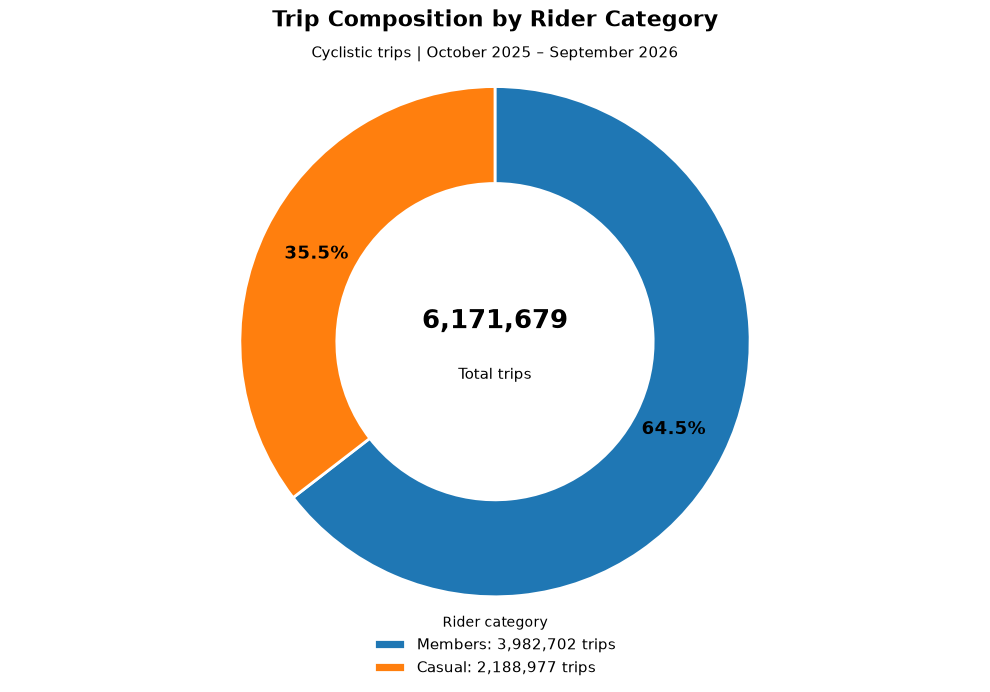


STAGE 60 — VALIDATION
Total trips: 6,171,679
Member share: 64.53%
Casual share: 35.47%
Percentages reconcile: True
Chart saved: True
Saved file: [project directory]\visualizations\01_rider_composition.png


In [3]:
# STAGE 60 — VISUALIZATION 1: RIDER COMPOSITION

from pathlib import Path
import matplotlib.pyplot as plt

# 1. Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
VISUALIZATION_DIR = PROJECT_DIR / "visualizations"

VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# 2. Verified figures from Stage 49
rider_labels = ["Members", "Casual"]
rider_counts = [3_982_702, 2_188_977]

total_trips = sum(rider_counts)

# Calculate percentages
rider_percentages = [
    count / total_trips * 100
    for count in rider_counts
]

# 3. Create the donut chart
fig, ax = plt.subplots(figsize=(10, 7))

wedges, texts, autotexts = ax.pie(
    rider_counts,
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.38,
        "edgecolor": "white",
        "linewidth": 2
    },
    textprops={
        "fontsize": 13
    }
)

# Format percentage labels
for text in autotexts:
    text.set_fontweight("bold")
    text.set_fontsize(13)

# 4. Add total trips to the centre
ax.text(
    0,
    0.08,
    f"{total_trips:,}",
    ha="center",
    va="center",
    fontsize=19,
    fontweight="bold"
)

ax.text(
    0,
    -0.13,
    "Total trips",
    ha="center",
    va="center",
    fontsize=11
)

# 5. Add legend with exact trip counts
legend_labels = [
    f"{label}: {count:,} trips"
    for label, count in zip(rider_labels, rider_counts)
]

ax.legend(
    wedges,
    legend_labels,
    title="Rider category",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    frameon=False,
    fontsize=11
)

# 6. Add chart title and reporting period
ax.set_title(
    "Trip Composition by Rider Category",
    fontsize=16,
    fontweight="bold",
    pad=25
)

fig.text(
    0.5,
    0.91,
    "Cyclistic trips | October 2025 – September 2026",
    ha="center",
    fontsize=11
)

ax.axis("equal")

plt.tight_layout()

# 7. Save high-resolution image
chart_path = VISUALIZATION_DIR / "01_rider_composition.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

# 8. Display chart
plt.show()

# 9. Validate figures and saved file
print("\nSTAGE 60 — VALIDATION")
print("=" * 55)

print("Total trips:", f"{total_trips:,}")
print("Member share:", f"{rider_percentages[0]:.2f}%")
print("Casual share:", f"{rider_percentages[1]:.2f}%")

print(
    "Percentages reconcile:",
    round(sum(rider_percentages), 2) == 100.00
)

print("Chart saved:", chart_path.exists())
print("Saved file:", chart_path)

### Visualization 2 — Ride duration by rider category

**Business question:** How does ride duration differ between casual riders and members?

A grouped bar chart was selected to compare mean and median ride durations across the two rider categories.

The chart uses the verified Stage 50 results:
- Members: mean 11.96 minutes; median 8.53 minutes.
- Casual: mean 17.62 minutes; median 10.79 minutes.

**Key observation:** Casual trips have higher mean and median durations than member trips. The difference is visible in both measures.

**Business relevance:** The duration difference suggests that casual and member trip activity may have different usage patterns. This can inform further investigation into membership-conversion opportunities and the needs of each rider category.

**Limitation:** Ride duration alone does not establish trip purpose, rider motivation, or the likelihood that a casual rider will become a member. The analysis excludes records flagged during the duration-quality audit.

**Source:** Duration-eligible dataset, `cyclistic_duration_eligible.parquet`.

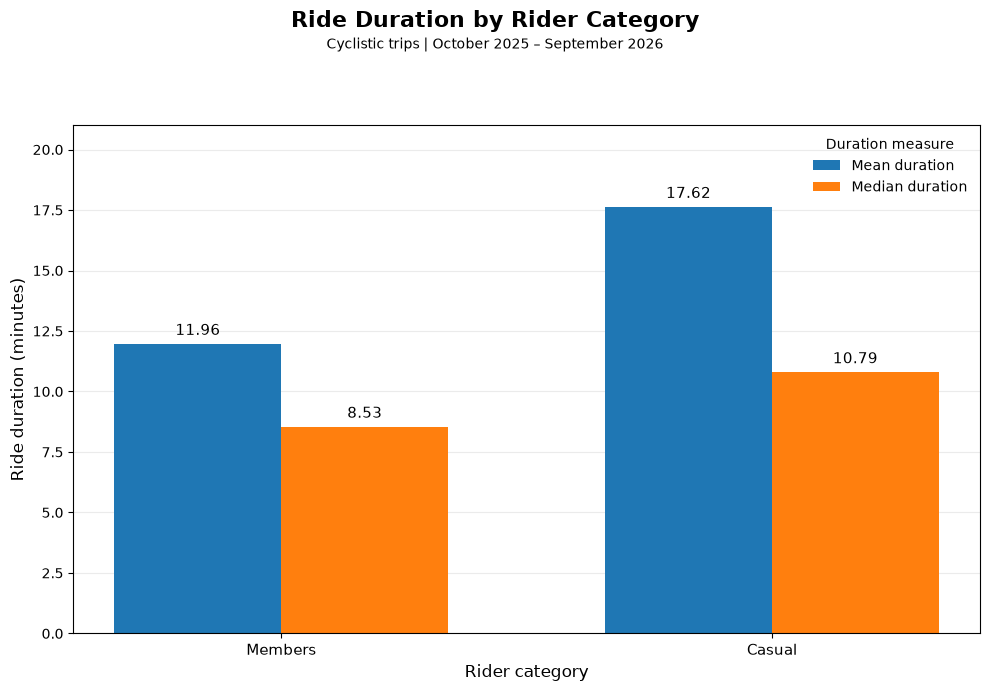


STAGE 61 — FINAL VALIDATION
Member mean: 11.96 minutes
Casual mean: 17.62 minutes
Member median: 8.53 minutes
Casual median: 10.79 minutes
Casual trips exceed member trips on both measures: True
Chart saved: True
Saved file: [project directory]\visualizations\02_ride_duration_comparison.png


In [5]:
# STAGE 61 — RIDE DURATION BY RIDER CATEGORY
# Corrected title and subtitle spacing

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
VISUALIZATION_DIR = PROJECT_DIR / "visualizations"
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# Verified Stage 50 figures (minutes)
rider_categories = ["Members", "Casual"]
mean_durations = [11.959185, 17.620587]
median_durations = [8.534083, 10.786750]

x = np.arange(len(rider_categories))
bar_width = 0.34

fig, ax = plt.subplots(figsize=(10, 7))

mean_bars = ax.bar(
    x - bar_width / 2,
    mean_durations,
    bar_width,
    label="Mean duration"
)

median_bars = ax.bar(
    x + bar_width / 2,
    median_durations,
    bar_width,
    label="Median duration"
)

# Value labels
ax.bar_label(
    mean_bars,
    labels=[f"{v:.2f}" for v in mean_durations],
    padding=4,
    fontsize=11
)

ax.bar_label(
    median_bars,
    labels=[f"{v:.2f}" for v in median_durations],
    padding=4,
    fontsize=11
)

# Chart title
fig.suptitle(
    "Ride Duration by Rider Category",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

# Reporting period
fig.text(
    0.5,
    0.925,
    "Cyclistic trips | October 2025 – September 2026",
    ha="center",
    fontsize=10
)

# Axis formatting
ax.set_ylabel("Ride duration (minutes)", fontsize=12)
ax.set_xlabel("Rider category", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(rider_categories, fontsize=11)

ax.legend(
    title="Duration measure",
    frameon=False
)

ax.set_ylim(0, 21)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# Reserve space for title and subtitle
fig.tight_layout(rect=[0, 0, 1, 0.89])

# Save chart
chart_path = VISUALIZATION_DIR / "02_ride_duration_comparison.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Validation
print("\nSTAGE 61 — FINAL VALIDATION")
print("=" * 55)

print("Member mean:", f"{mean_durations[0]:.2f} minutes")
print("Casual mean:", f"{mean_durations[1]:.2f} minutes")
print("Member median:", f"{median_durations[0]:.2f} minutes")
print("Casual median:", f"{median_durations[1]:.2f} minutes")

print(
    "Casual trips exceed member trips on both measures:",
    mean_durations[1] > mean_durations[0]
    and median_durations[1] > median_durations[0]
)

print("Chart saved:", chart_path.exists())
print("Saved file:", chart_path)

### Visualization 3 — Weekly activity patterns by rider category

**Business question:** How does average daily trip activity differ between members and casual riders on weekdays and weekends?

A grouped bar chart was selected to compare average daily trip activity across rider categories and day types.

The chart uses the verified Stage 51 results:

- Members: 11,707.78 average daily trips on weekdays and 8,913.19 on weekends.
- Casual: 5,257.39 average daily trips on weekdays and 7,853.82 on weekends.

**Key observation:** Casual riders record higher average daily activity on weekends, while members record higher average daily activity on weekdays.

Casual weekend activity is 49.39% higher than weekday activity. Member average daily activity is 31.35% higher on weekdays than on weekends. Conversely, weekend activity is 23.87% lower than weekday activity.

**Business relevance:** The contrasting patterns suggest that membership marketing could be investigated across different periods. Weekend campaigns may provide opportunities to engage casual riders, while weekday communication may be more relevant to existing member usage patterns.

**Limitation:** These are average daily trip counts, not individual rider schedules. The analysis does not establish why riders travel or whether a particular campaign would increase membership conversion.

**Source:** Cleaned master dataset, `cyclistic_master_cleaned.parquet`.

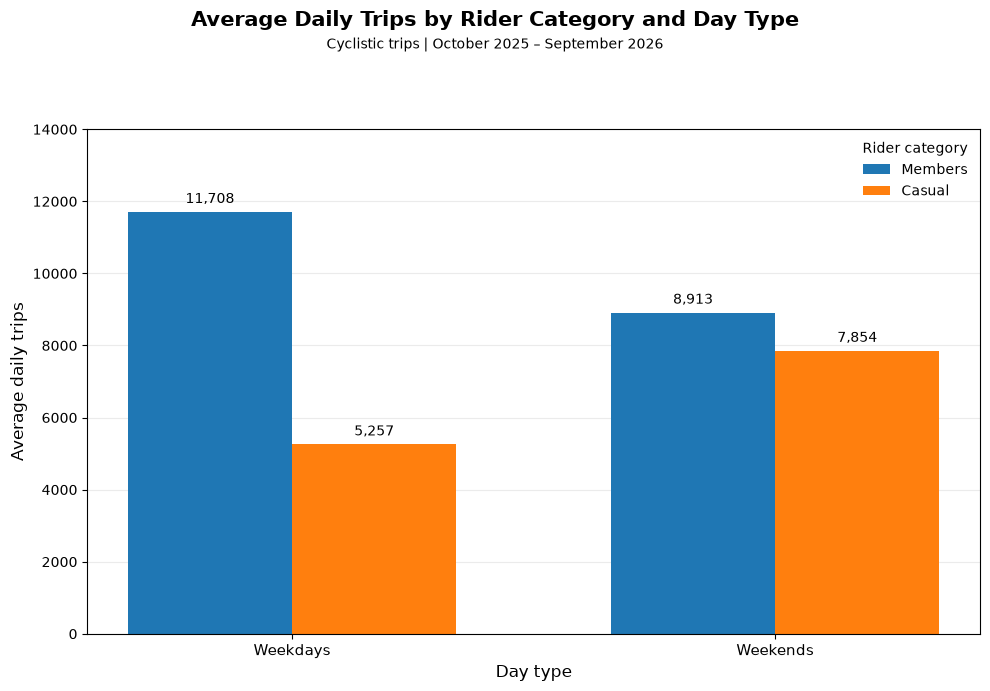


STAGE 62 — VALIDATION
Casual weekend increase: 49.39%
Member weekday increase: 31.35%
Casual weekend activity exceeds weekday activity: True
Member weekday activity exceeds weekend activity: True
Chart saved: True
Saved file: [project directory]\visualizations\03_weekly_activity_patterns.png


In [6]:

# STAGE 62 — VISUALIZATION 3: WEEKLY ACTIVITY PATTERNS

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# 1. Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
VISUALIZATION_DIR = PROJECT_DIR / "visualizations"

VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# 2. Verified Stage 51 figures
day_types = ["Weekdays", "Weekends"]

member_daily_average = [11707.78, 8913.19]
casual_daily_average = [5257.39, 7853.82]

# 3. Prepare grouped bars
x = np.arange(len(day_types))
bar_width = 0.34

fig, ax = plt.subplots(figsize=(10, 7))

member_bars = ax.bar(
    x - bar_width / 2,
    member_daily_average,
    bar_width,
    label="Members"
)

casual_bars = ax.bar(
    x + bar_width / 2,
    casual_daily_average,
    bar_width,
    label="Casual"
)

# 4. Add value labels
ax.bar_label(
    member_bars,
    labels=[f"{value:,.0f}" for value in member_daily_average],
    padding=4,
    fontsize=10
)

ax.bar_label(
    casual_bars,
    labels=[f"{value:,.0f}" for value in casual_daily_average],
    padding=4,
    fontsize=10
)

# 5. Chart title and reporting period
fig.suptitle(
    "Average Daily Trips by Rider Category and Day Type",
    fontsize=15,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.925,
    "Cyclistic trips | October 2025 – September 2026",
    ha="center",
    fontsize=10
)

# 6. Axis formatting
ax.set_xlabel("Day type", fontsize=12)
ax.set_ylabel("Average daily trips", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(day_types, fontsize=11)

ax.legend(
    title="Rider category",
    frameon=False
)

ax.set_ylim(0, 14000)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# 7. Save chart
fig.tight_layout(rect=[0, 0, 1, 0.89])

chart_path = (
    VISUALIZATION_DIR /
    "03_weekly_activity_patterns.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 8. Validation
casual_weekend_change = (
    (casual_daily_average[1] /
     casual_daily_average[0]) - 1
) * 100

member_weekday_change = (
    (member_daily_average[0] /
     member_daily_average[1]) - 1
) * 100

print("\nSTAGE 62 — VALIDATION")
print("=" * 60)

print(
    "Casual weekend increase:",
    f"{casual_weekend_change:.2f}%"
)

print(
    "Member weekday increase:",
    f"{member_weekday_change:.2f}%"
)

print(
    "Casual weekend activity exceeds weekday activity:",
    casual_daily_average[1] > casual_daily_average[0]
)

print(
    "Member weekday activity exceeds weekend activity:",
    member_daily_average[0] > member_daily_average[1]
)

print("Chart saved:", chart_path.exists())
print("Saved file:", chart_path)


### Visualization 4 — Monthly rider activity composition

**Business question:** How does the proportion of casual and member trip activity change throughout the reporting year?

A two-line chart was selected to compare the monthly share of recorded trips contributed by casual riders and members.

The chart uses the verified Stage 52 monthly results.

**Key observation:** Casual riders account for a smaller share of trip activity during the winter months and a larger share during the warmer months observed. Casual trip share reaches its highest point in July 2026 (41.17%) and its lowest point in January 2026 (17.96%).

**Business relevance:** The observed variation suggests an opportunity to investigate seasonal membership-conversion campaigns, particularly ahead of periods when casual trip activity increases.

**Limitation:** The dataset covers one reporting year. It cannot establish that the same seasonal pattern will recur annually. Changes in trip share also do not independently establish the reasons for rider behaviour.

**Source:** Cleaned master dataset, `cyclistic_master_cleaned.parquet`.

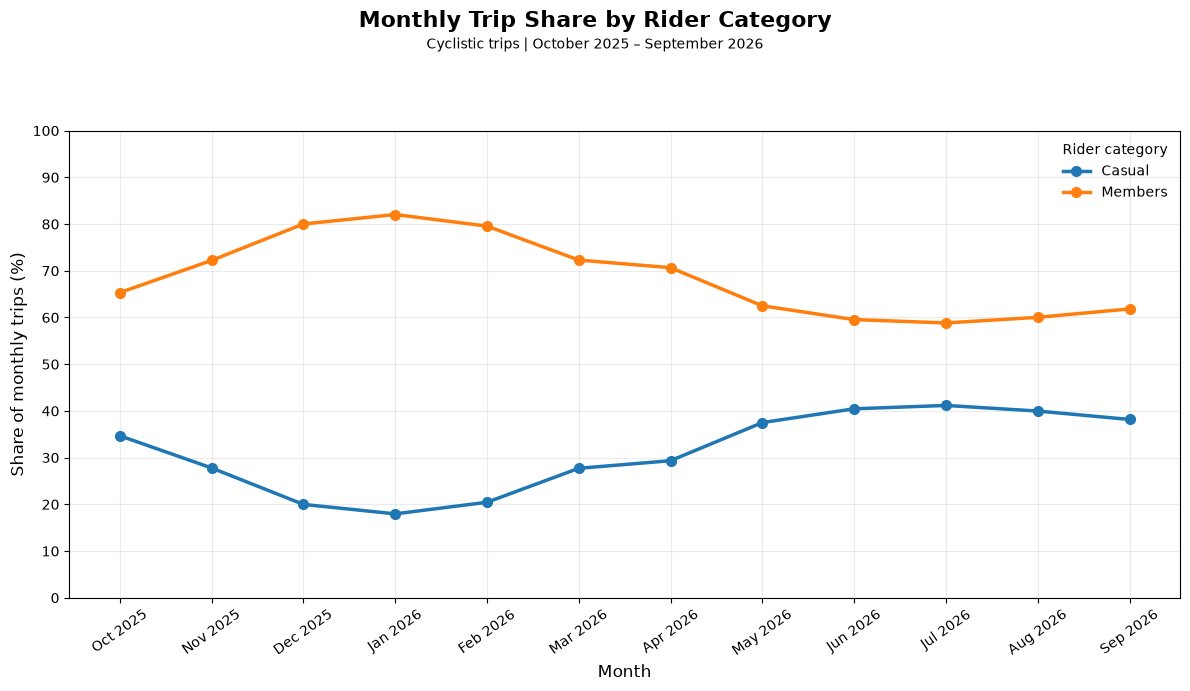


STAGE 63 — VALIDATION
Number of months: 12
Casual lowest share: 17.96%
Casual highest share: 41.17%
Lowest casual share month: Jan 2026
Highest casual share month: Jul 2026
Monthly shares reconcile to 100%: True
Chart saved: True
Saved file: [project directory]\visualizations\04_monthly_rider_seasonality.png


In [7]:

# STAGE 63 — VISUALIZATION 4: SEASONALITY

from pathlib import Path
import matplotlib.pyplot as plt

# 1. Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
VISUALIZATION_DIR = PROJECT_DIR / "visualizations"

VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# 2. Verified Stage 52 monthly results
months = [
    "Oct 2025", "Nov 2025", "Dec 2025",
    "Jan 2026", "Feb 2026", "Mar 2026",
    "Apr 2026", "May 2026", "Jun 2026",
    "Jul 2026", "Aug 2026", "Sep 2026"
]

casual_share = [
    34.68, 27.79, 19.99, 17.96,
    20.44, 27.71, 29.34, 37.50,
    40.45, 41.17, 39.97, 38.17
]

member_share = [
    65.32, 72.21, 80.01, 82.04,
    79.56, 72.29, 70.66, 62.50,
    59.55, 58.83, 60.03, 61.83
]

# 3. Create line chart
fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(
    months,
    casual_share,
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Casual"
)

ax.plot(
    months,
    member_share,
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Members"
)

# 4. Add title and subtitle
fig.suptitle(
    "Monthly Trip Share by Rider Category",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.925,
    "Cyclistic trips | October 2025 – September 2026",
    ha="center",
    fontsize=10
)

# 5. Format axes
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Share of monthly trips (%)", fontsize=12)

ax.set_ylim(0, 100)
ax.set_yticks(range(0, 101, 10))

ax.tick_params(axis="x", rotation=35)

ax.grid(alpha=0.25)
ax.set_axisbelow(True)

ax.legend(
    title="Rider category",
    frameon=False
)

# 6. Save chart
fig.tight_layout(rect=[0, 0, 1, 0.89])

chart_path = (
    VISUALIZATION_DIR /
    "04_monthly_rider_seasonality.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Validation
print("\nSTAGE 63 — VALIDATION")
print("=" * 60)

print("Number of months:", len(months))
print("Casual lowest share:", f"{min(casual_share):.2f}%")
print("Casual highest share:", f"{max(casual_share):.2f}%")

print(
    "Lowest casual share month:",
    months[casual_share.index(min(casual_share))]
)

print(
    "Highest casual share month:",
    months[casual_share.index(max(casual_share))]
)

print(
    "Monthly shares reconcile to 100%:",
    all(
        round(casual + member, 2) == 100.00
        for casual, member in zip(casual_share, member_share)
    )
)

print("Chart saved:", chart_path.exists())
print("Saved file:", chart_path)


### Visualization 5 — Bike-type distribution by rider category

**Business question:** Does the distribution of classic-bike and electric-bike trips differ between members and casual riders?

A 100% stacked bar chart was selected to compare the relative distribution of bike types within each rider category.

The chart uses the verified Stage 53 results:

- Members: 68.97% electric-bike trips and 31.03% classic-bike trips.
- Casual: 74.94% electric-bike trips and 25.06% classic-bike trips.

**Key observation:** Electric bikes account for a larger share of casual trip activity than member trip activity. The difference is 5.96 percentage points.

**Business relevance:** The difference may help inform further investigation into whether electric-bike access or related membership benefits could be relevant to membership-conversion strategies.

**Limitation:** These percentages represent trip activity, not individual rider preferences. They do not establish why riders selected a particular bike type.

**Source:** Cleaned master dataset, `cyclistic_master_cleaned.parquet`.

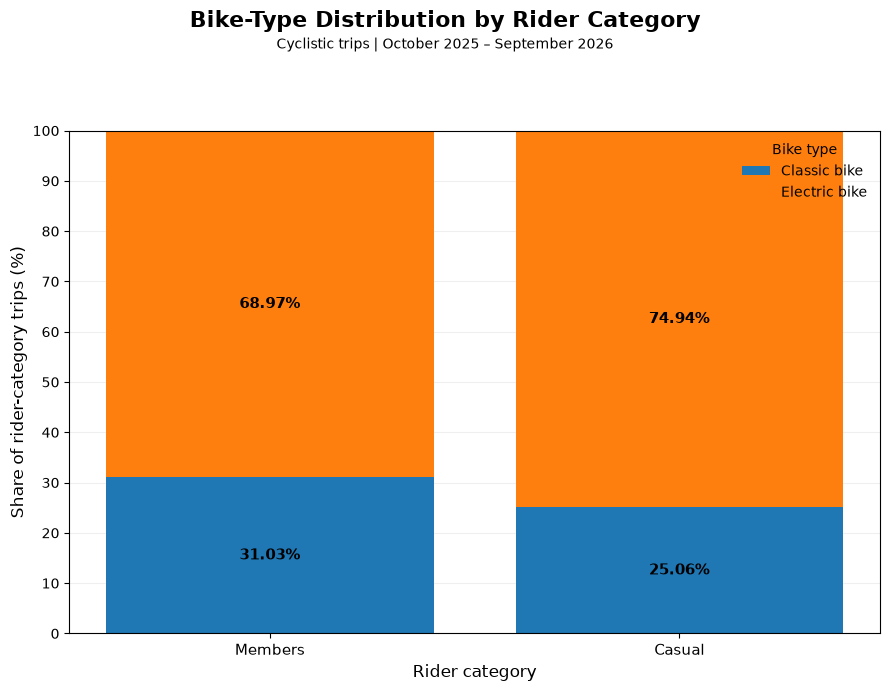


STAGE 64 — VALIDATION
Member classic share: 31.03%
Member electric share: 68.97%
Casual classic share: 25.06%
Casual electric share: 74.94%
Casual electric-bike share advantage: 5.97 percentage points
Member percentages reconcile: True
Casual percentages reconcile: True
Chart saved: True
Saved file: [project directory]\visualizations\05_bike_type_distribution.png


In [8]:

# STAGE 64 — VISUALIZATION 5: BIKE-TYPE DISTRIBUTION

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# 1. Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
VISUALIZATION_DIR = PROJECT_DIR / "visualizations"

VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# 2. Verified Stage 53 percentages
rider_categories = ["Members", "Casual"]

classic_share = [31.03, 25.06]
electric_share = [68.97, 74.94]

# 3. Create 100% stacked bar chart
x = np.arange(len(rider_categories))

fig, ax = plt.subplots(figsize=(9, 7))

classic_bars = ax.bar(
    x,
    classic_share,
    label="Classic bike"
)

electric_bars = ax.bar(
    x,
    electric_share,
    bottom=classic_share,
    label="Electric bike"
)

# 4. Add percentage labels inside each segment
for i in range(len(rider_categories)):
    ax.text(
        x[i],
        classic_share[i] / 2,
        f"{classic_share[i]:.2f}%",
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

    ax.text(
        x[i],
        classic_share[i] + electric_share[i] / 2,
        f"{electric_share[i]:.2f}%",
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

# 5. Add title and subtitle
fig.suptitle(
    "Bike-Type Distribution by Rider Category",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.925,
    "Cyclistic trips | October 2025 – September 2026",
    ha="center",
    fontsize=10
)

# 6. Format axes
ax.set_ylabel("Share of rider-category trips (%)", fontsize=12)
ax.set_xlabel("Rider category", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(rider_categories, fontsize=11)

ax.set_ylim(0, 100)
ax.set_yticks(range(0, 101, 10))

ax.legend(
    title="Bike type",
    frameon=False,
    loc="upper right"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# 7. Save chart
fig.tight_layout(rect=[0, 0, 1, 0.89])

chart_path = (
    VISUALIZATION_DIR /
    "05_bike_type_distribution.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 8. Validation
electric_difference = electric_share[1] - electric_share[0]

print("\nSTAGE 64 — VALIDATION")
print("=" * 60)

print("Member classic share:", f"{classic_share[0]:.2f}%")
print("Member electric share:", f"{electric_share[0]:.2f}%")

print("Casual classic share:", f"{classic_share[1]:.2f}%")
print("Casual electric share:", f"{electric_share[1]:.2f}%")

print(
    "Casual electric-bike share advantage:",
    f"{electric_difference:.2f} percentage points"
)

print(
    "Member percentages reconcile:",
    round(classic_share[0] + electric_share[0], 2) == 100.00
)

print(
    "Casual percentages reconcile:",
    round(classic_share[1] + electric_share[1], 2) == 100.00
)

print("Chart saved:", chart_path.exists())
print("Saved file:", chart_path)


### Visualization 6 — Ride duration by bike type and rider category

**Business question:** Do casual riders have longer trips than members when comparing the same bike type?

A grouped bar chart was selected to compare mean ride duration between members and casual riders across classic and electric bikes.

The chart uses the verified Stage 54 results:

- Classic bikes: casual 28.59 minutes; member 13.92 minutes.
- Electric bikes: casual 13.96 minutes; member 11.08 minutes.

**Key observation:** Casual trips have longer mean durations within both bike categories. The difference is considerably larger for classic bikes (14.67 minutes) than electric bikes (2.89 minutes).

**Business relevance:** The results indicate that bike-type distribution alone does not explain the overall difference in ride duration between casual riders and members. This provides a basis for further investigation into usage patterns within each bike category.

**Limitation:** The analysis establishes an association between rider category, bike type and recorded trip duration. It does not establish the reasons for the differences or trip purposes. Only duration-eligible records are included.

**Source:** Duration-eligible dataset, `cyclistic_duration_eligible.parquet`.

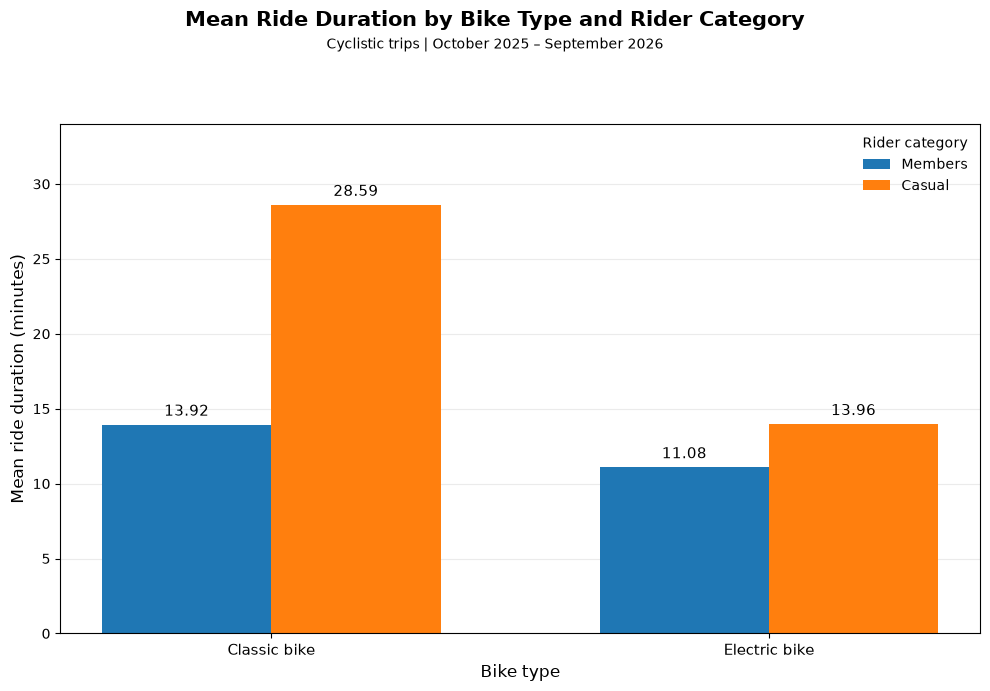


STAGE 65 — VALIDATION
Classic-bike duration difference: 14.67 minutes
Electric-bike duration difference: 2.88 minutes
Casual trips longer for classic bikes: True
Casual trips longer for electric bikes: True
Classic-bike duration difference is larger: True
Chart saved: True
Saved file: [project directory]\visualizations\06_duration_by_bike_type.png


In [9]:

# STAGE 65 — VISUALIZATION 6: DURATION BY BIKE TYPE

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# 1. Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
VISUALIZATION_DIR = PROJECT_DIR / "visualizations"

VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# 2. Verified Stage 54 mean durations (minutes)
bike_types = ["Classic bike", "Electric bike"]

member_means = [13.92, 11.08]
casual_means = [28.59, 13.96]

# 3. Prepare grouped bars
x = np.arange(len(bike_types))
bar_width = 0.34

fig, ax = plt.subplots(figsize=(10, 7))

member_bars = ax.bar(
    x - bar_width / 2,
    member_means,
    bar_width,
    label="Members"
)

casual_bars = ax.bar(
    x + bar_width / 2,
    casual_means,
    bar_width,
    label="Casual"
)

# 4. Add value labels
ax.bar_label(
    member_bars,
    labels=[f"{v:.2f}" for v in member_means],
    padding=4,
    fontsize=11
)

ax.bar_label(
    casual_bars,
    labels=[f"{v:.2f}" for v in casual_means],
    padding=4,
    fontsize=11
)

# 5. Add title and subtitle
fig.suptitle(
    "Mean Ride Duration by Bike Type and Rider Category",
    fontsize=15,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.925,
    "Cyclistic trips | October 2025 – September 2026",
    ha="center",
    fontsize=10
)

# 6. Format axes
ax.set_xlabel("Bike type", fontsize=12)
ax.set_ylabel("Mean ride duration (minutes)", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(bike_types, fontsize=11)

ax.legend(
    title="Rider category",
    frameon=False
)

ax.set_ylim(0, 34)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# 7. Save chart
fig.tight_layout(rect=[0, 0, 1, 0.89])

chart_path = (
    VISUALIZATION_DIR /
    "06_duration_by_bike_type.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 8. Calculate and validate differences
classic_difference = casual_means[0] - member_means[0]
electric_difference = casual_means[1] - member_means[1]

print("\nSTAGE 65 — VALIDATION")
print("=" * 60)

print(
    "Classic-bike duration difference:",
    f"{classic_difference:.2f} minutes"
)

print(
    "Electric-bike duration difference:",
    f"{electric_difference:.2f} minutes"
)

print(
    "Casual trips longer for classic bikes:",
    casual_means[0] > member_means[0]
)

print(
    "Casual trips longer for electric bikes:",
    casual_means[1] > member_means[1]
)

print(
    "Classic-bike duration difference is larger:",
    classic_difference > electric_difference
)

print("Chart saved:", chart_path.exists())
print("Saved file:", chart_path)


### Stage 66 — Visualization inventory and quality control

This stage verifies the six visualizations produced for the Cyclistic case study.

The checks confirm that:
- All expected chart files exist in the project visualization directory.
- Each chart has a non-zero file size.
- The files use the expected PNG format.
- The complete visualization set is available for the reporting and portfolio stages.

No analytical results are recalculated in this stage.

In [10]:

# STAGE 66 — VISUALIZATION INVENTORY AND QUALITY CONTROL

from pathlib import Path
import pandas as pd

# 1. Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
VISUALIZATION_DIR = PROJECT_DIR / "visualizations"

# 2. Expected visualization files
expected_charts = [
    "01_rider_composition.png",
    "02_ride_duration_comparison.png",
    "03_weekly_activity_patterns.png",
    "04_monthly_rider_seasonality.png",
    "05_bike_type_distribution.png",
    "06_duration_by_bike_type.png"
]

# 3. Inspect each file
inventory = []

for filename in expected_charts:

    file_path = VISUALIZATION_DIR / filename

    exists = file_path.exists()

    file_size = (
        file_path.stat().st_size
        if exists else 0
    )

    inventory.append({
        "filename": filename,
        "exists": exists,
        "file_size_kb": round(file_size / 1024, 2),
        "valid_size": file_size > 0,
        "format": file_path.suffix.upper()
    })

# 4. Create inventory table
stage66_inventory = pd.DataFrame(inventory)

print("STAGE 66 — VISUALIZATION INVENTORY")
print("=" * 75)

display(stage66_inventory)

# 5. Validation checks
print("\nVISUALIZATION QUALITY CONTROL")
print("=" * 65)

print(
    "All six charts exist:",
    stage66_inventory["exists"].all()
)

print(
    "All six files have non-zero size:",
    stage66_inventory["valid_size"].all()
)

print(
    "All files are PNG:",
    (stage66_inventory["format"] == ".PNG").all()
)

print(
    "Expected chart count:",
    len(stage66_inventory) == 6
)

print(
    "All inventory checks passed:",
    (
        stage66_inventory["exists"].all()
        and stage66_inventory["valid_size"].all()
        and (stage66_inventory["format"] == ".PNG").all()
        and len(stage66_inventory) == 6
    )
)


STAGE 66 — VISUALIZATION INVENTORY


,filename,exists,file_size_kb,valid_size,format
0,01_rider_composition.png,True,158.06,True,.PNG
1,02_ride_duration_comparison.png,True,125.34,True,.PNG
2,03_weekly_activity_patterns.png,True,132.36,True,.PNG
3,04_monthly_rider_seasonality.png,True,245.83,True,.PNG
4,05_bike_type_distribution.png,True,143.55,True,.PNG
5,06_duration_by_bike_type.png,True,128.52,True,.PNG



VISUALIZATION QUALITY CONTROL
All six charts exist: True
All six files have non-zero size: True
All files are PNG: True
Expected chart count: True
All inventory checks passed: True


### Stage 67 — Consolidated findings and business implications

**Objective:** Bring together the verified analytical findings and explain their relevance to Cyclistic's membership-growth objective.

The findings are organized into three levels:

- Primary findings: The strongest evidence relevant to understanding differences between casual and member trip activity.
- Supporting findings: Additional evidence that helps explain the primary patterns.
- Secondary finding: A narrower pattern that may warrant further investigation but should not drive the main recommendation.

The analysis distinguishes observed trip behaviour from assumptions about individual riders. Trip counts represent recorded trips, not unique customers, and the findings do not establish the reasons behind rider behaviour.

This stage consolidates existing results; it does not introduce new calculations or claim causal relationships.

In [11]:

# STAGE 67 — CONSOLIDATED FINDINGS AND BUSINESS IMPLICATIONS

import pandas as pd

# 1. Build the consolidated findings table
stage67_findings = pd.DataFrame([

    {
        "priority": "Primary",
        "topic": "Rider composition",
        "key_evidence": (
            "Members account for 64.53% of trips; "
            "casual riders account for 35.47%."
        ),
        "business_implication": (
            "Casual riders represent a substantial share "
            "of recorded trip activity and a potential "
            "audience for membership-growth initiatives."
        ),
        "limitation": (
            "Trip proportions do not represent unique customers."
        )
    },

    {
        "priority": "Primary",
        "topic": "Ride duration",
        "key_evidence": (
            "Casual mean duration is 17.62 minutes "
            "and median is 10.79 minutes; "
            "member mean is 11.96 minutes "
            "and median is 8.53 minutes."
        ),
        "business_implication": (
            "The difference in typical trip duration "
            "provides a basis for investigating whether "
            "membership offers could appeal to casual riders."
        ),
        "limitation": (
            "Duration alone does not establish trip purpose "
            "or willingness to become a member."
        )
    },

    {
        "priority": "Primary",
        "topic": "Weekly activity patterns",
        "key_evidence": (
            "Casual average daily trips are 49.39% higher "
            "on weekends than weekdays. "
            "Member average daily trips are 31.35% higher "
            "on weekdays than weekends."
        ),
        "business_implication": (
            "Different weekly activity patterns may support "
            "testing membership messaging at different "
            "times for casual and member audiences."
        ),
        "limitation": (
            "These are aggregate trip averages, not "
            "individual rider schedules or motivations."
        )
    },

    {
        "priority": "Primary",
        "topic": "Seasonality",
        "key_evidence": (
            "Casual trip share ranges from 17.96% "
            "in January 2026 to 41.17% in July 2026."
        ),
        "business_implication": (
            "The observed increase in casual activity "
            "during warmer months may support testing "
            "seasonally timed membership campaigns."
        ),
        "limitation": (
            "Only one 12-month reporting period is available; "
            "recurring seasonal patterns cannot be established."
        )
    },

    {
        "priority": "Supporting",
        "topic": "Bike-type preference",
        "key_evidence": (
            "Electric bikes account for 74.94% of casual trips "
            "and 68.97% of member trips."
        ),
        "business_implication": (
            "Electric-bike usage could be considered when "
            "designing and testing membership messaging."
        ),
        "limitation": (
            "Trip shares do not establish individual "
            "preferences or reasons for choosing a bike."
        )
    },

    {
        "priority": "Supporting",
        "topic": "Duration by bike type",
        "key_evidence": (
            "Casual mean duration exceeds member mean duration "
            "for both classic and electric bikes. "
            "The classic-bike difference is approximately "
            "14.67 minutes; the electric-bike difference "
            "is approximately 2.89 minutes using "
            "unrounded analysis values."
        ),
        "business_implication": (
            "The overall duration difference is not explained "
            "by bike-type distribution alone."
        ),
        "limitation": (
            "The analysis does not establish why "
            "durations differ between rider categories."
        )
    },

    {
        "priority": "Secondary",
        "topic": "Short same-station morning trips",
        "key_evidence": (
            "Among complete-station weekday morning trips "
            "returning to the same station, under-five-minute "
            "trips represent 81.15% for member electric bikes "
            "and 55.23% for casual electric bikes."
        ),
        "business_implication": (
            "The pattern may justify further investigation "
            "of short same-station electric-bike activity."
        ),
        "limitation": (
            "The analysis covers a narrow weekday morning period. "
            "Electric-bike station information is only about "
            "60% complete."
        )
    }

])

# 2. Display findings
print("STAGE 67 — CONSOLIDATED FINDINGS")
print("=" * 85)

display(stage67_findings)

# 3. Validate the findings register
print("\nSTAGE 67 — VALIDATION")
print("=" * 65)

print("Total findings:", len(stage67_findings))

print(
    "Primary findings:",
    (stage67_findings["priority"] == "Primary").sum()
)

print(
    "Supporting findings:",
    (stage67_findings["priority"] == "Supporting").sum()
)

print(
    "Secondary findings:",
    (stage67_findings["priority"] == "Secondary").sum()
)

print(
    "All findings have evidence:",
    stage67_findings["key_evidence"].notna().all()
    and stage67_findings["key_evidence"].str.len().gt(0).all()
)

print(
    "All findings have business implications:",
    stage67_findings["business_implication"].notna().all()
    and stage67_findings["business_implication"].str.len().gt(0).all()
)

print(
    "All findings have limitations:",
    stage67_findings["limitation"].notna().all()
    and stage67_findings["limitation"].str.len().gt(0).all()
)

print(
    "Priority classification valid:",
    set(stage67_findings["priority"].unique())
    == {"Primary", "Supporting", "Secondary"}
)


STAGE 67 — CONSOLIDATED FINDINGS


,priority,topic,key_evidence,business_implication,limitation
0,Primary,Rider composition,Members account for 64.53% of trips; casual ri...,Casual riders represent a substantial share of...,Trip proportions do not represent unique custo...
1,Primary,Ride duration,Casual mean duration is 17.62 minutes and medi...,The difference in typical trip duration provid...,Duration alone does not establish trip purpose...
2,Primary,Weekly activity patterns,Casual average daily trips are 49.39% higher o...,Different weekly activity patterns may support...,"These are aggregate trip averages, not individ..."
3,Primary,Seasonality,Casual trip share ranges from 17.96% in Januar...,The observed increase in casual activity durin...,Only one 12-month reporting period is availabl...
4,Supporting,Bike-type preference,Electric bikes account for 74.94% of casual tr...,Electric-bike usage could be considered when d...,Trip shares do not establish individual prefer...
5,Supporting,Duration by bike type,Casual mean duration exceeds member mean durat...,The overall duration difference is not explain...,The analysis does not establish why durations ...
6,Secondary,Short same-station morning trips,Among complete-station weekday morning trips r...,The pattern may justify further investigation ...,The analysis covers a narrow weekday morning p...



STAGE 67 — VALIDATION
Total findings: 7
Primary findings: 4
Supporting findings: 2
Secondary findings: 1
All findings have evidence: True
All findings have business implications: True
All findings have limitations: True
Priority classification valid: True


### Stage 68 — Recommendations and proposed business actions

**Objective:** Develop actionable recommendations based on the verified analytical findings.

Recommendations are proposals for business testing, not proven solutions. The available trip dataset describes usage patterns but does not contain individual customer identities, membership conversion histories, campaign exposure or customer motivations.

Each recommendation therefore includes:
- The supporting analytical evidence.
- The proposed business action.
- The intended business outcome.
- A measurable performance indicator.
- The limitations or additional information required.

The recommendations prioritize weekly activity patterns, seasonality and ride-duration differences. Bike-type findings provide supporting context, while the short same-station morning pattern remains secondary.

No causal relationship between observed trip behaviour and membership conversion is assumed.

In [12]:

# STAGE 68 — RECOMMENDATIONS AND PROPOSED BUSINESS ACTIONS

import pandas as pd

# 1. Create evidence-based recommendations
stage68_recommendations = pd.DataFrame([

    {
        "priority": 1,
        "recommendation": "Test weekend membership campaigns",
        "supporting_evidence": (
            "Casual average daily trips are 49.39% higher "
            "on weekends than weekdays."
        ),
        "proposed_action": (
            "Test membership promotions and membership-benefit "
            "messaging during periods of stronger weekend "
            "casual trip activity."
        ),
        "intended_outcome": (
            "Increase membership enquiries and conversions "
            "among casual riders."
        ),
        "success_metric": (
            "Casual-to-member conversion rate among "
            "campaign-exposed riders."
        ),
        "additional_data_needed": (
            "Campaign exposure, unique rider identifiers, "
            "and membership conversion records."
        )
    },

    {
        "priority": 2,
        "recommendation": "Test seasonal acquisition campaigns",
        "supporting_evidence": (
            "Casual trip share increased from 17.96% "
            "in January 2026 to 41.17% in July 2026."
        ),
        "proposed_action": (
            "Test targeted membership campaigns before "
            "and during periods of increased casual activity."
        ),
        "intended_outcome": (
            "Capture potential membership interest "
            "during periods of stronger casual usage."
        ),
        "success_metric": (
            "Monthly campaign conversion rate and "
            "incremental memberships acquired."
        ),
        "additional_data_needed": (
            "Multiple years of usage data, campaign records, "
            "and membership acquisition data."
        )
    },

    {
        "priority": 3,
        "recommendation": "Test duration-based membership messaging",
        "supporting_evidence": (
            "Casual mean trip duration is 17.62 minutes, "
            "compared with 11.96 minutes for members."
        ),
        "proposed_action": (
            "Test messaging that explains membership benefits "
            "for riders who use the service regularly or "
            "accumulate longer trips."
        ),
        "intended_outcome": (
            "Determine whether relevant membership-benefit "
            "messaging improves conversion."
        ),
        "success_metric": (
            "Conversion rate by messaging variant "
            "and rider usage segment."
        ),
        "additional_data_needed": (
            "Customer-level trip histories, membership "
            "pricing and benefit information, and campaign tests."
        )
    },

    {
        "priority": 4,
        "recommendation": "Incorporate electric-bike usage into campaign testing",
        "supporting_evidence": (
            "Electric bikes account for 74.94% of casual trips "
            "and 68.97% of member trips."
        ),
        "proposed_action": (
            "Test membership messaging that clearly explains "
            "the applicable electric-bike access, pricing "
            "and membership benefits."
        ),
        "intended_outcome": (
            "Determine whether electric-bike-related "
            "membership information improves conversion."
        ),
        "success_metric": (
            "Conversion rate among eligible electric-bike "
            "campaign audiences."
        ),
        "additional_data_needed": (
            "Membership terms, electric-bike pricing rules, "
            "campaign exposure and conversion records."
        )
    },

    {
        "priority": 5,
        "recommendation": "Investigate short same-station trips",
        "supporting_evidence": (
            "Under-five-minute trips represent 81.15% "
            "of complete-station, same-station weekday "
            "morning member electric-bike trips."
        ),
        "proposed_action": (
            "Investigate this pattern using more complete "
            "station records and additional operational data "
            "before designing a targeted intervention."
        ),
        "intended_outcome": (
            "Establish whether the pattern has a meaningful "
            "operational or customer-engagement explanation."
        ),
        "success_metric": (
            "Validated pattern across broader periods "
            "and more complete station records."
        ),
        "additional_data_needed": (
            "Improved station data completeness, broader "
            "time-period analysis and operational context."
        )
    }

])

# 2. Display recommendations
print("STAGE 68 — BUSINESS RECOMMENDATIONS")
print("=" * 90)

display(stage68_recommendations)

# 3. Validate recommendation structure
required_columns = [
    "recommendation",
    "supporting_evidence",
    "proposed_action",
    "intended_outcome",
    "success_metric",
    "additional_data_needed"
]

print("\nSTAGE 68 — VALIDATION")
print("=" * 65)

print(
    "Total recommendations:",
    len(stage68_recommendations)
)

print(
    "All required columns present:",
    set(required_columns).issubset(
        stage68_recommendations.columns
    )
)

print(
    "No missing recommendation fields:",
    stage68_recommendations[required_columns]
    .notna().all().all()
)

print(
    "All recommendation fields populated:",
    stage68_recommendations[required_columns]
    .apply(lambda column: column.astype(str).str.strip().ne("").all())
    .all()
)

print(
    "Recommendation priorities unique:",
    stage68_recommendations["priority"].is_unique
)

print(
    "All recommendations have measurable indicators:",
    stage68_recommendations["success_metric"]
    .str.len().gt(0).all()
)


STAGE 68 — BUSINESS RECOMMENDATIONS


,priority,recommendation,supporting_evidence,proposed_action,intended_outcome,success_metric,additional_data_needed
0,1,Test weekend membership campaigns,Casual average daily trips are 49.39% higher o...,Test membership promotions and membership-bene...,Increase membership enquiries and conversions ...,Casual-to-member conversion rate among campaig...,"Campaign exposure, unique rider identifiers, a..."
1,2,Test seasonal acquisition campaigns,Casual trip share increased from 17.96% in Jan...,Test targeted membership campaigns before and ...,Capture potential membership interest during p...,Monthly campaign conversion rate and increment...,"Multiple years of usage data, campaign records..."
2,3,Test duration-based membership messaging,"Casual mean trip duration is 17.62 minutes, co...",Test messaging that explains membership benefi...,Determine whether relevant membership-benefit ...,Conversion rate by messaging variant and rider...,"Customer-level trip histories, membership pric..."
3,4,Incorporate electric-bike usage into campaign ...,Electric bikes account for 74.94% of casual tr...,Test membership messaging that clearly explain...,Determine whether electric-bike-related member...,Conversion rate among eligible electric-bike c...,"Membership terms, electric-bike pricing rules,..."
4,5,Investigate short same-station trips,Under-five-minute trips represent 81.15% of co...,Investigate this pattern using more complete s...,Establish whether the pattern has a meaningful...,Validated pattern across broader periods and m...,"Improved station data completeness, broader ti..."



STAGE 68 — VALIDATION
Total recommendations: 5
All required columns present: True
No missing recommendation fields: True
All recommendation fields populated: True
Recommendation priorities unique: True
All recommendations have measurable indicators: True


### Stage 69 — Assumptions, limitations and methodological transparency

**Objective:** Document the assumptions, data-quality decisions and analytical limitations that affect interpretation of the Cyclistic findings.

#### 1. Reporting period

The analysis covers October 2025 through September 2026, inclusive. Records outside this reporting period were excluded from the cleaned reporting dataset.

#### 2. Duplicate records

Duplicate ride IDs were investigated before removal. The 35 duplicate pairs identified were exact duplicates across all 13 original source fields. One occurrence of each duplicated ride ID was retained in the processed dataset.

Original ZIP archives were preserved unchanged.

#### 3. Ride-duration eligibility

The cleaned master dataset retains all 6,171,679 reporting-period records.

A separate duration-eligible dataset contains 6,146,323 records. Records with negative durations, durations under five seconds, durations exceeding 24 hours, or identified daylight-saving-time anomalies were excluded from duration-based analysis.

These exclusions apply only to duration analysis. They do not represent deletion from the cleaned master dataset.

#### 4. Rider classification

The analysis uses the source dataset's member and casual classifications. Trip counts represent recorded trips, not distinct customers.

#### 5. Weekly activity

Weekday and weekend comparisons use average daily trip counts. The reporting period contains 261 weekdays and 104 weekend days. This accounts for the unequal number of weekdays and weekend days.

#### 6. Seasonality

The analysis covers one 12-month reporting cycle. The observed monthly variation is descriptive and cannot independently establish a recurring annual seasonal pattern.

#### 7. Station information

Same-station analysis requires complete start and end station information. Station information is substantially less complete for electric-bike trips than for classic-bike trips.

The same-station analysis is therefore treated as secondary evidence and is not used as a primary basis for membership-conversion recommendations.

#### 8. Trip purpose and customer motivation

The dataset does not establish why a trip occurred, why a rider selected a particular bike, or whether a casual rider intends to become a member.

No such motivations are inferred from trip duration, timing or station patterns.

#### 9. Causal limitations

This is an observational analysis of historical trip records. It does not establish that any observed usage pattern causes membership conversion.

The proposed business recommendations require controlled testing and additional customer-level and campaign data.

#### 10. Generalizability

The findings describe the supplied Cyclistic reporting period and dataset. They should not automatically be generalized to other years, locations or customer populations.

In [13]:

# STAGE 69 — ASSUMPTIONS AND LIMITATIONS REGISTER

import pandas as pd

stage69_limitations = pd.DataFrame([

    {
        "area": "Reporting period",
        "decision_or_assumption": (
            "Use October 2025 through September 2026."
        ),
        "reason": (
            "Maintain a consistent 12-month reporting period."
        ),
        "impact_on_interpretation": (
            "Findings describe this reporting period only."
        )
    },

    {
        "area": "Duplicate records",
        "decision_or_assumption": (
            "Retain one record per duplicated ride ID."
        ),
        "reason": (
            "All 35 duplicate pairs were exact duplicates "
            "across the 13 original fields."
        ),
        "impact_on_interpretation": (
            "Prevents duplicated trips from inflating "
            "analytical counts."
        )
    },

    {
        "area": "Duration eligibility",
        "decision_or_assumption": (
            "Use a separate duration-eligible dataset."
        ),
        "reason": (
            "Exclude 25,356 records from duration analysis "
            "based on documented quality flags."
        ),
        "impact_on_interpretation": (
            "Duration findings apply to 6,146,323 eligible "
            "records, not the full master dataset."
        )
    },

    {
        "area": "Rider classification",
        "decision_or_assumption": (
            "Use source-provided member and casual categories."
        ),
        "reason": (
            "Preserve the original classification scheme."
        ),
        "impact_on_interpretation": (
            "Trip counts do not represent unique customers."
        )
    },

    {
        "area": "Weekly activity",
        "decision_or_assumption": (
            "Compare average daily weekday and weekend trips."
        ),
        "reason": (
            "Account for 261 weekdays and 104 weekend days."
        ),
        "impact_on_interpretation": (
            "Aggregate daily averages do not describe "
            "individual rider schedules."
        )
    },

    {
        "area": "Seasonality",
        "decision_or_assumption": (
            "Describe monthly changes within one annual cycle."
        ),
        "reason": (
            "The supplied reporting period covers 12 months."
        ),
        "impact_on_interpretation": (
            "Recurring annual seasonality is not established."
        )
    },

    {
        "area": "Station completeness",
        "decision_or_assumption": (
            "Restrict same-station comparisons to complete "
            "station records."
        ),
        "reason": (
            "Electric-bike station information is only "
            "approximately 60% complete."
        ),
        "impact_on_interpretation": (
            "Same-station findings have limited coverage "
            "and remain secondary."
        )
    },

    {
        "area": "Trip purpose",
        "decision_or_assumption": (
            "Do not infer trip purpose or rider motivation."
        ),
        "reason": (
            "The dataset contains trip records, not "
            "self-reported customer explanations."
        ),
        "impact_on_interpretation": (
            "Observed patterns describe behaviour, "
            "not the reasons behind it."
        )
    },

    {
        "area": "Causality",
        "decision_or_assumption": (
            "Treat recommendations as hypotheses to test."
        ),
        "reason": (
            "The analysis is observational."
        ),
        "impact_on_interpretation": (
            "No recommendation is proven to cause "
            "membership conversion."
        )
    },

    {
        "area": "Generalizability",
        "decision_or_assumption": (
            "Limit conclusions to the supplied dataset "
            "and reporting period."
        ),
        "reason": (
            "Other years and populations were not analyzed."
        ),
        "impact_on_interpretation": (
            "Findings may not apply unchanged to other "
            "periods or populations."
        )
    }

])

# Display register
print("STAGE 69 — ASSUMPTIONS AND LIMITATIONS REGISTER")
print("=" * 90)

display(stage69_limitations)

# Validation
print("\nSTAGE 69 — VALIDATION")
print("=" * 65)

print("Total documented areas:", len(stage69_limitations))

print(
    "All areas documented:",
    stage69_limitations["area"].notna().all()
)

print(
    "All decisions documented:",
    stage69_limitations["decision_or_assumption"]
    .str.len().gt(0).all()
)

print(
    "All reasons documented:",
    stage69_limitations["reason"].str.len().gt(0).all()
)

print(
    "All interpretation impacts documented:",
    stage69_limitations["impact_on_interpretation"]
    .str.len().gt(0).all()
)

print(
    "No duplicate areas:",
    stage69_limitations["area"].is_unique
)


STAGE 69 — ASSUMPTIONS AND LIMITATIONS REGISTER


,area,decision_or_assumption,reason,impact_on_interpretation
0,Reporting period,Use October 2025 through September 2026.,Maintain a consistent 12-month reporting period.,Findings describe this reporting period only.
1,Duplicate records,Retain one record per duplicated ride ID.,All 35 duplicate pairs were exact duplicates a...,Prevents duplicated trips from inflating analy...
2,Duration eligibility,Use a separate duration-eligible dataset.,"Exclude 25,356 records from duration analysis ...","Duration findings apply to 6,146,323 eligible ..."
3,Rider classification,Use source-provided member and casual categories.,Preserve the original classification scheme.,Trip counts do not represent unique customers.
4,Weekly activity,Compare average daily weekday and weekend trips.,Account for 261 weekdays and 104 weekend days.,Aggregate daily averages do not describe indiv...
5,Seasonality,Describe monthly changes within one annual cycle.,The supplied reporting period covers 12 months.,Recurring annual seasonality is not established.
6,Station completeness,Restrict same-station comparisons to complete ...,Electric-bike station information is only appr...,Same-station findings have limited coverage an...
7,Trip purpose,Do not infer trip purpose or rider motivation.,"The dataset contains trip records, not self-re...","Observed patterns describe behaviour, not the ..."
8,Causality,Treat recommendations as hypotheses to test.,The analysis is observational.,No recommendation is proven to cause membershi...
9,Generalizability,Limit conclusions to the supplied dataset and ...,Other years and populations were not analyzed.,Findings may not apply unchanged to other peri...



STAGE 69 — VALIDATION
Total documented areas: 10
All areas documented: True
All decisions documented: True
All reasons documented: True
All interpretation impacts documented: True
No duplicate areas: True


### Stage 70 — Final case study structure and portfolio blueprint

**Objective:** Establish the structure of the final Cyclistic case study and map the analytical work to the business questions, evidence and recommendations.

The case study will follow the Google Data Analytics Process:

1. Ask — Define the business task and analytical questions.
2. Prepare — Identify the data source, reporting period and data requirements.
3. Process — Document cleaning, duplicate handling, quality checks and dataset preparation.
4. Analyze — Present the seven verified findings and explain their business relevance.
5. Share — Communicate findings through visualizations, tables and written explanations.
6. Act — Present evidence-based recommendations and measurable experiments.

The final report will contain:

- Executive summary
- Introduction and business task
- Data source and preparation
- Processing and quality-control methodology
- Analysis and key findings
- Visual evidence
- Business recommendations
- Assumptions and limitations
- Conclusion
- References and project resources

The report must distinguish verified results from proposed business actions. Every important conclusion should be traceable to an analytical result, and external sources must be acknowledged.

In [14]:

# STAGE 70 — FINAL CASE STUDY STRUCTURE

import pandas as pd

stage70_case_study_outline = pd.DataFrame([

    {
        "section": 1,
        "title": "Executive Summary",
        "purpose": (
            "Summarize the business problem, major findings "
            "and principal recommendations."
        ),
        "evidence_or_material": (
            "Four primary findings, two supporting findings "
            "and five proposed recommendations."
        ),
        "process": "Ask / Analyze / Act"
    },

    {
        "section": 2,
        "title": "Introduction and Business Task",
        "purpose": (
            "Explain Cyclistic's membership-growth challenge "
            "and define the analytical questions."
        ),
        "evidence_or_material": (
            "Business scenario, objectives, stakeholders "
            "and analytical questions."
        ),
        "process": "Ask"
    },

    {
        "section": 3,
        "title": "Data Source and Preparation",
        "purpose": (
            "Describe the source dataset, reporting period, "
            "data structure and preparation."
        ),
        "evidence_or_material": (
            "Original 12 ZIP archives, source fields, "
            "reporting period and data provenance."
        ),
        "process": "Prepare"
    },

    {
        "section": 4,
        "title": "Data Processing and Quality Control",
        "purpose": (
            "Explain the cleaning, duplicate investigation, "
            "duration eligibility and validation decisions."
        ),
        "evidence_or_material": (
            "Duplicate audit, cleaned master dataset, "
            "duration-eligible dataset and validation results."
        ),
        "process": "Process"
    },

    {
        "section": 5,
        "title": "Analysis and Key Findings",
        "purpose": (
            "Explain the differences observed between "
            "casual and member trip activity."
        ),
        "evidence_or_material": (
            "Seven verified findings, supporting tables "
            "and analytical interpretations."
        ),
        "process": "Analyze"
    },

    {
        "section": 6,
        "title": "Visualizations and Communication",
        "purpose": (
            "Present the most important analytical findings "
            "in clear visual form."
        ),
        "evidence_or_material": (
            "Six verified PNG visualizations."
        ),
        "process": "Share"
    },

    {
        "section": 7,
        "title": "Business Recommendations",
        "purpose": (
            "Translate the findings into practical "
            "recommendations and measurable experiments."
        ),
        "evidence_or_material": (
            "Five proposed actions, intended outcomes "
            "and success metrics."
        ),
        "process": "Act"
    },

    {
        "section": 8,
        "title": "Assumptions and Limitations",
        "purpose": (
            "Explain the analytical boundaries and "
            "methodological decisions."
        ),
        "evidence_or_material": (
            "Ten documented assumptions and limitations."
        ),
        "process": "Prepare / Process / Analyze"
    },

    {
        "section": 9,
        "title": "Conclusion and References",
        "purpose": (
            "Summarize the business implications, "
            "conclude the analysis and acknowledge sources."
        ),
        "evidence_or_material": (
            "Key takeaways, source references and "
            "project resources."
        ),
        "process": "Share / Act"
    }

])

# Display the blueprint
print("STAGE 70 — FINAL CASE STUDY BLUEPRINT")
print("=" * 85)

display(stage70_case_study_outline)

# Validation
print("\nSTAGE 70 — VALIDATION")
print("=" * 65)

print(
    "Total report sections:",
    len(stage70_case_study_outline)
)

print(
    "All section titles populated:",
    stage70_case_study_outline["title"]
    .str.len().gt(0).all()
)

print(
    "All sections have a purpose:",
    stage70_case_study_outline["purpose"]
    .str.len().gt(0).all()
)

print(
    "All sections have supporting material:",
    stage70_case_study_outline["evidence_or_material"]
    .str.len().gt(0).all()
)

print(
    "Section numbers are sequential:",
    stage70_case_study_outline["section"].tolist()
    == list(range(1, 10))
)

print(
    "Section numbers are unique:",
    stage70_case_study_outline["section"].is_unique
)


STAGE 70 — FINAL CASE STUDY BLUEPRINT


,section,title,purpose,evidence_or_material,process
0,1,Executive Summary,"Summarize the business problem, major findings...","Four primary findings, two supporting findings...",Ask / Analyze / Act
1,2,Introduction and Business Task,Explain Cyclistic's membership-growth challeng...,"Business scenario, objectives, stakeholders an...",Ask
2,3,Data Source and Preparation,"Describe the source dataset, reporting period,...","Original 12 ZIP archives, source fields, repor...",Prepare
3,4,Data Processing and Quality Control,"Explain the cleaning, duplicate investigation,...","Duplicate audit, cleaned master dataset, durat...",Process
4,5,Analysis and Key Findings,Explain the differences observed between casua...,"Seven verified findings, supporting tables and...",Analyze
5,6,Visualizations and Communication,Present the most important analytical findings...,Six verified PNG visualizations.,Share
6,7,Business Recommendations,Translate the findings into practical recommen...,"Five proposed actions, intended outcomes and s...",Act
7,8,Assumptions and Limitations,Explain the analytical boundaries and methodol...,Ten documented assumptions and limitations.,Prepare / Process / Analyze
8,9,Conclusion and References,"Summarize the business implications, conclude ...","Key takeaways, source references and project r...",Share / Act



STAGE 70 — VALIDATION
Total report sections: 9
All section titles populated: True
All sections have a purpose: True
All sections have supporting material: True
Section numbers are sequential: True
Section numbers are unique: True


### Stage 71 — Data provenance and references

**Objective:** Establish the origin, ownership, licensing and processing history of the dataset used in this case study.

#### Original data source

The analysis uses historical Divvy bike-share trip data made publicly available through the Divvy System Data page.

- Data owner: City of Chicago.
- System operator and data distributor: Lyft Bikes and Scooters, LLC.
- Dataset: Anonymized Divvy historical trip records.
- Reporting period: October 2025 – September 2026.
- Original files: 12 monthly ZIP archives.
- Access: Divvy historical trip data page.

#### Business scenario

Cyclistic is the business scenario used for the Google Data Analytics case study. Divvy is the real-world bike-share data source used for the analysis. This project does not claim to be an official analysis commissioned, endorsed or approved by Divvy, Lyft or the City of Chicago.

#### License and usage

The source data is governed by the Divvy Data License Agreement.

The license permits lawful analysis and use of the data, including its inclusion as source material in non-commercial reports and studies. It prohibits distributing the source dataset as a standalone dataset and implying affiliation or endorsement by the data owner or operator.

The original source archives are retained separately from the processed project outputs.

#### Processing provenance

The 12 original ZIP archives were combined and processed using Python and pandas.

The project produced:
- A cleaned master Parquet dataset.
- A separate duration-eligible Parquet dataset.
- An SQLite duplicate-audit database.
- Six analytical visualizations.
- Supporting analytical tables and registers.

The original source archives were not modified.

#### Official references

1. Divvy System Data — historical trip data.
   https://divvybikes-marketing.lyft.net/system-data

2. Divvy Data License Agreement.
   https://divvybikes.com/data-license-agreement

3. City of Chicago — Divvy Trips dataset information.
   https://data.cityofchicago.org/Transportation/Divvy-Trips/fg6s-gzvg/about_data

Accessed: 14 November 2026.

In [15]:

# STAGE 71 — DATA PROVENANCE AND REFERENCES

from pathlib import Path
import pandas as pd

# 1. Restore project paths
PROJECT_DIR = Path.home() / "Cyclistic_Capstone"
REFERENCE_DIR = PROJECT_DIR / "data" / "reference"

REFERENCE_DIR.mkdir(parents=True, exist_ok=True)

# 2. Document source and project provenance
provenance_records = [

    {
        "category": "Original dataset",
        "item": "Divvy historical bike-share trip data",
        "details": "12 monthly ZIP archives",
        "source": "Divvy System Data",
        "url": "https://divvybikes-marketing.lyft.net/system-data"
    },

    {
        "category": "Data ownership",
        "item": "City of Chicago",
        "details": "Owner of the Divvy system data",
        "source": "Divvy Data License Agreement",
        "url": "https://divvybikes.com/data-license-agreement"
    },

    {
        "category": "Data operator",
        "item": "Lyft Bikes and Scooters, LLC",
        "details": "Operates Divvy and makes historical data available",
        "source": "Divvy Data License Agreement",
        "url": "https://divvybikes.com/data-license-agreement"
    },

    {
        "category": "Reporting period",
        "item": "October 2025 – September 2026",
        "details": "12 consecutive months",
        "source": "Project reporting scope",
        "url": "Not applicable"
    },

    {
        "category": "License",
        "item": "Divvy Data License Agreement",
        "details": "Governs access, analysis and permitted use",
        "source": "Divvy",
        "url": "https://divvybikes.com/data-license-agreement"
    },

    {
        "category": "Processed dataset",
        "item": "cyclistic_master_cleaned.parquet",
        "details": "6,171,679 reporting-period records",
        "source": "Created in this project",
        "url": "data/processed/cyclistic_master_cleaned.parquet"
    },

    {
        "category": "Duration dataset",
        "item": "cyclistic_duration_eligible.parquet",
        "details": "6,146,323 duration-eligible records",
        "source": "Created in this project",
        "url": "data/processed/cyclistic_duration_eligible.parquet"
    },

    {
        "category": "Analysis tools",
        "item": "Python, pandas, PyArrow and Matplotlib",
        "details": "Data processing, analysis and visualization",
        "source": "Project environment",
        "url": "Not applicable"
    }
]

stage71_provenance = pd.DataFrame(provenance_records)

# 3. Save provenance register
provenance_path = (
    REFERENCE_DIR / "stage71_data_provenance.csv"
)

stage71_provenance.to_csv(
    provenance_path,
    index=False
)

# 4. Display register
print("STAGE 71 — DATA PROVENANCE REGISTER")
print("=" * 85)

display(stage71_provenance)

# 5. Validation
print("\nSTAGE 71 — VALIDATION")
print("=" * 65)

print(
    "Total provenance records:",
    len(stage71_provenance)
)

print(
    "Original dataset documented:",
    (
        stage71_provenance["category"]
        == "Original dataset"
    ).any()
)

print(
    "Data ownership documented:",
    (
        stage71_provenance["category"]
        == "Data ownership"
    ).any()
)

print(
    "License documented:",
    (
        stage71_provenance["category"]
        == "License"
    ).any()
)

print(
    "Processed datasets documented:",
    (
        stage71_provenance["category"]
        .isin(["Processed dataset", "Duration dataset"])
    ).sum() == 2
)

print(
    "All records have details:",
    stage71_provenance["details"]
    .str.len().gt(0).all()
)

print(
    "Provenance CSV saved:",
    provenance_path.exists()
)

print("Saved file:", provenance_path)


STAGE 71 — DATA PROVENANCE REGISTER


,category,item,details,source,url
0,Original dataset,Divvy historical bike-share trip data,12 monthly ZIP archives,Divvy System Data,https://divvybikes-marketing.lyft.net/system-data
1,Data ownership,City of Chicago,Owner of the Divvy system data,Divvy Data License Agreement,https://divvybikes.com/data-license-agreement
2,Data operator,"Lyft Bikes and Scooters, LLC",Operates Divvy and makes historical data avail...,Divvy Data License Agreement,https://divvybikes.com/data-license-agreement
3,Reporting period,October 2025 – September 2026,12 consecutive months,Project reporting scope,Not applicable
4,License,Divvy Data License Agreement,"Governs access, analysis and permitted use",Divvy,https://divvybikes.com/data-license-agreement
5,Processed dataset,cyclistic_master_cleaned.parquet,"6,171,679 reporting-period records",Created in this project,data/processed/cyclistic_master_cleaned.parquet
6,Duration dataset,cyclistic_duration_eligible.parquet,"6,146,323 duration-eligible records",Created in this project,data/processed/cyclistic_duration_eligible.par...
7,Analysis tools,"Python, pandas, PyArrow and Matplotlib","Data processing, analysis and visualization",Project environment,Not applicable



STAGE 71 — VALIDATION
Total provenance records: 8
Original dataset documented: True
Data ownership documented: True
License documented: True
Processed datasets documented: True
All records have details: True
Provenance CSV saved: True
Saved file: [project directory]\data\reference\stage71_data_provenance.csv


### Stage 72 — Final evidence audit

**Objective:** Verify that the numerical claims and supporting visualizations selected for the final case study agree with the previously validated analytical results.

The audit covers the cleaned dataset, duration eligibility, primary findings, supporting findings and secondary analysis.

Each claim is linked to its originating analytical stage. The audit does not introduce new analytical findings.

The final report must:
- Use the correct dataset for each analytical result.
- Preserve the distinction between trips and unique customers.
- Use consistent rounding.
- Distinguish primary, supporting and secondary evidence.
- Avoid causal claims unsupported by the observational data.
- Match each visualization to the finding it represents.

Any discrepancy discovered during this audit must be resolved before publication.

In [16]:

# STAGE 72 — FINAL EVIDENCE AUDIT

import pandas as pd

# 1. Register the principal numerical claims
audit_records = [

    {
        "topic": "Cleaned master dataset",
        "claim": "Reporting-period records",
        "verified_value": "6,171,679",
        "source_stage": "Data rebuild / Stage 49",
        "status": "Verified"
    },

    {
        "topic": "Duplicate handling",
        "claim": "Exact duplicate pairs removed",
        "verified_value": "35 pairs / 35 additional records",
        "source_stage": "Duplicate audit",
        "status": "Verified"
    },

    {
        "topic": "Duration eligibility",
        "claim": "Duration-eligible records",
        "verified_value": "6,146,323",
        "source_stage": "Duration quality audit",
        "status": "Verified"
    },

    {
        "topic": "Rider composition",
        "claim": "Member and casual trip shares",
        "verified_value": "64.53% member / 35.47% casual",
        "source_stage": "Stage 49",
        "status": "Verified"
    },

    {
        "topic": "Ride duration",
        "claim": "Mean duration by rider category",
        "verified_value": "17.62 min casual / 11.96 min member",
        "source_stage": "Stage 50",
        "status": "Verified"
    },

    {
        "topic": "Weekly activity",
        "claim": "Casual weekend activity increase",
        "verified_value": "49.39%",
        "source_stage": "Stage 51",
        "status": "Verified"
    },

    {
        "topic": "Weekly activity",
        "claim": "Member weekday activity increase over weekend",
        "verified_value": "31.35%",
        "source_stage": "Stage 51 / Stage 62",
        "status": "Verified"
    },

    {
        "topic": "Seasonality",
        "claim": "Casual share range",
        "verified_value": "17.96% January to 41.17% July 2026",
        "source_stage": "Stage 52 / Stage 63",
        "status": "Verified"
    },

    {
        "topic": "Bike-type distribution",
        "claim": "Electric-bike trip share",
        "verified_value": "74.94% casual / 68.97% member",
        "source_stage": "Stage 53 / Stage 64",
        "status": "Verified"
    },

    {
        "topic": "Duration by bike type",
        "claim": "Classic-bike mean duration",
        "verified_value": "28.59 min casual / 13.92 min member",
        "source_stage": "Stage 54 / Stage 65",
        "status": "Verified"
    },

    {
        "topic": "Duration by bike type",
        "claim": "Electric-bike mean duration",
        "verified_value": "13.96 min casual / 11.08 min member",
        "source_stage": "Stage 54 / Stage 65",
        "status": "Verified"
    },

    {
        "topic": "Same-station analysis",
        "claim": "Member electric-bike under-five-minute share",
        "verified_value": "81.15% of complete-station same-station trips",
        "source_stage": "Stage 55",
        "status": "Verified"
    }
]

stage72_evidence_audit = pd.DataFrame(audit_records)

# 2. Register chart-to-finding relationships
chart_records = [

    {
        "filename": "01_rider_composition.png",
        "finding": "Rider composition",
        "source_stage": "Stage 60"
    },

    {
        "filename": "02_ride_duration_comparison.png",
        "finding": "Ride duration",
        "source_stage": "Stage 61"
    },

    {
        "filename": "03_weekly_activity_patterns.png",
        "finding": "Weekly activity patterns",
        "source_stage": "Stage 62"
    },

    {
        "filename": "04_monthly_rider_seasonality.png",
        "finding": "Seasonality",
        "source_stage": "Stage 63"
    },

    {
        "filename": "05_bike_type_distribution.png",
        "finding": "Bike-type distribution",
        "source_stage": "Stage 64"
    },

    {
        "filename": "06_duration_by_bike_type.png",
        "finding": "Duration by bike type",
        "source_stage": "Stage 65"
    }
]

stage72_chart_audit = pd.DataFrame(chart_records)

# 3. Display numerical evidence audit
print("STAGE 72 — NUMERICAL EVIDENCE AUDIT")
print("=" * 85)

display(stage72_evidence_audit)

# 4. Display chart mapping
print("\nSTAGE 72 — CHART-TO-FINDING AUDIT")
print("=" * 85)

display(stage72_chart_audit)

# 5. Validate the audit registers
print("\nSTAGE 72 — VALIDATION")
print("=" * 65)

print(
    "Numerical claims registered:",
    len(stage72_evidence_audit)
)

print(
    "All claims have source stages:",
    stage72_evidence_audit["source_stage"]
    .str.len().gt(0).all()
)

print(
    "All claims marked verified:",
    (stage72_evidence_audit["status"] == "Verified").all()
)

print(
    "All claims have values:",
    stage72_evidence_audit["verified_value"]
    .str.len().gt(0).all()
)

print(
    "Visualizations registered:",
    len(stage72_chart_audit)
)

print(
    "All six visualization filenames registered:",
    len(stage72_chart_audit) == 6
)

print(
    "All charts mapped to findings:",
    stage72_chart_audit["finding"]
    .str.len().gt(0).all()
)

print(
    "No duplicate chart filenames:",
    stage72_chart_audit["filename"].is_unique
)


STAGE 72 — NUMERICAL EVIDENCE AUDIT


,topic,claim,verified_value,source_stage,status
0,Cleaned master dataset,Reporting-period records,"6,171,679",Data rebuild / Stage 49,Verified
1,Duplicate handling,Exact duplicate pairs removed,35 pairs / 35 additional records,Duplicate audit,Verified
2,Duration eligibility,Duration-eligible records,"6,146,323",Duration quality audit,Verified
3,Rider composition,Member and casual trip shares,64.53% member / 35.47% casual,Stage 49,Verified
4,Ride duration,Mean duration by rider category,17.62 min casual / 11.96 min member,Stage 50,Verified
5,Weekly activity,Casual weekend activity increase,49.39%,Stage 51,Verified
6,Weekly activity,Member weekday activity increase over weekend,31.35%,Stage 51 / Stage 62,Verified
7,Seasonality,Casual share range,17.96% January to 41.17% July 2026,Stage 52 / Stage 63,Verified
8,Bike-type distribution,Electric-bike trip share,74.94% casual / 68.97% member,Stage 53 / Stage 64,Verified
9,Duration by bike type,Classic-bike mean duration,28.59 min casual / 13.92 min member,Stage 54 / Stage 65,Verified



STAGE 72 — CHART-TO-FINDING AUDIT


,filename,finding,source_stage
0,01_rider_composition.png,Rider composition,Stage 60
1,02_ride_duration_comparison.png,Ride duration,Stage 61
2,03_weekly_activity_patterns.png,Weekly activity patterns,Stage 62
3,04_monthly_rider_seasonality.png,Seasonality,Stage 63
4,05_bike_type_distribution.png,Bike-type distribution,Stage 64
5,06_duration_by_bike_type.png,Duration by bike type,Stage 65



STAGE 72 — VALIDATION
Numerical claims registered: 12
All claims have source stages: True
All claims marked verified: True
All claims have values: True
Visualizations registered: 6
All six visualization filenames registered: True
All charts mapped to findings: True
No duplicate chart filenames: True


In [1]:
from pathlib import Path

PROJECT_DIR = Path.home() / "Cyclistic_Capstone"

files_to_check = [
    PROJECT_DIR / "data" / "processed" / "cyclistic_master_cleaned.parquet",
    PROJECT_DIR / "data" / "processed" / "cyclistic_duration_eligible.parquet",
    PROJECT_DIR / "data" / "reference" / "stage71_data_provenance.csv",
    PROJECT_DIR / "visualizations" / "01_rider_composition.png",
    PROJECT_DIR / "visualizations" / "02_ride_duration_comparison.png",
    PROJECT_DIR / "visualizations" / "03_weekly_activity_patterns.png",
    PROJECT_DIR / "visualizations" / "04_monthly_rider_seasonality.png",
    PROJECT_DIR / "visualizations" / "05_bike_type_distribution.png",
    PROJECT_DIR / "visualizations" / "06_duration_by_bike_type.png",
]

for file_path in files_to_check:
    status = "FOUND" if file_path.exists() else "MISSING"
    print(f"{status}: {file_path.relative_to(PROJECT_DIR)}")

FOUND: data\processed\cyclistic_master_cleaned.parquet
FOUND: data\processed\cyclistic_duration_eligible.parquet
FOUND: data\reference\stage71_data_provenance.csv
FOUND: visualizations\01_rider_composition.png
FOUND: visualizations\02_ride_duration_comparison.png
FOUND: visualizations\03_weekly_activity_patterns.png
FOUND: visualizations\04_monthly_rider_seasonality.png
FOUND: visualizations\05_bike_type_distribution.png
FOUND: visualizations\06_duration_by_bike_type.png
